# Wheel-Slip Simulator and Trajectory Control

This notebook develops a step-through simulator for the project's four-wheel omni robot, a PID baseline, and a locally linear convex MPC. The reference is time-indexed position, velocity, acceleration, and heading, so the controllers plan through turns rather than aiming only at the endpoint.

## Notebook map

1. **Setup and constants:** project physical parameters, controller settings, and coordinate conventions.
2. **Reference trajectory:** route geometry, timing, velocity/acceleration references, and obstacles.
3. **Wheel contact:** call the project's `williams_model.py` wheel-frame, slip, and friction functions.
4. **Plant dynamics:** independently integrate chassis motion and four wheel speeds with coupled contact forces and torques.
5. **Controllers:** PID inverse dynamics and convex MPC prediction, objective, and constraints.
6. **Simulation and diagnostics:** inspect trajectory, actual wheel speeds, d/a slip, forces, currents, and balance residuals.

## Model boundary

- Physical simulator state is `[x_world, y_world, phi, vx_world, vy_world, omega, theta_dot_1, ..., theta_dot_4, theta_1, ..., theta_4]`. Wheel speeds are independent states; wheel angles are integrated but do not modulate any force.
- The active `WheelSlipRobotSimulator` evaluates the project's actual wheel-ground d/a slip and force laws. Drive force acts on the chassis and its matching contact torque appears in that wheel's rotation equation.
- The prior effective-mass matrix remains in `RollingOnlyRobotSimulator` as a no-slip baseline only. The slip-capable plant uses the rigid-body mass matrix and separately integrates wheel inertia, avoiding a second reflection of wheel inertia into the chassis matrix.
- Wheel contact uses the smooth Williams-style force law in `williams_model.py`, with the configured friction parameters and normal load. It transitions smoothly from the configured static coefficient near zero slip toward the dynamic coefficient as slip grows; it is not an ideal stick/slip complementarity solver.
- `DT` is the controller sample time. The contact dynamics are stiff near zero slip, so the plant uses an implicit integrator. Its tolerances are numerical settings that should be checked for convergence, not hardware timing claims.
- Optional wheel-load redistribution is a repeatable surrogate that conserves total robot weight, not a ZMP, suspension, or wheel-hop model. The body-frame external wrench and obstacle models remain separate.
- Motor input is commanded q-axis current, with motor torque `tau_m = K_t I_q`. This model does not simulate motor voltage, back-EMF, winding resistance/inductance, or the FOC current loop. Under sustained wheelspin, ideal current control can therefore keep accelerating a wheel when motor torque exceeds the modeled contact torque; wheel speed has no electrical roll-off in this plant. Current, acceleration, speed, and yaw-rate limits are controller/safety limits; project friction and motor values remain provisional until measured or verified.
- `VoltageDrivenSlipSimulator` (section 4) is a voltage-input variant of the slip plant: it adds the winding currents, back-EMF, and the driver's bus-voltage and current limits. The open-loop plant tests in section 4.1 and the PID run use it by default (`PLANT_MOTOR_MODE`); MPC still drives the current-input plant.

## Reference documents

`COCO_Project_Report1_anonymized.pdf` is a drone-racing RTI/SQP NMPC example, not this robot's physics model. Its transferable ideas are stage-wise trajectory tracking, explicit constraints, warm starts, and solver-latency awareness. This notebook uses a locally linearized prediction of its nonlinear wheel-slip plant; the QP prediction is an approximation, while the plant evaluates the nonlinear contact law.

## 1. Import Required Libraries

Import the project’s robot constants and the Python libraries used for simulation and plotting. NumPy and Matplotlib are required; CVXPY is used in the later optional QP section.

In [1]:
import os

# Cap native numerical-library threading. Run this setup cell before importing NumPy.
# The simulator's time-stepping loop is sequential; this limits BLAS/OpenMP threads
# but does not parallelize a single trajectory.
N_CORES = 2
for _thread_env in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[_thread_env] = str(N_CORES)

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import importlib
import robot_constants as _robot_constants

# Refresh cached project constants when this setup cell is rerun.
_robot_constants = importlib.reload(_robot_constants)
#import williams_model as _williams_model
#_williams_model = importlib.reload(_williams_model)
import robot_constants as rc

# --------------------------- Simulation configuration ---------------------------
# Use PID by default while validating the nonlinear plant; set to "MPC" to run the QP.
CONTROLLER_MODE = "PID"
# Plant for the PID run: "voltage" (VoltageDrivenSlipSimulator, back-EMF and driver
# limits) or "current" (WheelSlipRobotSimulator). MPC always uses the current plant.
PLANT_MOTOR_MODE = "voltage"
MPC_HORIZON = 8           # Current feasibility-tested LTV prediction horizon.
MPC_CONSTRAINT_TOL = 1e-4  # Match OSQP absolute tolerance when reporting feasibility.
DT = 0.01  # controller sample time and plant hold interval [s]; maximum used is 0.01
# Plant ODE solver. Radau is implicit, so it steps through the stiff grip-restoring
# (0.1 ms) and winding (0.55 ms) time constants; explicit RK45 would need ~0.25 ms
# substeps regardless of DT.
PLANT_INTEGRATOR = "Radau"
MAX_ACCELERATION = 5.5  # m/s^2; below the modeled current/traction acceleration capability
MAX_VELOCITY = 4.5      # m/s; fast soccer-robot transit target, still actuator-limited
MAX_YAW_RATE = 3.0      # rad/s; provisional until measured
N_WHEELS = len(rc.WHEEL_ALPHA_DEG)

# Optional surrogate for unknown wheel-to-wheel load variation. Its amplitude
# grows with robot speed and its fixed seed makes each run reproducible.
ENABLE_WHEEL_LOAD_DISTURBANCE = False

# The project friction law is bounded by its configured static coefficient.
# Retain the bound as a safety check on the computed contact force.
ALLOW_DRIVE_TRACTION_OVERLOAD = False

# Drive-axis grip (rolling) vs sliding is decided by FORCE only: a wheel grips when
# the contact force needed to keep it gripping is within MU_D_STAT * N_i; otherwise
# it slides with the Williams kinetic law. No slip-velocity threshold is used.
# While gripping, the contact also pulls any existing drive slip back to zero with
# force -DRIVE_GRIP_SLIP_STIFFNESS * v_d. That term is part of the required force,
# so it counts against the static limit. Without it, gripping only holds
# d(v_d)/dt = 0, and a wheel that had slid would keep its slip forever.
# ILLUSTRATIVE, unmeasured: same value as Dana's SLIP_STIFFNESS_N_PER_M_S. A sliding
# wheel re-grips once k * |v_d| (plus inertial demand) falls below MU_D_STAT * N,
# i.e. at roughly MU_D_STAT * N / k ~ 33 mm/s for the nominal load.
DRIVE_GRIP_SLIP_STIFFNESS = 180.0  # N per (m/s)
CURRENT_FEASIBILITY_BISECTION_STEPS = 14  # conservative scale resolution: 1 / 2^14

HEADING_MODE = "sideways_body"  # front_body, sideways_body, front_world, sideways_world, or target
HEADING_TARGET_WORLD = np.array([5.0, 0.0])

## 2. Reference Targets: Position, Velocity, and Heading at Each Time

This notebook does not ask the MPC to invent a route. `ROUTE_WAYPOINTS` is a manually selected centerline that already passes on chosen sides of the static obstacles. The code parameterizes that route by time and supplies a desired position and velocity at every MPC stage. These references are fixed data; the QP chooses currents and predicted robot states to track them.

The route's forward/backward speed envelope accelerates from rest, stays under configured speed and acceleration limits, and brakes to rest at the last waypoint. That makes the endpoint a receiving-pass style target: goal position with zero translational velocity. The path itself is not the convexity claim.

Convexity comes from the optimization problem: at each horizon stage the obstacle side is fixed from the nominal reference, so obstacle avoidance is a linear half-space. State updates are affine and the tracking/effort costs are quadratic. The QP cannot decide to pass either side of an obstacle in the same solve; changing sides is an outer route-choice decision. The drone report uses a fixed spline and nonlinear SQP/RTI tracking, and says trajectory planning is outside its scope.

Heading is another time-indexed target. Use the route tangent during transit, a fixed target point for pass/shot behavior, or provide a custom callback for a scheduled heading. For a receiving pass, set the endpoint velocity to zero and choose the heading toward the passer or intended shot target.


**Drive-slip diagnostic:** The active slip plant stores actual wheel speeds and simulates d-axis wheelspin with the project friction law. `ALLOW_DRIVE_TRACTION_OVERLOAD` bypasses the controller feasibility check against the configured static-friction capacity; the contact force remains governed by `williams_model.py` and its static-to-dynamic transition.


In [2]:
from scipy.interpolate import CubicSpline

# Define the smooth, timed robot route first. Static obstacles are placed beside
# this path below, with enough clearance for the PID plant trajectory.
FIELD_LENGTH = 4.5  # x direction [m]
FIELD_WIDTH = 6.0   # y direction [m]
# Two joined elliptical loops form a broad figure-eight that fits inside the field.
# The lower loop runs counterclockwise; the upper loop runs clockwise. They meet
# at the center with a continuous tangent, so the robot swerves through the crossing.
FIGURE_EIGHT_RADIUS_X = 1.50
FIGURE_EIGHT_RADIUS_Y = 1.25
LOOP_PHASE = np.linspace(0.0, 2.0 * np.pi, 121)
LOWER_PHASE = 0.5 * np.pi + LOOP_PHASE
UPPER_PHASE = 1.5 * np.pi - LOOP_PHASE

LOWER_LOOP = np.column_stack((
    FIGURE_EIGHT_RADIUS_X * np.cos(LOWER_PHASE),
    -FIGURE_EIGHT_RADIUS_Y + FIGURE_EIGHT_RADIUS_Y * np.sin(LOWER_PHASE),
))
UPPER_LOOP = np.column_stack((
    FIGURE_EIGHT_RADIUS_X * np.cos(UPPER_PHASE),
    FIGURE_EIGHT_RADIUS_Y + FIGURE_EIGHT_RADIUS_Y * np.sin(UPPER_PHASE),
))
ROUTE_WAYPOINTS = np.vstack((LOWER_LOOP[:-1], UPPER_LOOP[:-1], LOWER_LOOP[0]))
ROUTE_WAYPOINTS[-1] = ROUTE_WAYPOINTS[0]

# The path is defined first. These small obstacles sit in opposite field corners,
# beside the figure-eight rather than inside the path. Clearance is checked each step.
STATIC_OBSTACLES = [
    np.array([[1.85, 2.55], [2.15, 2.55], [2.15, 2.85], [1.85, 2.85]]),
    np.array([[-2.15, -2.85], [-1.85, -2.85], [-1.85, -2.55], [-2.15, -2.55]]),
]
# Each dynamic obstacle stores polygon vertices in its local frame and a function
# returning its predicted world-frame translation at time_s. Example:
# {"vertices": local_rectangle, "position_fn": lambda time_s: np.array([x0+vx*time_s, y0+vy*time_s])}
DYNAMIC_OBSTACLES = []
ROBOT_CLEARANCE = 0.35  # m; footprint + safety margin + prediction/discretization margin
# Shape timed targets to the current-limited PID plant so they remain trackable.
# Combined reference acceleration is sqrt(2.0^2 + 1.2^2) ~= 2.33 m/s^2.
REFERENCE_MAX_SPEED = 2.2  # m/s; the plant reaches about 1.7 m/s on this loop
REFERENCE_LATERAL_ACCELERATION = 2.0  # m/s^2; below the observed 2.5 m/s^2 slip onset
REFERENCE_TANGENTIAL_ACCELERATION = 1.2  # m/s^2; creates visible speed-up/braking phases


def convex_polygon_halfspaces(vertices):
    """Return unit outward edge normals n and bounds b for a CCW convex polygon."""
    vertices = np.asarray(vertices, dtype=float)
    edges = np.roll(vertices, -1, axis=0) - vertices
    normals = np.column_stack((edges[:, 1], -edges[:, 0]))
    normals /= np.linalg.norm(normals, axis=1, keepdims=True)
    return normals, np.sum(normals * vertices, axis=1)


def obstacle_safe_halfspace(route_point, vertices, clearance=ROBOT_CLEARANCE):
    """Choose the locally safe side of a convex obstacle as n dot p >= b+clearance.

    The side is selected from the route point and held fixed in the local QP.
    Obstacle-side selection itself is discrete/nonconvex; the resulting halfspace
    is affine and convex for that selected route corridor.
    """
    route_point = np.asarray(route_point, dtype=float)
    vertices = np.asarray(vertices, dtype=float)
    normals, _ = convex_polygon_halfspaces(vertices)
    closest_point = None
    edge_normal = None
    min_distance = np.inf
    for edge_index, start in enumerate(vertices):
        end = vertices[(edge_index + 1) % len(vertices)]
        edge = end - start
        fraction = np.clip(np.dot(route_point - start, edge) / np.dot(edge, edge), 0.0, 1.0)
        candidate = start + fraction * edge
        distance = np.linalg.norm(route_point - candidate)
        if distance < min_distance:
            min_distance = distance
            closest_point = candidate
            edge_normal = normals[edge_index]
    normal = edge_normal if min_distance < 1e-10 else (route_point - closest_point) / min_distance
    return normal, float(normal @ closest_point + clearance)


def point_polygon_distance(point, vertices):
    """Return Euclidean clearance from a point to a convex polygon boundary/interior."""
    point = np.asarray(point, dtype=float)
    vertices = np.asarray(vertices, dtype=float)
    normals, bounds = convex_polygon_halfspaces(vertices)
    if np.all(normals @ point <= bounds):
        return 0.0
    distances = []
    for edge_index, start in enumerate(vertices):
        edge = vertices[(edge_index + 1) % len(vertices)] - start
        fraction = np.clip(np.dot(point - start, edge) / np.dot(edge, edge), 0.0, 1.0)
        distances.append(np.linalg.norm(point - (start + fraction * edge)))
    return float(min(distances))


def obstacle_polygons_at(time_s):
    """Return named world-frame obstacle polygons and required clearances at time_s."""
    obstacles = [
        (f"static_{index}", np.asarray(vertices, dtype=float), ROBOT_CLEARANCE)
        for index, vertices in enumerate(STATIC_OBSTACLES)
    ]
    for index, obstacle in enumerate(DYNAMIC_OBSTACLES):
        translation = np.asarray(obstacle["position_fn"](time_s), dtype=float)
        if translation.shape != (2,):
            raise ValueError("dynamic obstacle position_fn must return [x, y]")
        vertices = np.asarray(obstacle["vertices"], dtype=float) + translation
        obstacles.append((
            obstacle.get("name", f"dynamic_{index}"), vertices,
            float(obstacle.get("clearance", ROBOT_CLEARANCE)),
        ))
    return obstacles


def obstacle_clearance_report(position, time_s):
    """Measure center-to-polygon clearance after a plant step; negative margin is collision."""
    report = []
    for name, vertices, required_clearance in obstacle_polygons_at(time_s):
        distance = point_polygon_distance(position, vertices)
        report.append({
            "name": name,
            "distance_m": distance,
            "required_clearance_m": required_clearance,
            "margin_m": distance - required_clearance,
        })
    return report


def pid_obstacle_repulsion(position, time_s, gain=4.0, influence_distance=1.0):
    """Add a smooth, local repulsive acceleration for the PID comparison baseline."""
    acceleration = np.zeros(2)
    for _, vertices, required_clearance in obstacle_polygons_at(time_s):
        distance = point_polygon_distance(position, vertices)
        gap = distance - required_clearance
        if gap < influence_distance:
            normal, _ = obstacle_safe_halfspace(position, vertices, clearance=0.0)
            acceleration += gain * (influence_distance - max(gap, 0.0)) * normal
    return acceleration


# Fit the centerline by chord length, then reparameterize samples by measured arc length.
_route_chords = np.linalg.norm(np.diff(ROUTE_WAYPOINTS, axis=0), axis=1)
_route_knots = np.r_[0.0, np.cumsum(_route_chords)]

_route_x = CubicSpline(_route_knots, ROUTE_WAYPOINTS[:, 0], bc_type="periodic")
_route_y = CubicSpline(_route_knots, ROUTE_WAYPOINTS[:, 1], bc_type="periodic")

_route_parameter = np.linspace(0.0, _route_knots[-1], 5001)
_route_points = np.column_stack((_route_x(_route_parameter), _route_y(_route_parameter)))
PATH_ARC = np.r_[0.0, np.cumsum(np.linalg.norm(np.diff(_route_points, axis=0), axis=1))]
_route_dx = _route_x(_route_parameter, 1)
_route_dy = _route_y(_route_parameter, 1)
_route_ddx = _route_x(_route_parameter, 2)
_route_ddy = _route_y(_route_parameter, 2)
_route_tangent_norm = np.maximum(np.hypot(_route_dx, _route_dy), 1e-9)
PATH_TANGENT = np.column_stack((_route_dx / _route_tangent_norm, _route_dy / _route_tangent_norm))
PATH_CURVATURE = (_route_dx * _route_ddy - _route_dy * _route_ddx) / np.maximum(_route_tangent_norm**3, 1e-9)

# Build a timed centerline speed profile. Curvature and yaw rate limit corner
# speed; forward/backward passes leave room to accelerate and brake at the endpoints.
LATERAL_ACCEL_LIMIT = REFERENCE_LATERAL_ACCELERATION
TANGENTIAL_ACCEL_LIMIT = REFERENCE_TANGENTIAL_ACCELERATION
PATH_SPEED_CAP = np.minimum.reduce((
    np.full_like(PATH_CURVATURE, REFERENCE_MAX_SPEED),
    np.sqrt(LATERAL_ACCEL_LIMIT / np.maximum(np.abs(PATH_CURVATURE), 1e-6)),
    MAX_YAW_RATE / np.maximum(np.abs(PATH_CURVATURE), 1e-6),
))
PATH_SPEED = PATH_SPEED_CAP.copy()
PATH_SPEED[0] = 0.0
PATH_SPEED[-1] = 0.0
PATH_DS = np.diff(PATH_ARC)
for _ in range(2):
    for index in range(1, len(PATH_SPEED)):
        PATH_SPEED[index] = min(
            PATH_SPEED[index],
            np.sqrt(max(0.0, PATH_SPEED[index - 1]**2 + 2.0 * TANGENTIAL_ACCEL_LIMIT * PATH_DS[index - 1])),
        )
    for index in range(len(PATH_SPEED) - 2, -1, -1):
        PATH_SPEED[index] = min(
            PATH_SPEED[index],
            np.sqrt(max(0.0, PATH_SPEED[index + 1]**2 + 2.0 * TANGENTIAL_ACCEL_LIMIT * PATH_DS[index])),
        )
# Approximate each interval travel time from its arc length and endpoint speeds.
# PATH_TIME maps route distance onto clock time for the controller references.
PATH_DT = 2.0 * PATH_DS / np.maximum(PATH_SPEED[:-1] + PATH_SPEED[1:], 1e-6)
PATH_TIME = np.r_[0.0, np.cumsum(PATH_DT)]
PATH_END_TIME = float(PATH_TIME[-1])
PATH_TANGENTIAL_ACCEL = np.gradient(PATH_SPEED**2 / 2.0, PATH_ARC)
PATH_NORMAL = np.column_stack((-PATH_TANGENT[:, 1], PATH_TANGENT[:, 0]))


def trajectory_reference(time_s):
    """Return desired world position, velocity, and acceleration at time_s.

    These are fixed references, not optimization variables. The MPC tracks
    them; after PATH_END_TIME the desired robot remains at the goal and stopped.
    """
    if time_s <= 0.0:
        arc_position, speed, tangential_acceleration = PATH_ARC[0], PATH_SPEED[0], PATH_TANGENTIAL_ACCEL[0]
    elif time_s >= PATH_END_TIME:
        # Receiving-pass target: stay at the goal with zero planar velocity.
        return ROUTE_WAYPOINTS[-1].copy(), np.zeros(2), np.zeros(2)
    else:
        arc_position = np.interp(time_s, PATH_TIME, PATH_ARC)
        speed = np.interp(arc_position, PATH_ARC, PATH_SPEED)
        tangential_acceleration = np.interp(arc_position, PATH_ARC, PATH_TANGENTIAL_ACCEL)

    position = np.array([
        np.interp(arc_position, PATH_ARC, _route_points[:, 0]),
        np.interp(arc_position, PATH_ARC, _route_points[:, 1]),
    ])
    tangent = np.array([
        np.interp(arc_position, PATH_ARC, PATH_TANGENT[:, 0]),
        np.interp(arc_position, PATH_ARC, PATH_TANGENT[:, 1]),
    ])
    tangent /= max(np.linalg.norm(tangent), 1e-9)
    normal = np.array([-tangent[1], tangent[0]])
    curvature = np.interp(arc_position, PATH_ARC, PATH_CURVATURE)
    velocity = speed * tangent
    acceleration = tangential_acceleration * tangent + speed**2 * curvature * normal
    return position, velocity, acceleration


def body_to_world(vector_body, phi):
    """Rotate a body-frame vector into the world frame."""
    cosine, sine = np.cos(phi), np.sin(phi)
    return np.array([[cosine, -sine], [sine, cosine]]) @ np.asarray(vector_body, dtype=float)


def world_to_body(vector_world, phi):
    """Rotate a world-frame vector into the body frame, matching simulation.py."""
    cosine, sine = np.cos(phi), np.sin(phi)
    return np.array([[cosine, sine], [-sine, cosine]]) @ np.asarray(vector_world, dtype=float)


def wrap_angle(angle):
    return (angle + np.pi) % (2.0 * np.pi) - np.pi


def tangent_heading_reference(time_s, position, velocity):
    """Return the selected heading while tracking the original figure-eight."""
    clamped_time = np.clip(time_s, 0.0, PATH_END_TIME)
    arc_position = np.interp(clamped_time, PATH_TIME, PATH_ARC)
    tangent = np.array([
        np.interp(arc_position, PATH_ARC, PATH_TANGENT[:, 0]),
        np.interp(arc_position, PATH_ARC, PATH_TANGENT[:, 1]),
    ])
    path_heading = float(np.arctan2(tangent[1], tangent[0]))

    if HEADING_MODE == "front_body":
        return path_heading
    if HEADING_MODE == "sideways_body":
        return float(path_heading + np.pi / 2)
    if HEADING_MODE == "front_world":
        return 0.0
    if HEADING_MODE == "sideways_world":
        return float(np.pi / 2)

    raise ValueError(
        "HEADING_MODE must be 'front_body', 'sideways_body', "
        "'front_world', 'sideways_world', or 'target'"
    )


def target_heading_reference(target_world):
    """Create a heading callback that faces a fixed pass/shot target.

    At every time, the desired angle points from the robot position to target_world.
    """
    target_world = np.asarray(target_world, dtype=float)

    def heading(time_s, position, velocity):
        direction = target_world - position
        return float(np.arctan2(direction[1], direction[0]))

    return heading


def configured_heading_reference():
    """Build the selected heading reference used by PID and MPC."""
    if HEADING_MODE == "target":
        return target_heading_reference(HEADING_TARGET_WORLD)
    if HEADING_MODE in ("front_body", "sideways_body", "front_world", "sideways_world"):
        return tangent_heading_reference
    raise ValueError(
        "HEADING_MODE must be 'front_body', 'sideways_body', "
        "'front_world', 'sideways_world', or 'target'"
    )

## 3. Wheel geometry and project-defined slip/friction

For each wheel, `drive[:, i]` is the powered drive direction, `axle[:, i]` is the passive-roller axis, and \(\mathbf r_i\) is the vector from the robot centre to the wheel centre. These directions are defined in the robot body frame.

The wheel-centre velocity is rigid-body velocity at an offset point:

$$
\mathbf v_i = \mathbf v_b + \boldsymbol\omega \times \mathbf r_i, \qquad
v_{a,i}=\mathbf a_i^T\mathbf v_i.
$$

`wheel_contact_outputs()` delegates d/a slip and force calculations to `williams_model.all_wheel_forces()`. The wheel speeds are actual states, so d-axis slip is not constrained to zero. The notebook scales the project's force magnitudes by sampled normal-load ratios when the optional load-redistribution surrogate is enabled.


In [3]:
def cross_2d_z(omega, r):
    """omega x r for omega = omega*z_hat, r a 2D vector.

    From the determinant expansion:

        | i      j     k |
        | 0      0   omega|
        | r_x  r_y     0 |

    = (-omega*r_y, omega*r_x)
    """
    omega_vec = np.array([0.0, 0.0, omega])
    r_vec = np.array([r[0], r[1], 0.0])

    return np.cross(omega_vec, r_vec)[:2]

# Wheel frame calculation based on the angle of the wheel from the first
# quadrant +x/+y in a counterclockwise direction.
#
# d_hat: wheel drive direction
# a_hat: wheel axle / passive roller direction
def wheel_directions_body():
    """Return drive and axle unit vectors for all wheels in body coordinates."""
    alpha = np.radians(np.asarray(rc.WHEEL_ALPHA_DEG, dtype=float))
    delta = alpha + np.pi / 2

    d_hat = np.vstack((np.cos(delta), np.sin(delta)))
    a_hat = np.vstack((np.cos(alpha), np.sin(alpha)))

    return d_hat, a_hat

def wheel_center_velocity_body(velocity_body, omega):
    """Return each wheel center's velocity in body coordinates [m/s]."""
    _, a_hat = wheel_directions_body()
    radius = rc.WHEEL_ROBOT_DIST * a_hat

    omega_vector = np.array([0.0, 0.0, omega])
    radius_vector = np.column_stack((radius.T, np.zeros(N_WHEELS)))

    v_center = np.asarray(velocity_body, dtype=float)[:, None] + np.cross(omega_vector, radius_vector).T[:2]

    return v_center

def wheel_slip_velocities(velocity_body, omega, theta_dot_actual):
    """Return drive-axis and axle-axis slip velocities for all wheels [m/s]."""
    d_hat, a_hat = wheel_directions_body()

    v_center = wheel_center_velocity_body(velocity_body, omega)
    v_contact_d = v_center + theta_dot_actual * rc.WHEEL_RADIUS * d_hat

    v_slip_d = np.sum(d_hat * v_contact_d, axis=0)
    v_slip_a = np.sum(a_hat * v_center, axis=0)

    return v_slip_d, v_slip_a

def mu_d(v_slip_d):
    """mu_d(v_slip_d) = mu_d_max * (2/pi) * atan(k * v_slip_d)."""
    return  (rc.MU_D_DYN + (rc.MU_D_STAT - rc.MU_D_DYN)*np.exp(-rc.ALPHA_D * np.abs(v_slip_d)))


def mu_a(v_slip_a):
    """mu_a(v_slip_a) = mu_a_max * (2/pi) * atan(k * v_slip_a)."""
    return  (rc.MU_A_DYN + (rc.MU_A_STAT - rc.MU_A_DYN)*np.exp(-rc.ALPHA_A * np.abs(v_slip_a)))


def wheel_contact_outputs(velocity_body, omega, theta_dot_actual, normal_loads=None):
    """Calculate wheel contact forces and d/a slip velocities for all wheels."""
    v_slip_d, v_slip_a = wheel_slip_velocities(velocity_body, omega, theta_dot_actual)

    # loads are either equally loaded, or unequal loads from disturbance functions representing wheel lift from bouncing.
    loads = np.full(N_WHEELS, rc.F_N, dtype=float) if normal_loads is None else np.asarray(normal_loads, dtype=float)

    if loads.shape != (N_WHEELS,) or np.any(loads < 0.0):
        raise ValueError("normal_loads must contain four nonnegative wheel loads")

    F_d = -loads * mu_d(v_slip_d) * (2.0 / np.pi) * np.arctan(rc.K_SMOOTH_D * v_slip_d)
    F_a = -loads * mu_a(v_slip_a) * (2.0 / np.pi) * np.arctan(rc.K_SMOOTH_A * v_slip_a)

    d_hat, a_hat = wheel_directions_body()
    F = d_hat * F_d + a_hat * F_a

    return F, F_d, F_a, v_slip_d, v_slip_a

def wheel_loss_torque(theta_dot, normal_loads=None):
    """Torque on each wheel from rolling resistance and bearing drag [N m].

    tau_loss = -C_rr * N_i * R_w * tanh(theta_dot / w_eps) - b_w * theta_dot

    It opposes wheel rotation. Through the rolling constraint it is the only
    term that can dissipate pure-yaw motion: for pure spin the contact velocity
    is along d_hat (r_i is parallel to a_hat), so the a-axis roller friction is
    zero. Both coefficients are UNMEASURED and default to 0 in robot_constants.py.
    tanh(.) only regularizes sign(theta_dot); w_eps is a numerical setting.
    """
    theta_dot = np.asarray(theta_dot, dtype=float)
    loads = np.full(N_WHEELS, rc.F_N, dtype=float) if normal_loads is None else np.asarray(normal_loads, dtype=float)
    rolling_resistance = (
        -rc.WHEEL_ROLLING_RESISTANCE_COEFF * loads * rc.WHEEL_RADIUS
        * np.tanh(theta_dot / rc.WHEEL_LOSS_SMOOTHING_SPEED)
    )
    bearing_drag = -rc.WHEEL_BEARING_VISCOUS_DRAG * theta_dot
    return rolling_resistance + bearing_drag

# a-axis friction wrench, which is active at all times regardless of drive traction.
def axial_friction_wrench_body(velocity_body, omega, normal_loads=None):
    """Sum project-defined a-axis forces and moments into a body wrench."""
    _, a_hat = wheel_directions_body()

    radius = rc.WHEEL_ROBOT_DIST * a_hat
    _, _, F_a, _, v_slip_a = wheel_contact_outputs(velocity_body, omega, np.zeros(N_WHEELS), normal_loads)
    F_a_vec = a_hat * F_a
    F_total = np.sum(F_a_vec, axis=1)
    
    radius_3d = np.vstack((radius, np.zeros(N_WHEELS))).T
    force_3d = np.vstack((F_a_vec, np.zeros(N_WHEELS))).T

    total_torque = np.sum(np.cross(radius_3d, force_3d)[:, 2])

    return np.r_[F_total, total_torque], v_slip_a, F_a


## 4. Disturbance Functions

Disturbance functions model external effects that cause the robot to deviate from its nominal dynamics. These include changes in wheel normal loads due to bouncing or wheel lift, which alter the available friction forces at each wheel. The functions allow these effects to be introduced into the simulation in a controlled and repeatable manner, enabling evaluation of the controller under non-ideal operating conditions.

Normal loads are passed to the wheel contact model, which uses them to scale the longitudinal and lateral friction forces. In the absence of a specified disturbance, the model assumes equal nominal normal loads across all four wheels.

These are enabled/disabled at the top of the notebook.

In [4]:
WHEEL_LOAD_DISTURBANCE_STRENGTH = 0.55  # maximum fraction away from equal load
WHEEL_LOAD_REFERENCE_SPEED = 2.5        # disturbance reaches full strength here [m/s]
WHEEL_LOAD_CORRELATION_TIME = 0.15      # keep load changes correlated over time [s]
WHEEL_LOAD_RANDOM_SEED = 7

def make_speed_scaled_wheel_load_disturbance(
    n_wheels=N_WHEELS, total_weight=rc.ROBOT_MASS * rc.GRAVITY,
    max_fraction=WHEEL_LOAD_DISTURBANCE_STRENGTH,
    reference_speed=WHEEL_LOAD_REFERENCE_SPEED,
    correlation_time=WHEEL_LOAD_CORRELATION_TIME,
    seed=WHEEL_LOAD_RANDOM_SEED,
):
    """Create a repeatable disturbance returning nonnegative wheel loads [N].

    The four loads always sum to robot weight. A centered, slowly varying
    random pattern redistributes load between wheels; its amplitude increases
    linearly with speed until ``reference_speed``. This is a tunable surrogate
    for unmeasured wheel bounce, not a ZMP or suspension model.
    """
    if n_wheels < 1 or total_weight <= 0.0:
        raise ValueError("n_wheels and total_weight must be positive")
    if not 0.0 <= max_fraction < 1.0:
        raise ValueError("max_fraction must be in [0, 1) to keep every wheel loaded")
    if reference_speed <= 0.0:
        raise ValueError("reference_speed must be positive")
    rng = np.random.default_rng(seed)
    random_pattern = np.zeros(n_wheels, dtype=float)
    nominal_load = total_weight / n_wheels

    def sample_normal_loads(speed_m_s, dt_s):
        nonlocal random_pattern
        if correlation_time <= 0.0:
            persistence = 0.0
        else:
            persistence = float(np.exp(-max(dt_s, 0.0) / correlation_time))
        random_pattern = (
            persistence * random_pattern
            + np.sqrt(max(0.0, 1.0 - persistence**2)) * rng.normal(size=n_wheels)
        )
        random_pattern -= np.mean(random_pattern)  # conserve total load
        peak = np.max(np.abs(random_pattern))
        if peak > 1e-12:
            random_pattern /= peak
        speed_scale = np.clip(max(float(speed_m_s), 0.0) / reference_speed, 0.0, 1.0)
        load_fraction = max_fraction * speed_scale * random_pattern
        # The configured max_fraction is below one, so no wheel can go negative.
        return nominal_load * (1.0 + load_fraction)

    return sample_normal_loads

def zero_disturbance(time_s, physical_state=None):
    """Return no external body-frame wrench [Fx, Fy, torque]."""
    return np.zeros(3)


def sinusoidal_force_disturbance(amplitude=(0.0, 0.0), frequency=1.0, torque_amplitude=0.0):
    """Create a time-varying body-frame wrench callback for disturbance tests."""
    amplitude = np.asarray(amplitude, dtype=float)
    if amplitude.shape != (2,):
        raise ValueError("amplitude must be [Fx, Fy]")

    def disturbance(time_s, physical_state=None):
        phase = 2.0 * np.pi * frequency * time_s
        return np.r_[amplitude * np.sin(phase), torque_amplitude * np.sin(phase)]

    return disturbance


## 4. Coupled wheel-slip plant

The active plant stores world pose/velocity and four independent wheel angular speeds. It rotates chassis velocity into body coordinates, evaluates each wheel's actual contact slip and the project's d/a forces, sums the contact wrench, and integrates chassis and wheel states together. The rigid-body mass matrix is `diag(m, m, Izz)`; wheel inertia appears in each wheel's rotational equation, not in the no-slip effective mass matrix.

The active slip plant integrates 14 states with SciPy's implicit Radau solver (`PLANT_INTEGRATOR`): six chassis states, four wheel angular velocities, and four integrated wheel angles. Each wheel independently grips or slides, decided by force alone: the force needed to grip is compared with its static traction limit. The coupled contact solve enforces zero contact velocity for gripping wheels and uses the Williams drive-friction law for sliding wheels. Drive force is not modulated by wheel angle; the wheel angles are integrated for future geometry work. The MPC finite-differences the same RK45 one-step map; its affine prediction remains a local approximation of the nonlinear contact model.

### Wheel/contact and body equations

For wheel $i$, the project computes contact-point velocity from chassis twist and actual wheel speed. In Henry's sign convention:

$$
v_{d,i}=\mathbf{d}_i^T(\mathbf{v}_b+\boldsymbol{\omega}\times\mathbf{r}_i)+R_w\dot{\theta}_i,
\qquad
v_{a,i}=\mathbf{a}_i^T(\mathbf{v}_b+\boldsymbol{\omega}\times\mathbf{r}_i).
$$

`williams_model.py` maps these slips to $F_{d,i}$ and $F_{a,i}$. Let $H_d$ and $H_a$ map drive and axle forces into body wrench. The chassis equation is

$$
M_b\dot{\mathbf{q}}+\mathbf{C}(\mathbf{q})=H_d\mathbf{F}_d+H_a\mathbf{F}_a+\mathbf{w}_{ext},
\qquad
M_b=\operatorname{diag}(m,m,I_{zz}),
\quad
\mathbf{C}=[-m\omega v,\;m\omega u,\;0]^T.
$$

The wheel torque equation follows the project's sign convention:

$
J_w\ddot{\theta}_i=K_t I_{q,i}+R_w F_{\mathrm{used},i}.
$

For each wheel, grip (rolling) mode uses the contact reaction \(F_{\mathrm{required}}\) needed to hold the contact point at zero drive-direction velocity, provided \(|F_{\mathrm{required}}|\leq\mu_{d,\mathrm{stat}}F_{N,i}\). \(F_{\mathrm{required}}\) includes the inertial/torque reaction and a slip-restoring term \(-k_g v_{d,i}\) (`DRIVE_GRIP_SLIP_STIFFNESS`). That term returns any existing slip to zero, so gripping does not freeze slip left over from sliding. With \(v_{d,i}=0\) it vanishes and grip is exact no-slip rolling. If the required force exceeds that wheel's static traction limit, only that wheel switches to sliding and uses its raw Williams drive-friction force \(F_d\). The rolling/sliding assignment is resolved iteratively because the wheel forces are coupled through chassis acceleration. Axial roller friction remains active throughout. Actual wheel angular velocities and wheel angles remain integrated states; every wheel's angular acceleration follows motor, loss, and contact torque balance, which for a gripping wheel reproduces the grip constraint.


In [5]:
class RollingOnlyRobotSimulator:
    """No-slip baseline plant; wheel inertia is reflected through the rolling constraint.

    State order is [x_world, y_world, phi, vx_world, vy_world, omega,
    theta_dot_1, theta_dot_2, theta_dot_3, theta_dot_4]. This baseline constrains
    wheel acceleration to no-slip rolling and is not the active slip plant.
    """

    enforces_no_slip = True

    def __init__(self, dt=DT, initial_state=None, disturbance_fn=zero_disturbance,
                 disturbance_forecast=None, heading_reference_fn=None,
                 wheel_load_fn=None):
        self.dt = float(dt)
        self.wheel_load_fn = wheel_load_fn

        if self.wheel_load_fn is None and ENABLE_WHEEL_LOAD_DISTURBANCE:
            self.wheel_load_fn = make_speed_scaled_wheel_load_disturbance()

        self.normal_loads = np.full(N_WHEELS, rc.F_N, dtype=float)
        self.wheel_traction_limits = rc.MU_D_STAT * self.normal_loads

        self.max_acceleration = MAX_ACCELERATION
        self.max_velocity = MAX_VELOCITY
        self.max_yaw_rate = MAX_YAW_RATE

        self.disturbance_fn = disturbance_fn
        self.disturbance_forecast = disturbance_forecast

        if heading_reference_fn is None:
            self.heading_reference_fn = configured_heading_reference()
        else:
            self.heading_reference_fn = heading_reference_fn

        # Geometry is fixed in body coordinates. Each column describes one wheel.
        self.drive, self.axle = wheel_directions_body()
        wheel_radius_vectors = rc.WHEEL_ROBOT_DIST * self.axle

        # Signed yaw lever arm: z component of r_i x d_i.
        # z component of r_i x d_i, written out explicitly (np.cross on 2-D vectors
        # is deprecated in NumPy 2.0 and removed in later releases).
        yaw_levers = wheel_radius_vectors[0] * self.drive[1] - wheel_radius_vectors[1] * self.drive[0]

        # H maps four drive forces to [Fx, Fy, tau_z]; its transpose maps body
        # twist/acceleration to the matching wheel-direction kinematic quantities.
        self.H = np.vstack((self.drive, yaw_levers))  # (3, 4)
        # H maps body twist [u, v, omega] to wheel drive speeds and yaw lever arms.
        # It is the matrix form of the old wheel-geometry force/moment sums.

        # Rigid-body mass matrix for body twist q = [u, v, omega]. Translation
        # uses mass [kg]; yaw uses Izz [kg m^2].
        self.body_mass = np.diag([rc.ROBOT_MASS, rc.ROBOT_MASS, rc.ROBOT_INERTIA])

        # Under no slip, theta_ddot = -(H.T @ q_dot) / R_w. Substituting this
        # into wheel torque balance reflects wheel inertia into body motion:
        # M_eff = M_body + (J_w / R_w^2) H H.T. This is the model's key constraint.
        self.effective_mass = self.body_mass + (rc.WHEEL_INERTIA / rc.WHEEL_RADIUS**2) * (self.H @ self.H.T)
        self.mass_inverse = np.linalg.inv(self.effective_mass)  # M_eff^-1 for the force balance.

        # Motor torque is tau_m = K_t * Iq. G maps four wheel currents to the
        # three body-twist derivatives after applying the no-slip wheel constraint.
        self.G = -(rc.MOTOR_KT / rc.WHEEL_RADIUS) * self.mass_inverse @ self.H

        facet_angles = 2.0 * np.pi * np.arange(8) / 8.0
        self.facets = np.column_stack((np.cos(facet_angles), np.sin(facet_angles)))
        self.acceleration_limit_poly = self.max_acceleration * np.cos(np.pi / 8.0)
        self.velocity_limit_poly = self.max_velocity * np.cos(np.pi / 8.0)

        if initial_state is None:
            self.state = self.reference_state(0.0)
        else:
            self.state = np.asarray(initial_state, dtype=float).copy()
            if self.state.shape == (6,):
                velocity_body = world_to_body(self.state[3:5], self.state[2])
                twist_body = np.r_[velocity_body, self.state[5]]
                self.state = np.r_[self.state, -(self.H.T @ twist_body) / rc.WHEEL_RADIUS]
            if self.state.shape != (10,):
                raise ValueError("initial_state must contain 6 robot states, optionally followed by 4 wheel angular velocities")
        self.initial_state = self.state.copy()
        self.index = 0
        self.history = []

    def heading_ref(self, time_s):
        position, velocity, _ = trajectory_reference(time_s)
        return float(self.heading_reference_fn(time_s, position, velocity))

    def yaw_rate_ref(self, time_s):
        eps = max(1e-4, self.dt * 0.25)
        return wrap_angle(self.heading_ref(time_s + eps) - self.heading_ref(time_s - eps)) / (2.0 * eps)

    def reference_state(self, time_s):
        position, velocity, _ = trajectory_reference(time_s)
        phi = self.heading_ref(time_s)
        omega = self.yaw_rate_ref(time_s)
        velocity_body = world_to_body(velocity, phi)
        theta_dot = -(self.H.T @ np.r_[velocity_body, omega]) / rc.WHEEL_RADIUS
        return np.r_[position, phi, velocity, omega, theta_dot]

    @staticmethod
    def coriolis(twist_body, mass):
        u, v, omega = twist_body
        return np.array([-mass * omega * v, mass * omega * u, 0.0])

    def physical_dynamics(self, state_world, current, wrench_body):
        """Apply motor/contact/disturbance forces and return world-state rates.

        Velocity is rotated to body axes for the wheel model, the body force
        balance is solved there, and translational acceleration is rotated back.
        """
        phi = state_world[2]
        # The state stores vx/vy in world axes, but the force balance uses body axes.
        velocity_body = world_to_body(state_world[3:5], phi)  # Rotate by -phi: [u, v].
        twist_body = np.r_[velocity_body, state_world[5]]  # [u, v, omega].

        # Coriolis/rotating-frame term for body coordinates: [-m*omega*v, m*omega*u, 0].
        coriolis = self.coriolis(twist_body, rc.ROBOT_MASS)
        # M_eff*q_dot = motor wrench + external wrench - Coriolis.
        generalized_acceleration = self.G @ current + self.mass_inverse @ (wrench_body - coriolis)

        # q_dot's first two entries are u_dot/v_dot, not physical acceleration.
        # Correct for rotating axes, then rotate the physical acceleration into world axes.
        acceleration_body = np.array([
            generalized_acceleration[0] - state_world[5] * velocity_body[1],
            generalized_acceleration[1] + state_world[5] * velocity_body[0],
        ])
        acceleration_world = body_to_world(acceleration_body, phi)
        # Required drive traction is the contact force needed to satisfy rolling
        # and wheel torque balance; MPC limits it by static friction capacity.
        # Required drive traction follows from wheel torque balance and no-slip:
        # J_w*theta_ddot = K_t*Iq + R_w*F_d, theta_ddot = -H.T*q_dot/R_w.
        traction = (
            -(rc.MOTOR_KT / rc.WHEEL_RADIUS) * current
            - (rc.WHEEL_INERTIA / rc.WHEEL_RADIUS**2) * (self.H.T @ generalized_acceleration)
        )
        theta_ddot = - (self.H.T @ generalized_acceleration) / rc.WHEEL_RADIUS

        # Derivative order matches state order: pose rates, world acceleration,
        # yaw acceleration, then the four wheel angular accelerations.
        derivative_world = np.r_[state_world[3:5], state_world[5], acceleration_world, generalized_acceleration[2], theta_ddot]
        return derivative_world, traction, generalized_acceleration, velocity_body

    def wheel_dynamics(self, current, traction, generalized_acceleration, state_world):
        """Return integrated wheel speeds and the existing no-slip acceleration relation."""

        theta_dot = state_world[6:10].copy()
        theta_ddot = - (self.H.T @ generalized_acceleration) / rc.WHEEL_RADIUS

        motor_torque = rc.MOTOR_KT * current
        signed_load_torque = rc.WHEEL_RADIUS * traction
        torque_residual = rc.WHEEL_INERTIA * theta_ddot - (motor_torque + signed_load_torque)
        return theta_dot, theta_ddot, motor_torque, signed_load_torque, torque_residual

    def discrete_map(self, state, current, wrench_body):
        """Advance all ten states together with classical fourth-order Runge-Kutta.

        Current and external wrench are held constant over this timestep. The
        plant derivative is evaluated at each RK4 intermediate state.
        """
        dt = self.dt
        k1 = self.physical_dynamics(state, current, wrench_body)[0]
        k2 = self.physical_dynamics(state + 0.5 * dt * k1, current, wrench_body)[0]
        k3 = self.physical_dynamics(state + 0.5 * dt * k2, current, wrench_body)[0]
        k4 = self.physical_dynamics(state + dt * k3, current, wrench_body)[0]
        return state + (dt / 6.0) * (k1 + 2.0 * k2 + 2.0 * k3 + k4)

    def _linearize(self, function, state0, current0, wrench0):
        """Finite-difference A/B/E around the nominal state, current, and wrench.

        The physical dynamics remain nonlinear, but this local affine model is
        what each convex MPC subproblem predicts over its short horizon.
        """
        value0 = np.asarray(function(state0, current0, wrench0), dtype=float)
        jacobians = [np.zeros((value0.size, state0.size)),
                     np.zeros((value0.size, N_WHEELS)),
                     np.zeros((value0.size, 3))]
        epsilon = 1e-5
        for block, width in enumerate((state0.size, N_WHEELS, 3)):
            for column in range(width):
                plus = [state0.copy(), current0.copy(), wrench0.copy()]
                minus = [state0.copy(), current0.copy(), wrench0.copy()]
                plus[block][column] += epsilon
                minus[block][column] -= epsilon
                jacobians[block][:, column] = (function(*plus) - function(*minus)) / (2.0 * epsilon)
        affine = value0 - jacobians[0] @ state0 - jacobians[1] @ current0 - jacobians[2] @ wrench0
        return (*jacobians, affine)

    def linear_model(self, time_index=None, wrench_body=None):
        """Locally linearize world-state dynamics, body wrench, acceleration, and traction."""
        time_index = self.index if time_index is None else int(time_index)
        time_s = time_index * self.dt
        wrench0 = np.zeros(3) if wrench_body is None else np.asarray(wrench_body, dtype=float)
        # The axial friction law is nonlinear in wheel-frame slip. For the
        # current MPC stage, linearize at the measured plant state so a large
        # tracking error is not extrapolated from a zero-slip reference.
        state0 = (
            self.state.copy() if time_index == self.index
            else self.reference_state(time_s)
        )
        eps = max(1e-4, self.dt * 0.25)
        twist_ref_dot = (
            self.reference_state(time_s + eps)[3:6]
            - self.reference_state(time_s - eps)[3:6]
        ) / (2.0 * eps)
        velocity_body = world_to_body(state0[3:5], state0[2])
        # twist_ref_dot[:2] is world-frame acceleration because the stored
        # reference velocities are world-frame. Convert it to body axes first.
        # Since a_body = [u_dot - omega*v, v_dot + omega*u], recover the
        # body-twist derivative required by the wheel model as:
        # [u_dot, v_dot] = a_body + [omega*v, -omega*u].
        acceleration_body_ref = world_to_body(twist_ref_dot[:2], state0[2])
        qdot_ref = np.r_[
            acceleration_body_ref + np.array([
                state0[5] * velocity_body[1], -state0[5] * velocity_body[0],
            ]),
            twist_ref_dot[2],
        ]
        current0 = np.linalg.pinv(self.G) @ (
            qdot_ref - self.mass_inverse @ (wrench0 - self.coriolis(np.r_[velocity_body, state0[5]], rc.ROBOT_MASS))
        )

        A, B, E, c = self._linearize(self.discrete_map, state0, current0, wrench0)
        acceleration_map = self._linearize(
            lambda state, current, wrench: self.physical_dynamics(state, current, wrench)[0][3:5],
            state0, current0, wrench0,
        )
        traction_map = self._linearize(
            lambda state, current, wrench: self.physical_dynamics(state, current, wrench)[1],
            state0, current0, wrench0,
        )
        return {
            "A": A, "B": B, "E": E, "c": c,
            "acceleration_x": acceleration_map[0], "acceleration_u": acceleration_map[1],
            "acceleration_w": acceleration_map[2], "acceleration_c": acceleration_map[3],
            "traction_x": traction_map[0], "traction_u": traction_map[1],
            "traction_w": traction_map[2], "traction_c": traction_map[3],
            "nominal_state": state0, "nominal_current": current0,
        }

    def candidate_feasible(self, scale, request, state, wrench, model):
        current = scale * request
        if model is None:
            # Check PID's candidate against the actual nonlinear equations.
            derivative, traction, _, _ = self.physical_dynamics(state, current, wrench)
            next_state = self.discrete_map(state, current, wrench)
            acceleration = derivative[3:5]
        else:
            next_state = model["A"] @ state + model["B"] @ current + model["E"] @ wrench + model["c"]
            acceleration = model["acceleration_x"] @ state + model["acceleration_u"] @ current + model["acceleration_w"] @ wrench + model["acceleration_c"]
            traction = model["traction_x"] @ state + model["traction_u"] @ current + model["traction_w"] @ wrench + model["traction_c"]
        return self._candidate_within_limits(current, acceleration, traction, next_state)

    def _candidate_within_limits(self, current, acceleration, traction, next_state):
        """Current, traction, acceleration, velocity, and yaw-rate limits for one candidate."""
        tolerance = MPC_CONSTRAINT_TOL
        return (
            # Current is an actuator bound, so enforce it exactly even while
            # allowing solver-scale tolerance on the other modeled constraints.
            np.max(np.abs(current)) <= rc.IQ_LIMIT
            and (ALLOW_DRIVE_TRACTION_OVERLOAD or np.all(np.abs(traction) <= self.wheel_traction_limits + tolerance))
            and np.max(self.facets @ acceleration) <= self.acceleration_limit_poly + tolerance
            and np.max(self.facets @ next_state[3:5]) <= self.velocity_limit_poly + tolerance
            and abs(next_state[5]) <= self.max_yaw_rate + tolerance
        )

    def largest_feasible_current_scale(self, request, state, wrench, model):
        # Enforce the box current limit analytically before nonlinear feasibility checks.
        # This avoids dozens of expensive plant integrations when current is the only
        # active constraint (the common PID saturation case).
        peak_request = float(np.max(np.abs(request)))
        current_limited_scale = (
            min(1.0, rc.IQ_LIMIT / peak_request) if peak_request > 0.0 else 1.0
        )
        if self.candidate_feasible(current_limited_scale, request, state, wrench, model):
            return current_limited_scale, True
        if not self.candidate_feasible(0.0, request, state, wrench, model):
            return 0.0, False
        low, high = 0.0, current_limited_scale
        # Every low endpoint is checked against the same plant map used by the
        # simulation. Fourteen bisections retain a feasible command while limiting
        # current-scale resolution to 1/16384 of the requested vector.
        for _ in range(CURRENT_FEASIBILITY_BISECTION_STEPS):
            middle = 0.5 * (low + high)
            if self.candidate_feasible(middle, request, state, wrench, model):
                low = middle
            else:
                high = middle
        return low, True

    def project_current_to_feasible(self, request, state, wrench, model):
        """Project an inaccurate MPC first action onto one-step plant limits.

        This is a small convex QP. It also handles boundary states where zero
        current is not a feasible fallback because the robot must actively brake.
        """
        import cvxpy as cp

        current = cp.Variable(N_WHEELS)
        next_state = (
            model["A"] @ state + model["B"] @ current
            + model["E"] @ wrench + model["c"]
        )
        acceleration = (
            model["acceleration_x"] @ state
            + model["acceleration_u"] @ current
            + model["acceleration_w"] @ wrench
            + model["acceleration_c"]
        )
        traction = (
            model["traction_x"] @ state
            + model["traction_u"] @ current
            + model["traction_w"] @ wrench
            + model["traction_c"]
        )
        constraints = [
            current <= rc.IQ_LIMIT,
            -current <= rc.IQ_LIMIT,
            traction <= self.wheel_traction_limits,
            -traction <= self.wheel_traction_limits,
            self.facets @ acceleration <= self.acceleration_limit_poly,
            self.facets @ next_state[3:5] <= self.velocity_limit_poly,
            next_state[5] <= self.max_yaw_rate,
            -next_state[5] <= self.max_yaw_rate,
        ]
        problem = cp.Problem(cp.Minimize(cp.sum_squares(current - request)), constraints)
        problem.solve(
            solver=cp.OSQP, warm_start=True, verbose=False,
            max_iter=100000, eps_abs=1e-6, eps_rel=1e-6,
        )
        if problem.status not in (cp.OPTIMAL, cp.OPTIMAL_INACCURATE) or current.value is None:
            raise RuntimeError(
                f"No feasible one-step current projection at t={self.index * self.dt:.3f}s "
                f"(QP status: {problem.status})."
            )
        projected = np.asarray(current.value, dtype=float).copy()
        if not self.candidate_feasible(1.0, projected, state, wrench, model):
            raise RuntimeError(
                f"One-step current projection still violates plant limits at "
                f"t={self.index * self.dt:.3f}s (QP status: {problem.status})."
            )
        return projected, problem.status

    def motor_command(self, decision, state):
        """Plant input for one step: the controller's q-axis current request."""
        return np.asarray(decision["current"], dtype=float)

    def motor_current(self, state, command):
        """Motor current that produces torque this step; the command itself here."""
        return command

    def step(self, controller):
        time_s = self.index * self.dt
        wrench = np.asarray(self.disturbance_fn(time_s, self.state.copy()), dtype=float)
        # Sample once per step. Faster motion produces a stronger random load
        # redistribution, while the callback keeps the model easy to disable.
        if self.wheel_load_fn is None:
            self.normal_loads = np.full(N_WHEELS, rc.F_N, dtype=float)
        else:
            speed = float(np.linalg.norm(self.state[3:5]))
            self.normal_loads = np.asarray(self.wheel_load_fn(speed, self.dt), dtype=float)
            if self.normal_loads.shape != (N_WHEELS,) or np.any(self.normal_loads < 0.0):
                raise ValueError("wheel_load_fn must return four nonnegative normal loads")
            if not np.isclose(np.sum(self.normal_loads), rc.ROBOT_MASS * rc.GRAVITY, atol=1e-8):
                raise ValueError("wheel_load_fn must conserve total robot weight")
        self.wheel_traction_limits = rc.MU_D_STAT * self.normal_loads
        if wrench.shape != (3,):
            raise ValueError("disturbance_fn must return body-frame [Fx, Fy, torque]")
        # PID uses the exact nonlinear plant directly. Finite-difference
        # linearization is needed only by MPC and is costly for this model.
        model = (
            self.linear_model(self.index, wrench)
            if isinstance(controller, ConvexMPCController) else None
        )
        decision = controller.compute(self, wrench, model)
        before = self.state.copy()
        # command is the plant input for this step; current is the motor current
        # producing torque during it. They are the same for this current-input plant.
        command = self.motor_command(decision, before)
        current = self.motor_current(before, command)
        derivative, traction, generalized_acceleration, velocity_body = self.physical_dynamics(before, command, wrench)
        theta_dot, theta_ddot, motor_torque, signed_load_torque, wheel_residual = self.wheel_dynamics(current, traction, generalized_acceleration, before)
        after = (
            model["A"] @ before + model["B"] @ command
            + model["E"] @ wrench + model["c"]
            if model is not None else self.discrete_map(before, command, wrench)
        )
        margins = {
            "current_A": rc.IQ_LIMIT - np.abs(current),
            "traction_N": self.wheel_traction_limits - np.abs(traction),
            "acceleration_facets": self.acceleration_limit_poly - self.facets @ derivative[3:5],
            "velocity_facets": self.velocity_limit_poly - self.facets @ after[3:5],
            "yaw_rate_rad_s": np.array([self.max_yaw_rate - abs(after[5])]),
        }
        clearance_records = obstacle_clearance_report(after[:2], time_s + self.dt)
        obstacle_margins = np.array(
            [record["margin_m"] for record in clearance_records] or [np.inf], dtype=float
        )
        # In overload-diagnostic mode, negative traction margin marks predicted
        # breakaway; it is reported but is not treated as a solver/plant failure.
        checked_margins = {key: value for key, value in margins.items()
                           if not (ALLOW_DRIVE_TRACTION_OVERLOAD and key == "traction_N")}
        minimum_margin = min(float(np.min(values)) for values in checked_margins.values())
        minimum_obstacle_margin = float(np.min(obstacle_margins))
        collision = minimum_obstacle_margin < 0.0
        residual = self.body_mass @ generalized_acceleration + self.coriolis(np.r_[velocity_body, before[5]], rc.ROBOT_MASS) - self.H @ traction - wrench
        position_ref, velocity_ref, acceleration_ref = trajectory_reference(time_s)
        # PID supplies online route-projection targets; MPC keeps fixed clock targets.
        position_ref = decision.get("position_ref", position_ref)
        velocity_ref = decision.get("velocity_ref", velocity_ref)
        acceleration_ref = decision.get("acceleration_ref", acceleration_ref)
        heading_ref = decision.get("heading_ref", self.heading_ref(time_s))
        yaw_rate_ref = decision.get("yaw_rate_ref", self.yaw_rate_ref(time_s))
        snapshot = {
            "step": self.index, "time": time_s, "dt": self.dt,
            "controller": type(controller).__name__, "state_before": before,
            "state_after": after.copy(),
            "reference": {"position": position_ref, "velocity": velocity_ref,
                          "acceleration": acceleration_ref, "heading": heading_ref,
                          "yaw_rate": yaw_rate_ref},
            "linear_model": model, "disturbance_wrench_body": wrench.copy(),
            "decision": decision, "current": current.copy(),
            "state_derivative": derivative, "velocity_body": velocity_body,
            "wheel_speed": theta_dot.copy(), "wheel_speed_rolling": theta_dot.copy(),
            "wheel_angular_acceleration": theta_ddot.copy(),
            "motor_torque": motor_torque, "signed_load_torque": signed_load_torque,
            "wheel_torque_balance_residual": wheel_residual,
            "required_traction": traction.copy(), "drive_slip": np.zeros(N_WHEELS),
            "normal_loads_N": self.normal_loads.copy(),
            "wheel_traction_limits_N": self.wheel_traction_limits.copy(),
            "static_traction_margin": margins["traction_N"].copy(),
            #"slip_onset": (np.abs(traction) > self.wheel_traction_limits + MPC_CONSTRAINT_TOL),
            "force_balance_residual": residual, "constraint_margins": margins,
            "minimum_constraint_margin": minimum_margin, "feasible": minimum_margin >= -MPC_CONSTRAINT_TOL and not collision,
            "obstacle_clearance": clearance_records,
            "minimum_obstacle_clearance_margin": minimum_obstacle_margin,
            "collision": collision,
        }
        self.state = after
        self.index += 1
        self.history.append(snapshot)
        if hasattr(controller, "observe"):
            controller.observe(snapshot)
        return snapshot

    def run(self, controller, steps):
        return [self.step(controller) for _ in range(int(steps))]

In [6]:
class ContinuousHeadingRobotSimulator(RollingOnlyRobotSimulator):
    """Keep the reference angle on the same continuous branch as physical phi."""

    def heading_ref(self, time_s):
        raw_heading = super().heading_ref(time_s)
        if not hasattr(self, "state"):
            return raw_heading
        return float(self.state[2] + wrap_angle(raw_heading - self.state[2]))

In [7]:
class WheelSlipRobotSimulator(ContinuousHeadingRobotSimulator):
    """Slip-capable plant with force-based per-wheel grip/slide selection."""

    enforces_no_slip = False
    # Master contact switch, for the friction-ablation check only. False removes
    # every d- and a-axis contact force: the wheels spin and the chassis stays put.
    enable_friction = True

    def __init__(self, dt=DT, initial_state=None, disturbance_fn=zero_disturbance,
                 disturbance_forecast=None, heading_reference_fn=None, wheel_load_fn=None):
        supplied_angles = None
        base_state = initial_state
        if initial_state is not None:
            initial_state = np.asarray(initial_state, dtype=float)
            if initial_state.shape == (14,):
                base_state = initial_state[:10].copy()
                supplied_angles = initial_state[10:14].copy()
            elif initial_state.shape not in ((6,), (10,)):
                raise ValueError("initial_state must contain 6, 10, or 14 states")
        super().__init__(
            dt=dt, initial_state=base_state, disturbance_fn=disturbance_fn,
            disturbance_forecast=disturbance_forecast,
            heading_reference_fn=heading_reference_fn, wheel_load_fn=wheel_load_fn,
        )
        if self.state.shape == (10,):
            angles = np.zeros(N_WHEELS) if supplied_angles is None else supplied_angles
            self.state = np.r_[self.state, angles]
        elif self.state.shape != (14,):
            raise ValueError("The slip plant state must contain 14 values")
        elif supplied_angles is not None:
            self.state[10:14] = supplied_angles
        self.initial_state = self.state.copy()
        self.mass_inverse = np.linalg.inv(self.body_mass)

    def reference_state(self, time_s):
        """Return a reference chassis/wheel-speed state plus extrapolated wheel angles."""
        base = super().reference_state(time_s)
        if not hasattr(self, "state"):
            # The base-class constructor expects its original ten-state reference.
            return base
        if self.state.shape == (14,) and hasattr(self, "index"):
            elapsed = float(time_s) - self.index * self.dt
            angles = self.state[10:14] + elapsed * self.state[6:10]
        else:
            angles = np.zeros(N_WHEELS)
        return np.r_[base, angles]

    def _contact_wrenches(self, state_world, current=None, wrench_body=None):
        """Solve coupled per-wheel rolling/sliding contact modes and body dynamics."""
        phi = state_world[2]
        velocity_body = world_to_body(state_world[3:5], phi)
        theta_dot = state_world[6:10]
        _, force_d_raw, force_a, slip_d, slip_a = wheel_contact_outputs(
            velocity_body, state_world[5], theta_dot, self.normal_loads
        )

        if not self.enable_friction:
            force_d_raw = np.zeros(N_WHEELS)
            force_a = np.zeros(N_WHEELS)

        # Every wheel is always in contact; drive force is not modulated by wheel angle.
        force_d_sliding = force_d_raw

        drive, axle = wheel_directions_body()
        radius = rc.WHEEL_ROBOT_DIST * axle
        radius_3d = np.column_stack((radius.T, np.zeros(N_WHEELS)))
        force_a_vectors = axle * force_a
        force_a_3d = np.column_stack((force_a_vectors.T, np.zeros(N_WHEELS)))
        a_hat_wrench = np.r_[
            np.sum(force_a_vectors, axis=1),
            np.sum(np.cross(radius_3d, force_a_3d)[:, 2]),
        ]

        current = np.zeros(N_WHEELS) if current is None else np.asarray(current, dtype=float)
        wrench_body = np.zeros(3) if wrench_body is None else np.asarray(wrench_body, dtype=float)
        if current.shape != (N_WHEELS,) or wrench_body.shape != (3,):
            raise ValueError("current must have four entries and wrench_body must have three")

        coriolis = self.coriolis(np.r_[velocity_body, state_world[5]], rc.ROBOT_MASS)
        motor_torque = rc.MOTOR_KT * current
        # Rolling resistance / bearing drag on each wheel (zero unless configured).
        loss_torque = wheel_loss_torque(theta_dot, self.normal_loads)
        # Known (non-contact) torque on each wheel.
        wheel_torque = motor_torque + loss_torque
        traction_limits = rc.MU_D_STAT * self.normal_loads

        # Force-based grip: tentatively let every contacting wheel grip, then break
        # away any wheel whose required grip force exceeds its static limit.
        # The grip force includes -k * v_d, which returns existing slip to zero
        # (gripping means zero contact velocity, not just constant slip).
        grip_restoring_force = -DRIVE_GRIP_SLIP_STIFFNESS * slip_d
        # With friction off no wheel can grip, so all of them "slide" with zero force.
        rolling = np.full(N_WHEELS, self.enable_friction, dtype=bool)
        for _ in range(N_WHEELS + 1):
            sliding = ~rolling
            required_matrix = (
                self.body_mass
                + self.H @ np.diag(rolling * rc.WHEEL_INERTIA / rc.WHEEL_RADIUS**2) @ self.H.T
            )
            required_rhs = (
                self.H @ (
                    sliding * force_d_sliding
                    + rolling * (grip_restoring_force - wheel_torque / rc.WHEEL_RADIUS)
                )  # known contributions: sliding friction, and for gripping wheels the known torque and slip-restoring force
                + a_hat_wrench + wrench_body - coriolis
            )
            generalized_acceleration = np.linalg.solve(required_matrix, required_rhs)
            force_required = (
                -(rc.WHEEL_INERTIA / rc.WHEEL_RADIUS**2)
                * (self.H.T @ generalized_acceleration)
                - wheel_torque / rc.WHEEL_RADIUS
                + grip_restoring_force
            )

            # Break away only the rolling wheels whose required reaction exceeds
            # their own static traction limit. Re-solve because chassis acceleration
            # changes when any wheel changes contact mode.
            breakaway = rolling & (
                np.abs(force_required) > traction_limits + MPC_CONSTRAINT_TOL
            )
            if not np.any(breakaway):
                break
            rolling[breakaway] = False
        else:
            raise RuntimeError("Per-wheel rolling/sliding contact solve did not converge")

        sliding = ~rolling
        force_used = np.where(rolling, force_required, force_d_sliding)
        drive_wrench = self.H @ force_used
        force_vectors = drive * force_used + axle * force_a

        self._force_selection_diagnostics = {
            "wheel_slip_d": slip_d.copy(),
            "force_mode": np.where(rolling, "rolling", "sliding"),
            "rolling_mask": rolling.copy(),
            "raw_force_d": force_d_raw.copy(),
            "force_required": force_required.copy(),
            "force_used": force_used.copy(),
            "traction_limits": traction_limits.copy(),
            "loss_torque": loss_torque.copy(),
            "grip_restoring_force": grip_restoring_force.copy(),
        }
        return (
            velocity_body, force_vectors, force_used, force_a, slip_d, slip_a,
            drive_wrench, a_hat_wrench, generalized_acceleration,
        )

    def physical_dynamics(self, state_world, current, wrench_body):
        """Return chassis, wheel-speed, and wheel-angle derivatives."""
        (velocity_body, _, force_used, _, slip_d, slip_a,
         drive_wrench, a_hat_wrench, generalized_acceleration) = self._contact_wrenches(
            state_world, current, wrench_body
        )
        acceleration_body = np.array([
            generalized_acceleration[0] - state_world[5] * velocity_body[1],
            generalized_acceleration[1] + state_world[5] * velocity_body[0],
        ])
        acceleration_world = body_to_world(acceleration_body, state_world[2])
        motor_torque = rc.MOTOR_KT * np.asarray(current, dtype=float)
        loss_torque = self._force_selection_diagnostics["loss_torque"]
        theta_ddot = (
            motor_torque + loss_torque + rc.WHEEL_RADIUS * force_used
        ) / rc.WHEEL_INERTIA
        # The same torque balance holds for gripping and sliding wheels. For a
        # gripping wheel force_used is the required grip force, which gives
        # d(v_d)/dt = -k * v_d * R_w^2 / J_w (zero when v_d is already zero).
        derivative_world = np.r_[
            state_world[3:5], state_world[5], acceleration_world,
            generalized_acceleration[2], theta_ddot, state_world[6:10],
        ]
        return derivative_world, force_used, generalized_acceleration, velocity_body

    def wheel_dynamics(self, current, traction, generalized_acceleration, state_world):
        """Return actual wheel rates and the matching motor/contact torque balance."""
        theta_dot = state_world[6:10].copy()
        loss_torque = wheel_loss_torque(theta_dot, self.normal_loads)
        theta_ddot = (
            rc.MOTOR_KT * np.asarray(current, dtype=float)
            + loss_torque
            + rc.WHEEL_RADIUS * np.asarray(traction, dtype=float)
        ) / rc.WHEEL_INERTIA
        motor_torque = rc.MOTOR_KT * np.asarray(current, dtype=float)
        signed_load_torque = rc.WHEEL_RADIUS * np.asarray(traction, dtype=float)
        residual = rc.WHEEL_INERTIA * theta_ddot - motor_torque - loss_torque - signed_load_torque
        return theta_dot, theta_ddot, motor_torque, signed_load_torque, residual

    def discrete_map(self, state, current, wrench_body):
        """Advance the plant state over one controller interval with PLANT_INTEGRATOR."""
        result = solve_ivp(
            lambda time_s, state_world: self.physical_dynamics(
                state_world, current, wrench_body
            )[0],
            (0.0, self.dt),
            np.asarray(state, dtype=float),
            method=PLANT_INTEGRATOR,
            rtol=1e-5,
            atol=1e-7,
            max_step=self.dt,
        )
        if not result.success:
            raise RuntimeError(f"{PLANT_INTEGRATOR} plant integration failed: {result.message}")
        return result.y[:, -1]

    def inverse_dynamics_current(self, desired_qdot, state_world, wrench_body):
        """Allocate wheel currents for a desired body-twist derivative."""
        velocity_body = world_to_body(state_world[3:5], state_world[2])
        twist_body = np.r_[velocity_body, state_world[5]]
        coriolis = self.coriolis(twist_body, rc.ROBOT_MASS)
        axial_wrench = self._contact_wrenches(
            state_world, np.zeros(N_WHEELS), wrench_body
        )[-2]
        required_drive_wrench = (
            self.body_mass @ np.asarray(desired_qdot, dtype=float)
            + coriolis - np.asarray(wrench_body, dtype=float) - axial_wrench
        )
        force_d_target = np.linalg.pinv(self.H) @ required_drive_wrench
        theta_ddot_target = -(self.H.T @ np.asarray(desired_qdot, dtype=float)) / rc.WHEEL_RADIUS
        loss_torque = wheel_loss_torque(state_world[6:10], self.normal_loads)
        motor_torque_target = (
            rc.WHEEL_INERTIA * theta_ddot_target - rc.WHEEL_RADIUS * force_d_target
            - loss_torque
        )
        return motor_torque_target / rc.MOTOR_KT

    def linear_model(self, time_index=None, wrench_body=None):
        """Finite-difference the nonlinear plant step for a local MPC prediction."""
        time_index = self.index if time_index is None else int(time_index)
        time_s = time_index * self.dt
        wrench0 = np.zeros(3) if wrench_body is None else np.asarray(wrench_body, dtype=float)
        state0 = self.state.copy() if time_index == self.index else self.reference_state(time_s)

        eps = max(1e-4, self.dt * 0.25)
        position_ref, velocity_ref, acceleration_ref = trajectory_reference(time_s)
        phi_ref = state0[2]
        velocity_body_ref = world_to_body(state0[3:5], phi_ref)
        acceleration_body_ref = world_to_body(acceleration_ref, phi_ref)
        omega_ref = state0[5]
        yaw_accel_ref = (
            self.yaw_rate_ref(time_s + eps) - self.yaw_rate_ref(time_s - eps)
        ) / (2.0 * eps)
        qdot_ref = np.r_[
            acceleration_body_ref + np.array([
                omega_ref * velocity_body_ref[1], -omega_ref * velocity_body_ref[0],
            ]),
            yaw_accel_ref,
        ]
        requested_current0 = self.inverse_dynamics_current(qdot_ref, state0, wrench0)
        current0 = np.clip(requested_current0, -rc.IQ_LIMIT, rc.IQ_LIMIT)
        A, B, E, c = self._linearize(self.discrete_map, state0, current0, wrench0)

        def plant_outputs(state, current, wrench):
            derivative, force_used, _, _ = self.physical_dynamics(state, current, wrench)
            return np.r_[derivative[3:5], force_used]

        output_x, output_u, output_w, output_c = self._linearize(
            plant_outputs, state0, current0, wrench0
        )
        return {
            "A": A, "B": B, "E": E, "c": c,
            "acceleration_x": output_x[:2], "acceleration_u": output_u[:2],
            "acceleration_w": output_w[:2], "acceleration_c": output_c[:2],
            "traction_x": output_x[2:], "traction_u": output_u[2:],
            "traction_w": output_w[2:], "traction_c": output_c[2:],
            "nominal_state": state0, "nominal_current": current0,
        }

    def step(self, controller):
        snapshot = super().step(controller)
        before = snapshot["state_before"]
        current = snapshot["current"]
        wrench = snapshot["disturbance_wrench_body"]
        (velocity_body, _, force_used, force_a, slip_d, slip_a,
         drive_wrench, a_hat_wrench, generalized_acceleration) = self._contact_wrenches(
            before, current, wrench
        )
        theta_ddot = snapshot["wheel_angular_acceleration"]
        motor_torque = rc.MOTOR_KT * current
        signed_load_torque = rc.WHEEL_RADIUS * force_used
        loss_torque = self._force_selection_diagnostics["loss_torque"]
        snapshot["wheel_torque_balance_residual"] = (
            rc.WHEEL_INERTIA * theta_ddot - motor_torque - loss_torque - signed_load_torque
        )
        snapshot["wheel_loss_torque"] = loss_torque.copy()
        snapshot["force_balance_residual"] = (
            self.body_mass @ generalized_acceleration
            + self.coriolis(np.r_[velocity_body, before[5]], rc.ROBOT_MASS)
            - drive_wrench - a_hat_wrench - wrench
        )
        snapshot["wheel_speed"] = snapshot["state_after"][6:10].copy()
        snapshot["wheel_angle"] = snapshot["state_after"][10:14].copy()
        snapshot["wheel_angle_before"] = before[10:14].copy()
        snapshot["wheel_speed_actual_before"] = before[6:10].copy()
        snapshot["wheel_speed_rolling"] = (
            -(self.H.T @ np.r_[velocity_body, before[5]]) / rc.WHEEL_RADIUS
        )
        snapshot["drive_slip"] = slip_d.copy()
        snapshot["slip_a"] = slip_a.copy()
        snapshot["force_d"] = self._force_selection_diagnostics["raw_force_d"].copy()
        snapshot["force_required"] = self._force_selection_diagnostics["force_required"].copy()
        snapshot["force_used"] = self._force_selection_diagnostics["force_used"].copy()
        snapshot["force_mode"] = self._force_selection_diagnostics["force_mode"].copy()
        snapshot["rolling_mask"] = self._force_selection_diagnostics["rolling_mask"].copy()
        snapshot["traction_limits_N"] = self._force_selection_diagnostics["traction_limits"].copy()
        snapshot["force_a"] = force_a.copy()
        snapshot["axial_wrench_body"] = a_hat_wrench.copy()
        snapshot["drive_wrench_body"] = drive_wrench.copy()
        snapshot["static_traction_margin"] = self.wheel_traction_limits - np.abs(force_used)
        #snapshot["slip_onset"] = np.abs(slip_d) >= _williams_model.slip_threshold
        snapshot["required_traction"] = force_used.copy()
        snapshot["signed_load_torque"] = signed_load_torque.copy()
        return snapshot

### Voltage-driven motor model

`VoltageDrivenSlipSimulator` adds the motor winding to the slip plant. The input is motor voltage $V_m$, and the four winding currents become states:
$$
L\,\frac{di_i}{dt} = V_{\mathrm{applied},i} - R\,i_i - K_e\dot\theta_i,\qquad \tau_{m,i} = K_t\,i_i,\qquad K_e = K_t\ \text{(SI units)} .
$$
Here $\dot\theta_i$ is the wheel speed (direct drive), not the robot yaw rate. `MOTOR_RESISTANCE`, `MOTOR_INDUCTANCE`, and `MOTOR_KT` come from `robot_constants.py`. The electrical time constant $L/R$ is 0.55 ms, shorter than `DT`, so the current is integrated by the same implicit solver (`PLANT_INTEGRATOR`) as the rest of the state.

The driver limits what it applies:
- **Bus voltage:** $|V_{\mathrm{applied}}| \le$ `MAX_MOTOR_VOLTAGE`.
- **Current limit:** the driver never applies more than $V_{\mathrm{hold}} = \pm R\,I_{\max} + K_e\dot\theta$, the voltage whose steady current is the limit. At $V_{\mathrm{hold}}$, $L\,di/dt = R(I_{\max} - i)$, so the current approaches `IQ_LIMIT` and cannot overshoot it, even while the wheel speed changes within a step. (An earlier version clamped only once $|i|$ had reached the limit, and the PID run overshot it by 0.1 mA at 9.07 s.)

`applied_voltage()` returns the voltage after both limits, so a controller can see when its request was not realised. This is needed for anti-windup.

Back-EMF is what brakes the wheels when the voltage is removed. $V_m = 0$ shorts the windings: $i \to -K_e\dot\theta/R$, a braking torque of $-(K_tK_e/R)\,\dot\theta$. Commanding zero *current* instead means applying $V_m = K_e\dot\theta$, which cancels the back-EMF, so the robot coasts exactly as in the current-input plant. The PID (section 5) runs on this plant when `PLANT_MOTOR_MODE = "voltage"`. It still plans in current, and commands the voltage that produces it, $V_m = R\,i + K_e\dot\theta$, through `current_to_voltage()`. MPC still drives the current-input `WheelSlipRobotSimulator`, because its prediction model is built for that state and input.

In [8]:
class VoltageDrivenSlipSimulator(WheelSlipRobotSimulator):
    """Slip plant driven by motor voltage, with the four motor currents as states.

    State: the 14 slip-plant states followed by the motor currents i_1..i_4 [A].
    Input: commanded motor voltage V_m [V] per wheel (replaces the q-axis current).

        L di/dt = V_applied - R i - K_e theta_dot,   tau_m = K_t i,   K_e = K_t (SI units)

    theta_dot is the wheel (= motor shaft, direct drive) speed, not the robot yaw rate.
    The driver limits the applied voltage in two ways:
      * bus limit: |V_applied| <= MAX_MOTOR_VOLTAGE;
      * current limit: the driver never applies more than V_hold = +/-R*IQ_LIMIT +
        K_e*theta_dot, the voltage whose steady current is the limit. At V_hold,
        L di/dt = R (IQ_LIMIT - i), so the current approaches the limit and cannot
        overshoot it, even while the wheel speed changes within a step.
    With V_m = 0 the windings are shorted, so the back-EMF drives a braking current.

    Controllers that plan in current (the PID) are run through current_to_voltage():
    the voltage they command is the one that gives their current request.
    """

    def __init__(self, dt=DT, initial_state=None, **kwargs):
        currents = np.zeros(N_WHEELS)
        if initial_state is not None and np.shape(initial_state) == (18,):
            currents = np.asarray(initial_state, dtype=float)[14:18].copy()
            initial_state = np.asarray(initial_state, dtype=float)[:14]
        super().__init__(dt=dt, initial_state=initial_state, **kwargs)
        self.state = np.r_[self.state, currents]
        self.initial_state = self.state.copy()

    @staticmethod
    def applied_voltage(state_world, voltage_command):
        """Voltage the driver actually applies, after the bus and current limits."""
        back_emf = rc.MOTOR_KT * state_world[6:10]
        voltage = np.clip(np.asarray(voltage_command, dtype=float),
                          -rc.MAX_MOTOR_VOLTAGE, rc.MAX_MOTOR_VOLTAGE)
        hold_high = rc.MOTOR_RESISTANCE * rc.IQ_LIMIT + back_emf
        hold_low = -rc.MOTOR_RESISTANCE * rc.IQ_LIMIT + back_emf
        voltage = np.clip(voltage, hold_low, hold_high)
        return np.clip(voltage, -rc.MAX_MOTOR_VOLTAGE, rc.MAX_MOTOR_VOLTAGE)

    def physical_dynamics(self, state_world, voltage_command, wrench_body):
        """Mechanical rates from the current state, plus L di/dt from the electrical loop."""
        current = state_world[14:18]
        derivative, force_used, generalized_acceleration, velocity_body = super().physical_dynamics(
            state_world[:14], current, wrench_body)
        voltage = self.applied_voltage(state_world, voltage_command)
        current_rate = (voltage - rc.MOTOR_RESISTANCE * current
                        - rc.MOTOR_KT * state_world[6:10]) / rc.MOTOR_INDUCTANCE
        return np.r_[derivative, current_rate], force_used, generalized_acceleration, velocity_body
    def current_to_voltage(self, state_world, current):
        """Voltage that gives `current` at the present wheel speed: R i + K_e theta_dot.

        This inverts the steady electrical model; the L di/dt transient
        (L/R = 0.55 ms) settles within one DT.
        """
        return rc.MOTOR_RESISTANCE * np.asarray(current, dtype=float) + rc.MOTOR_KT * state_world[6:10]

    def motor_command(self, decision, state):
        """Plant input for one step: the commanded motor voltage."""
        if "voltage" in decision:
            return np.asarray(decision["voltage"], dtype=float)
        return self.current_to_voltage(state, decision["current"])

    def motor_current(self, state, command):
        """Motor current producing torque this step: the winding-current state."""
        return state[14:18].copy()

    def candidate_feasible(self, scale, request, state, wrench, model):
        """Check a scaled current request through the voltage it needs.

        Contact forces and acceleration are evaluated as if the motors deliver the
        requested current; the next state comes from integrating the voltage.
        """
        if model is not None:
            raise NotImplementedError("The MPC prediction model is built for the current-input plant only")
        current = scale * np.asarray(request, dtype=float)
        voltage = self.current_to_voltage(state, current)
        derivative, traction, _, _ = WheelSlipRobotSimulator.physical_dynamics(self, state[:14], current, wrench)
        next_state = self.discrete_map(state, voltage, wrench)
        return (np.max(np.abs(voltage)) <= rc.MAX_MOTOR_VOLTAGE
                and self._candidate_within_limits(current, derivative[3:5], traction, next_state))

    def step(self, controller):
        snapshot = super().step(controller)
        command = self.motor_command(snapshot["decision"], snapshot["state_before"])
        applied = self.applied_voltage(snapshot["state_before"], command)
        snapshot["motor_voltage_command"] = command.copy()
        snapshot["motor_voltage_applied"] = applied.copy()
        snapshot["constraint_margins"]["voltage_V"] = rc.MAX_MOTOR_VOLTAGE - np.abs(applied)
        return snapshot


def make_plant(**kwargs):
    """Plant for the PID/MPC runs, chosen by PLANT_MOTOR_MODE.

    The MPC prediction model is built for the current-input plant, so MPC always uses it.
    """
    if PLANT_MOTOR_MODE == "voltage" and CONTROLLER_MODE.upper() == "PID":
        return VoltageDrivenSlipSimulator(**kwargs)
    return WheelSlipRobotSimulator(**kwargs)

## 4.1 Open-loop plant verification (Dana's test suite)

These are the plant checks from Dana's `robot22102026D.ipynb` (her sections 6, 7 and 7.1), run on this notebook's `WheelSlipRobotSimulator` with the same commands, durations, assertions and plots. They are open loop at the chassis level. A fixed body-twist command goes through inverse kinematics to four wheel-speed targets, and no pose feedback, PID, or MPC is involved:

`body twist → inverse_kinematics (θ̇ = −Hᵀq / R_w) → wheel-speed PI servo → q-axis current → WheelSlipRobotSimulator`

Expected behaviour comes from simple inverse kinematics: a forward command moves the robot straight forward and then stops; a lateral command moves it sideways (yaw coupling is allowed, because the front and rear wheel angles differ); a yaw command spins it in place.

**What differs from Dana's notebook, and why**

- **Axes.** Here forward is body $+y$ and right is body $+x$. `body_command(forward, left, yaw_rate)` takes Dana's $[v_x, v_y, \omega]$ meaning (forward, left, CCW yaw) and returns this notebook's $[u, v, \omega] = [-\text{left}, \text{forward}, \omega]$. Positive yaw is CCW in both.
- **Actuator.** Dana's servo outputs voltage; this notebook's servo can output either, set by `OPEN_LOOP_MOTOR_MODE`. Its PI gives a current reference $i_{ref} = K_p e + K_i\!\int e\,dt$ (`VEL_P_GAIN` [A per rad/s], `VEL_I_GAIN` [A per rad]), clipped to `IQ_LIMIT`.
  - `"voltage"` (default): the servo sends $V_m = R\,i_{ref} + K_e\dot\theta$ to `VoltageDrivenSlipSimulator`, which integrates the winding current and applies the bus-voltage and current limits. Dana's voltage-limit assertion and voltage plots are kept.
  - `"current"`: the servo sends $i_{ref}$ to `WheelSlipRobotSimulator` as $I_q$, with no back-EMF. Voltages are then only the quasi-steady value $R\,i + K_e\dot\theta$, for plotting.

  Both use Dana's conditional anti-windup. There is no voltage deadband or wheel-speed cutoff.
- **Friction.** Dana's rolling cap $\mu_s N$ is `MU_D_STAT * F_N`; her transverse law is this notebook's a-axis roller law (`mu_a`). Dana runs with transverse friction off by default; here a-axis friction is always on.
- **Friction ablation** uses `WheelSlipRobotSimulator.enable_friction = False`, which removes every d- and a-axis contact force.
- **Timestep check.** `dt` is the servo/hold interval: `DT` = 10 ms instead of Dana's 1 ms, and the check runs 10, 5, 2.5 and 1.25 ms around it. Inside each interval the implicit Radau solver is adaptive with `max_step = dt`.
- No random disturbances are enabled, so Dana's `seed` arguments are dropped.

In [9]:
# Open-loop plant harness in the style of Dana's robot22102026D.ipynb (sections 6, 7, 7.1).
# A body-twist command goes through inverse kinematics to four wheel-speed targets;
# a wheel-speed PI servo turns those into a motor command; the plant does the rest.
# No pose feedback, PID, or MPC is involved.

FORWARD_AXIS = 1   # body +y is forward (front wheels at alpha = 30, 150 deg)
RIGHT_AXIS = 0     # body +x is right, so Dana's "left" (+vy) is body -x here
SIM_DT_S = DT
# "voltage": VoltageDrivenSlipSimulator (servo outputs V_m, back-EMF and driver limits modelled).
# "current": WheelSlipRobotSimulator (servo outputs I_q directly; no back-EMF).
OPEN_LOOP_MOTOR_MODE = "voltage"


def body_command(forward=0.0, left=0.0, yaw_rate=0.0):
    """Dana's [vx forward, vy left, omega] expressed in this notebook's body axes [u, v, omega]."""
    return np.array([-left, forward, yaw_rate], dtype=float)


def inverse_kinematics(twist_body):
    """Four rolling wheel speeds [rad/s] for body twist [u, v, omega] (theta_dot = -H^T q / R_w)."""
    drive, axle = wheel_directions_body()
    yaw_levers = rc.WHEEL_ROBOT_DIST * (axle[0] * drive[1] - axle[1] * drive[0])
    H = np.vstack((drive, yaw_levers))
    return -(H.T @ np.asarray(twist_body, dtype=float)) / rc.WHEEL_RADIUS


def forward_kinematics(wheel_speeds):
    """Least-squares body twist from four wheel speeds."""
    drive, axle = wheel_directions_body()
    yaw_levers = rc.WHEEL_ROBOT_DIST * (axle[0] * drive[1] - axle[1] * drive[0])
    H = np.vstack((drive, yaw_levers))
    return np.linalg.lstsq(-H.T / rc.WHEEL_RADIUS, np.asarray(wheel_speeds, dtype=float), rcond=None)[0]


class OpenLoopPlant:
    """Wheel-speed PI servo + slip plant, stepped with wheel-speed targets.

    The servo is the motor driver's velocity mode. Its PI gives a current reference
    i_ref = Kp*e + Ki*int(e), clipped to IQ_LIMIT (Kp = VEL_P_GAIN [A per rad/s],
    Ki = VEL_I_GAIN [A per rad]).
      * "current" mode sends i_ref to WheelSlipRobotSimulator as I_q.
      * "voltage" mode sends the voltage that produces i_ref at the measured speed,
        V_m = R*i_ref + K_e*theta_dot (inverse of the steady electrical model), to
        VoltageDrivenSlipSimulator. The plant's driver then applies its bus and
        current limits, and the current follows through L di/dt.
    Anti-windup: integration is frozen while the error pushes further into a limit,
    either i_ref clipped by the servo or a voltage the driver could not apply.
    The driver reports the applied voltage, so a limit hit inside the plant is
    visible to the servo; without that the integrator would keep winding up.
    """

    def __init__(self, dt=SIM_DT_S, enable_friction=True, initial_state=None,
                 motor_mode=OPEN_LOOP_MOTOR_MODE, anti_windup=True):
        if motor_mode not in ("voltage", "current"):
            raise ValueError("motor_mode must be 'voltage' or 'current'")
        self.dt = float(dt)
        self.motor_mode = motor_mode
        self.anti_windup = anti_windup  # False only to demonstrate windup
        plant_class = VoltageDrivenSlipSimulator if motor_mode == "voltage" else WheelSlipRobotSimulator
        n_states = 18 if motor_mode == "voltage" else 14
        self.plant = plant_class(
            dt=self.dt, initial_state=np.zeros(n_states) if initial_state is None else initial_state)
        self.plant.enable_friction = enable_friction
        self.state = self.plant.state.copy()
        self.speed_integral = np.zeros(N_WHEELS)

    def _servo_command(self, wheel_speed_command):
        """Return the motor command (V_m or I_q) and update the PI integrator."""
        error = np.asarray(wheel_speed_command, dtype=float) - self.state[6:10]
        candidate_integral = self.speed_integral + error * self.dt
        raw_current = rc.VEL_P_GAIN * error + rc.VEL_I_GAIN * candidate_integral
        current_ref = np.clip(raw_current, -rc.IQ_LIMIT, rc.IQ_LIMIT)
        limited = np.abs(raw_current) > rc.IQ_LIMIT
        if self.motor_mode == "voltage":
            command = rc.MOTOR_RESISTANCE * current_ref + rc.MOTOR_KT * self.state[6:10]
            applied = self.plant.applied_voltage(self.state, command)
            limited |= np.abs(applied - command) > 1e-9
        else:
            command = current_ref
        pushes_outward = np.sign(error) == np.sign(raw_current)
        freeze = limited & pushes_outward if self.anti_windup else np.zeros(N_WHEELS, dtype=bool)
        self.speed_integral = np.where(freeze, self.speed_integral, candidate_integral)
        return command

    def step(self, wheel_speed_command):
        command = self._servo_command(wheel_speed_command)
        if self.motor_mode == "voltage":
            current = self.state[14:18].copy()
            voltage = self.plant.applied_voltage(self.state, command)
        else:
            current = command
            # Quasi-steady voltage a driver would need for this current; telemetry only.
            voltage = rc.MOTOR_RESISTANCE * current + rc.MOTOR_KT * self.state[6:10]
        # Contact telemetry is evaluated at the start of the step, as in Dana's simulator.
        _, _, force_used, force_a, slip_d, slip_a, *_ = self.plant._contact_wrenches(
            self.state, current, np.zeros(3))
        diagnostics = self.plant._force_selection_diagnostics
        self.state = self.plant.discrete_map(self.state, command, np.zeros(3))
        phi = self.state[2]
        return {
            "pose": self.state[0:3].copy(),
            "body_velocity": np.r_[world_to_body(self.state[3:5], phi), self.state[5]],
            "wheel_speeds": self.state[6:10].copy(),
            "motor_currents": current,
            "motor_voltages": voltage,
            "ground_forces": force_used.copy(),
            "slip_speeds": slip_d.copy(),
            "friction_limits": diagnostics["traction_limits"].copy(),
            "axial_forces": force_a.copy(),
            "axial_slip_speeds": slip_a.copy(),
            "rolling": diagnostics["rolling_mask"].copy(),
        }


def run_open_loop_schedule(command_fn, duration_s, dt=SIM_DT_S, enable_friction=True,
                           motor_mode=OPEN_LOOP_MOTOR_MODE):
    """Step the plant with inverse_kinematics(command_fn(t)); return Dana-style telemetry arrays."""
    sim = OpenLoopPlant(dt=dt, enable_friction=enable_friction, motor_mode=motor_mode)
    times = np.arange(0.0, duration_s + 0.5 * dt, dt)
    n = len(times)
    log = {
        "time": times,
        "body_command": np.zeros((n, 3)), "wheel_command": np.zeros((n, 4)),
        "pose": np.zeros((n, 3)), "body_velocity": np.zeros((n, 3)),
        "wheel_speeds": np.zeros((n, 4)), "motor_currents": np.zeros((n, 4)),
        "motor_voltages": np.zeros((n, 4)),
        "ground_forces": np.zeros((n, 4)), "slip_speeds": np.zeros((n, 4)),
        "axial_forces": np.zeros((n, 4)), "rolling": np.ones((n, 4), dtype=bool),
    }
    for k in range(n - 1):
        log["body_command"][k] = command_fn(times[k])
        log["wheel_command"][k] = inverse_kinematics(log["body_command"][k])
        state = sim.step(log["wheel_command"][k])
        for key in ("pose", "body_velocity", "wheel_speeds", "motor_currents", "motor_voltages",
                    "ground_forces", "slip_speeds", "axial_forces", "rolling"):
            log[key][k + 1] = state[key]
    log["body_command"][-1] = command_fn(times[-1])
    log["wheel_command"][-1] = inverse_kinematics(log["body_command"][-1])
    return log

### Plant sanity checks

Before interpreting the responses, test the layers independently: the servo must respect the current limit, the d-axis contact force must stay within its static cap, and each friction law must oppose its own slip. The second cell checks the voltage-mode motor: the driver limits, an energy balance that includes the windings, and servo windup at the current limit. These are unit-level checks, not validation against hardware.

In [10]:
# Plant sanity checks (Dana section 6): voltage and current limits, contact-force caps and signs.
def validate_plant_layers():
    sim = OpenLoopPlant()
    # Extreme request must not exceed the current limit or the d-axis static cap.
    for _ in range(20):
        state = sim.step(np.full(4, 1e6))
        assert np.all(np.abs(state["motor_currents"]) <= rc.IQ_LIMIT + 1e-3)
        assert np.all(np.abs(state["motor_voltages"]) <= rc.MAX_MOTOR_VOLTAGE + 1e-12)
        assert np.all(np.abs(state["ground_forces"]) <= state["friction_limits"] + 1e-10)
    # d-axis sliding law sign and cap, independent of integrated dynamics.
    slip_test = np.array([-0.5, -0.1, 0.0, 0.1, 0.5])
    f_lim_d = rc.MU_D_STAT * rc.F_N
    f_test = -rc.F_N * mu_d(slip_test) * (2.0 / np.pi) * np.arctan(rc.K_SMOOTH_D * slip_test)
    assert np.all(np.sign(f_test[slip_test != 0]) == -np.sign(slip_test[slip_test != 0]))
    assert np.all(np.abs(f_test) <= f_lim_d + 1e-12)

    # a-axis (transverse roller) friction is a separate law with a lower coefficient.
    transverse_test = np.array([-0.5, -0.05, 0.0, 0.05, 0.5])
    transverse_lim = max(rc.MU_A_STAT, rc.MU_A_DYN) * rc.F_N
    transverse_f_test = -rc.F_N * mu_a(transverse_test) * (2.0 / np.pi) * np.arctan(rc.K_SMOOTH_A * transverse_test)
    assert np.all(np.sign(transverse_f_test[transverse_test != 0]) ==
                  -np.sign(transverse_test[transverse_test != 0]))
    assert np.all(np.abs(transverse_f_test) <= transverse_lim + 1e-12)
    assert transverse_lim < f_lim_d
    return True

assert validate_plant_layers()
print("PASS: voltage/current limits, d-axis force bounds/signs, and separate lower-coefficient a-axis friction bounds/signs.")

PASS: voltage/current limits, d-axis force bounds/signs, and separate lower-coefficient a-axis friction bounds/signs.


PASS driver limits: |V| <= 16.8 V and |i| <= 5.0 A under a 1e6 rad/s request
PASS electrical + mechanical energy balance: worst relative error 1.5e-10
  anti-windup ON : peak forward speed 1.829 m/s (+22.0% vs 1.5 m/s), peak |integral| wheel 1 = 4.44 rad
  anti-windup OFF: peak forward speed 2.330 m/s (+55.4% vs 1.5 m/s), peak |integral| wheel 1 = 9.79 rad


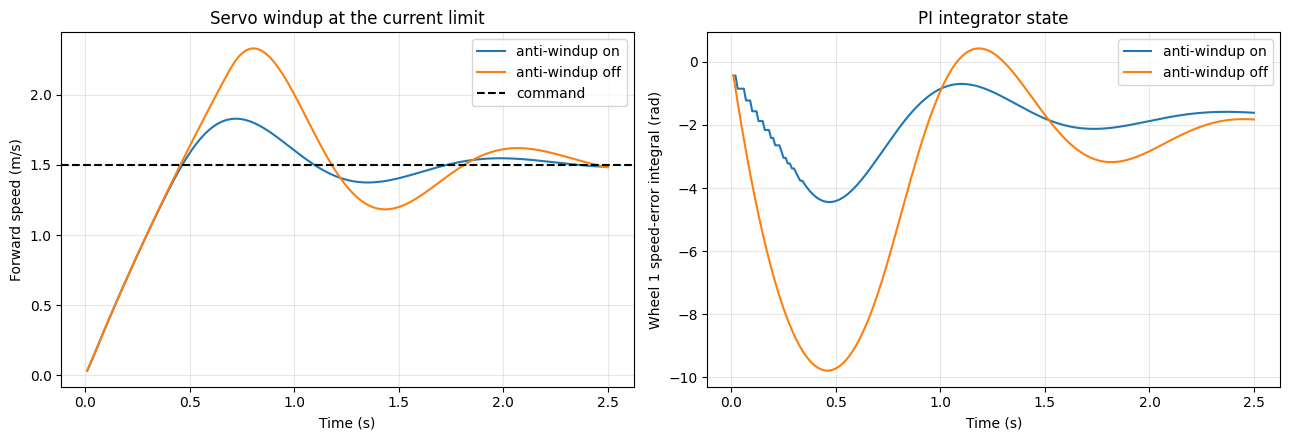

In [11]:
# Voltage-mode motor checks: driver limits, electrical energy balance, and servo windup.
# 1. An extreme request must respect the bus voltage and the current limit.
limit_sim = OpenLoopPlant(motor_mode="voltage")
for _ in range(50):
    state = limit_sim.step(np.full(4, 1e6))
    assert np.all(np.abs(state["motor_voltages"]) <= rc.MAX_MOTOR_VOLTAGE + 1e-12)
    assert np.all(np.abs(limit_sim.state[14:18]) <= rc.IQ_LIMIT + 1e-3)
print(f"PASS driver limits: |V| <= {rc.MAX_MOTOR_VOLTAGE} V and |i| <= {rc.IQ_LIMIT} A under a 1e6 rad/s request")

# 2. Energy balance including the windings:
#    d/dt (E_kin + 1/2 L sum i^2) = sum V_applied*i - R sum i^2 + wheel-loss power
#                                   + a-axis power + d-axis sliding power.
#    A wrong back-EMF sign or a missing K_t/K_e term breaks this.
def total_energy(state):
    return (0.5 * rc.ROBOT_MASS * float(state[3:5] @ state[3:5]) + 0.5 * rc.ROBOT_INERTIA * state[5] ** 2
            + 0.5 * rc.WHEEL_INERTIA * float(state[6:10] @ state[6:10])
            + 0.5 * rc.MOTOR_INDUCTANCE * float(state[14:18] @ state[14:18]))

electrical_sim = OpenLoopPlant(motor_mode="voltage")
lateral_targets = inverse_kinematics(body_command(left=0.25))
worst_electrical_error = 0.0
for k in range(int(round(0.5 / SIM_DT_S))):
    state0 = electrical_sim.state.copy()
    voltage_cmd = electrical_sim._servo_command(lateral_targets)
    applied = electrical_sim.plant.applied_voltage(state0, voltage_cmd)
    current = state0[14:18]
    _, _, force_d, force_a, slip_d, slip_a, *_ = electrical_sim.plant._contact_wrenches(state0, current, np.zeros(3))
    loss_power = wheel_loss_torque(state0[6:10]) @ state0[6:10]
    power = (applied @ current - rc.MOTOR_RESISTANCE * current @ current + loss_power
             + force_a @ slip_a + force_d @ slip_d)
    derivative = electrical_sim.plant.physical_dynamics(state0, voltage_cmd, np.zeros(3))[0]
    eps = 1e-7
    energy_rate = (total_energy(state0 + eps * derivative) - total_energy(state0 - eps * derivative)) / (2 * eps)
    worst_electrical_error = max(worst_electrical_error, abs(energy_rate - power) / max(abs(power), 1e-9))
    electrical_sim.state = electrical_sim.plant.discrete_map(state0, voltage_cmd, np.zeros(3))
assert worst_electrical_error < 1e-6, f"Electrical energy balance violated: {worst_electrical_error:.2e}"
print(f"PASS electrical + mechanical energy balance: worst relative error {worst_electrical_error:.1e}")

# 3. Windup: a forward step large enough to hold the current limit, with and without anti-windup.
windup_speed = 1.5  # m/s; saturates IQ_LIMIT for a long stretch
windup_runs = {}
for anti_windup in (True, False):
    sim = OpenLoopPlant(motor_mode="voltage", anti_windup=anti_windup)
    target = inverse_kinematics(body_command(forward=windup_speed))
    forward_speed, integral = [], []
    for k in range(int(round(2.5 / SIM_DT_S))):
        state = sim.step(target)
        forward_speed.append(state["body_velocity"][FORWARD_AXIS])
        integral.append(sim.speed_integral[0])
    windup_runs[anti_windup] = (np.array(forward_speed), np.array(integral))
for anti_windup, (speed, integral) in windup_runs.items():
    overshoot = 100 * (np.max(speed) - windup_speed) / windup_speed
    print(f"  anti-windup {'ON ' if anti_windup else 'OFF'}: peak forward speed {np.max(speed):.3f} m/s "
          f"({overshoot:+.1f}% vs {windup_speed} m/s), peak |integral| wheel 1 = {np.max(np.abs(integral)):.2f} rad")
assert np.max(windup_runs[True][0]) <= np.max(windup_runs[False][0]) + 1e-9

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
t_windup = np.arange(1, len(windup_runs[True][0]) + 1) * SIM_DT_S
for anti_windup, (speed, integral) in windup_runs.items():
    label = "anti-windup on" if anti_windup else "anti-windup off"
    axes[0].plot(t_windup, speed, label=label)
    axes[1].plot(t_windup, integral, label=label)
axes[0].axhline(windup_speed, linestyle="--", color="k", label="command")
axes[0].set_ylabel("Forward speed (m/s)"); axes[0].set_title("Servo windup at the current limit")
axes[1].set_ylabel("Wheel 1 speed-error integral (rad)"); axes[1].set_title("PI integrator state")
for ax in axes:
    ax.set_xlabel("Time (s)"); ax.grid(True, alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

## 4.2 Simple plant response verification: forward step and stop

A known forward body-velocity command (0.35 m/s) is converted to wheel-speed targets by inverse kinematics; the wheel-speed servo and the plant determine the actual response. The command steps from zero, holds for 1.5 s, then steps back to zero. The test also plots each wheel's d-axis contact slip $v_{d,i}$, the slip used by the contact law.

Expected behaviour: forward velocity rises toward the command, the robot travels straight, and after the zero command the servos brake the wheels and the chassis settles. The layout is mirror-symmetric about body $y$, so lateral velocity and yaw should be zero to round-off.

PASS: forward step-and-stop plant response
  forward displacement at stop: 0.470 m
  additional drift after stop:   0.0498 m
  max chassis speed in settle window: 0.0021 m/s
  max wheel speed in settle window:   0.061 rad/s


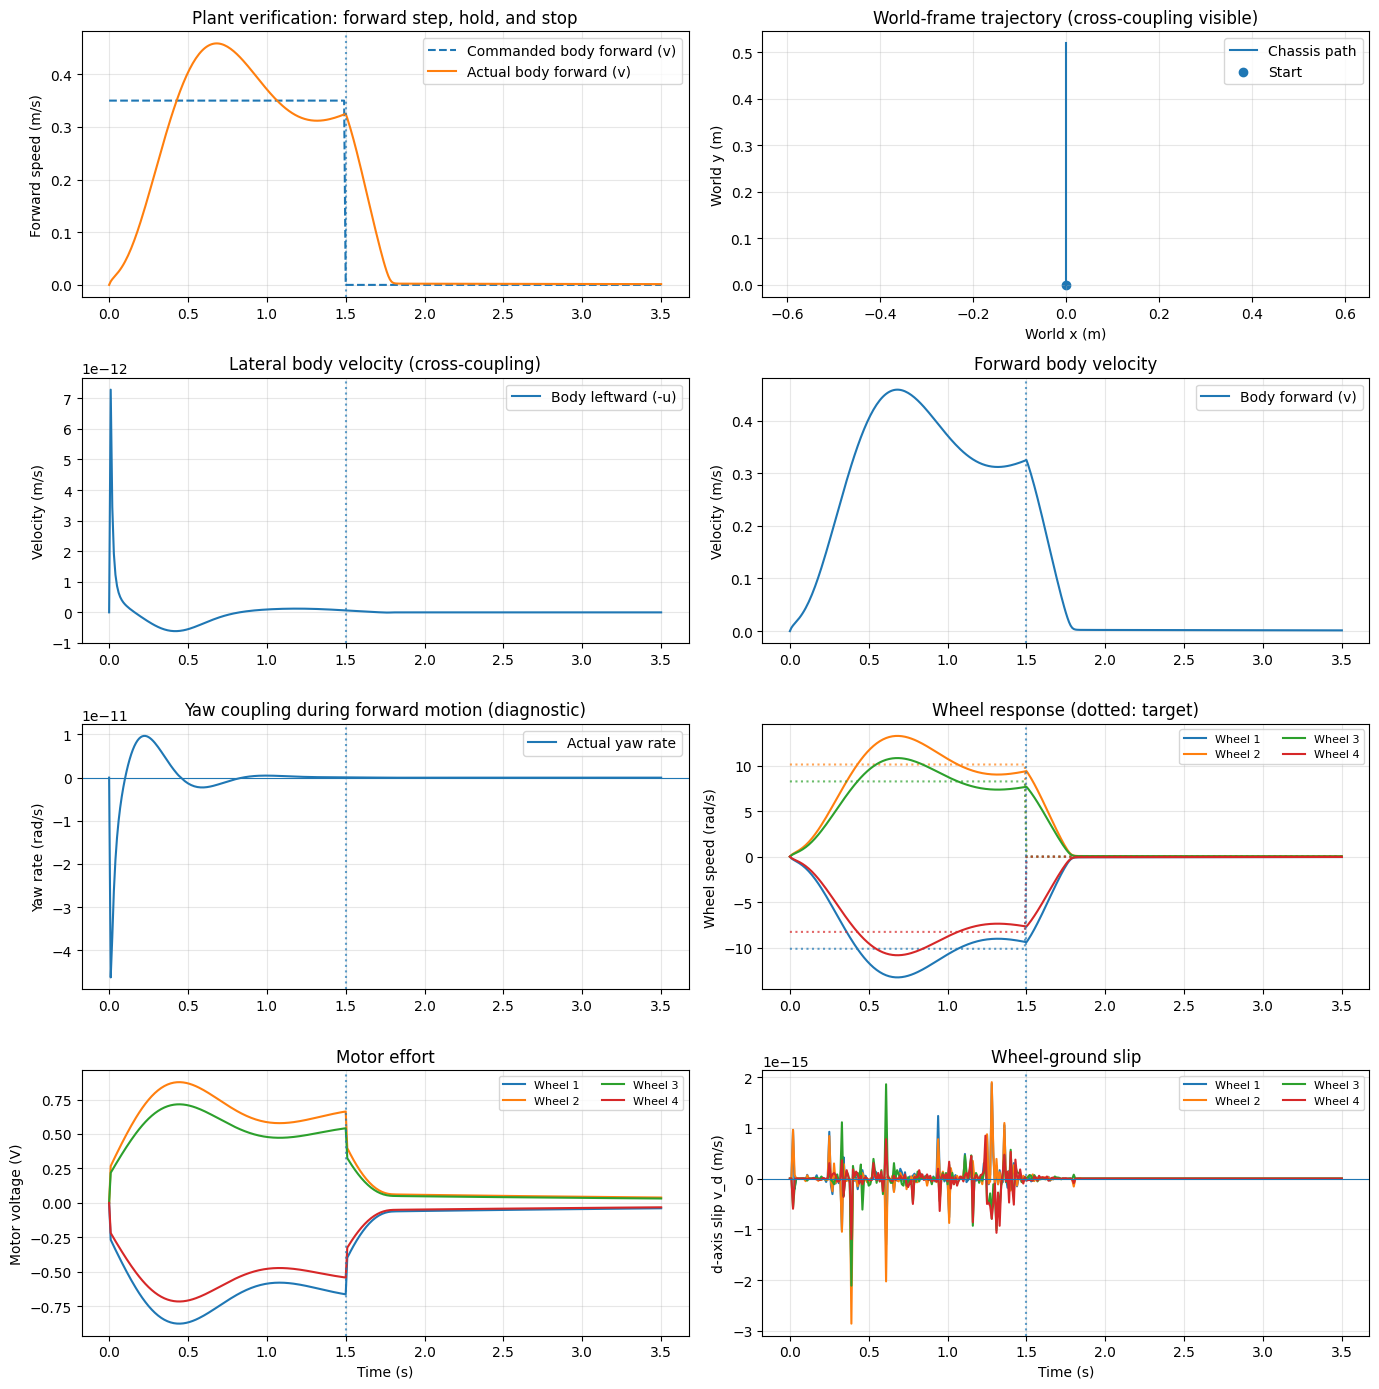

In [12]:
# Controller-independent step-and-stop test for the coupled plant (Dana section 7).
def run_forward_step_stop_test(dt=SIM_DT_S, step_speed=0.35,
                               step_duration_s=1.5, total_duration_s=3.5):
    """Command forward body speed, then zero; return plant telemetry and assert expected response."""
    if dt <= 0 or step_speed <= 0 or step_duration_s <= 0 or total_duration_s <= step_duration_s:
        raise ValueError("Require dt, step speed, and step duration > 0, and total duration > step duration.")

    # Step to a constant forward body twist, then request zero motion.
    result = run_open_loop_schedule(
        lambda t: body_command(forward=step_speed) if t < step_duration_s else body_command(),
        total_duration_s, dt=dt)
    times, pose, body_velocity = result["time"], result["pose"], result["body_velocity"]

    # Define a settling window after the stop command, excluding the exact switch instant.
    stop_idx = int(np.searchsorted(times, step_duration_s, side="left"))
    settle_start_idx = int(np.searchsorted(times, min(step_duration_s + 0.75, total_duration_s), side="left"))
    final_slice = slice(settle_start_idx, None)
    lateral_max = float(np.max(np.abs(body_velocity[:, RIGHT_AXIS])))
    yaw_rate_max = float(np.max(np.abs(body_velocity[:, 2])))
    final_speed_max = float(np.max(np.abs(body_velocity[final_slice, :2])))
    final_yaw_rate_max = float(np.max(np.abs(body_velocity[final_slice, 2])))
    final_wheel_speed_max = float(np.max(np.abs(result["wheel_speeds"][final_slice])))
    forward_displacement = float(pose[stop_idx, FORWARD_AXIS] - pose[0, FORWARD_AXIS])
    post_stop_drift = float(np.linalg.norm(pose[-1, :2] - pose[stop_idx, :2]))

    # Assertions test intended behavior, not exact time histories.
    assert forward_displacement > 0.25, f"Expected clear forward motion; got {forward_displacement:.3f} m."
    assert lateral_max < 0.02, f"Unexpected lateral body velocity: {lateral_max:.4f} m/s."
    assert yaw_rate_max < 0.02, f"Unexpected yaw rate during straight command: {yaw_rate_max:.4f} rad/s."
    assert final_speed_max < 0.03, f"Chassis did not settle after stop: {final_speed_max:.4f} m/s."
    assert final_yaw_rate_max < 0.02, f"Yaw rate did not settle: {final_yaw_rate_max:.4f} rad/s."
    assert final_wheel_speed_max < 1.0, f"Wheels did not settle after stop: {final_wheel_speed_max:.3f} rad/s."
    assert np.all(np.isfinite(pose)) and np.all(np.isfinite(body_velocity)), "Non-finite state detected."
    assert np.all(np.abs(result["motor_voltages"]) <= rc.MAX_MOTOR_VOLTAGE + 1e-10), "Motor voltage limit violated."
    assert np.all(np.abs(result["motor_currents"]) <= rc.IQ_LIMIT + 1e-3), "Motor current limit violated."
    assert np.all(np.abs(result["ground_forces"]) <= rc.MU_D_STAT * rc.F_N + 1e-8), "Contact force cap violated."

    result.update({
        "step_duration_s": step_duration_s,
        "forward_displacement_m": forward_displacement,
        "post_stop_drift_m": post_stop_drift,
        "settle_speed_max_mps": final_speed_max,
        "settle_wheel_speed_max_rad_s": final_wheel_speed_max,
    })
    return result

step_stop_result = run_forward_step_stop_test()
print("PASS: forward step-and-stop plant response")
print(f"  forward displacement at stop: {step_stop_result['forward_displacement_m']:.3f} m")
print(f"  additional drift after stop:   {step_stop_result['post_stop_drift_m']:.4f} m")
print(f"  max chassis speed in settle window: {step_stop_result['settle_speed_max_mps']:.4f} m/s")
print(f"  max wheel speed in settle window:   {step_stop_result['settle_wheel_speed_max_rad_s']:.3f} rad/s")

# Plot command tracking, world path, body-axis coupling, wheels, motor effort, and slip
# (same layout as the lateral test).
t = step_stop_result["time"]
stop_t = step_stop_result["step_duration_s"]
fig, axes = plt.subplots(4, 2, figsize=(14, 14))
axes[0,0].plot(t, step_stop_result["body_command"][:, FORWARD_AXIS], "--", label="Commanded body forward (v)")
axes[0,0].plot(t, step_stop_result["body_velocity"][:, FORWARD_AXIS], label="Actual body forward (v)")
axes[0,0].set_ylabel("Forward speed (m/s)")
axes[0,0].set_title("Plant verification: forward step, hold, and stop")
axes[0,0].legend()
axes[0,1].plot(step_stop_result["pose"][:,0], step_stop_result["pose"][:,1], label="Chassis path")
axes[0,1].scatter([step_stop_result["pose"][0,0]], [step_stop_result["pose"][0,1]], marker="o", label="Start")
axes[0,1].set_xlabel("World x (m)"); axes[0,1].set_ylabel("World y (m)")
axes[0,1].set_title("World-frame trajectory (cross-coupling visible)"); axes[0,1].axis("equal"); axes[0,1].legend()
axes[1,0].plot(t, -step_stop_result["body_velocity"][:, RIGHT_AXIS], label="Body leftward (-u)")
axes[1,0].set_ylabel("Velocity (m/s)"); axes[1,0].set_title("Lateral body velocity (cross-coupling)"); axes[1,0].legend()
axes[1,1].plot(t, step_stop_result["body_velocity"][:, FORWARD_AXIS], label="Body forward (v)")
axes[1,1].set_ylabel("Velocity (m/s)"); axes[1,1].set_title("Forward body velocity"); axes[1,1].legend()
axes[2,0].plot(t, step_stop_result["body_velocity"][:,2], label="Actual yaw rate")
axes[2,0].axhline(0, linewidth=0.8); axes[2,0].set_ylabel("Yaw rate (rad/s)"); axes[2,0].set_title("Yaw coupling during forward motion (diagnostic)"); axes[2,0].legend()
for i in range(4):
    axes[2,1].plot(t, step_stop_result["wheel_speeds"][:,i], label=f"Wheel {i+1}")
    axes[2,1].plot(t, step_stop_result["wheel_command"][:,i], linestyle=":", alpha=0.7, color=axes[2,1].lines[-1].get_color())
axes[2,1].set_ylabel("Wheel speed (rad/s)"); axes[2,1].set_title("Wheel response (dotted: target)"); axes[2,1].legend(ncol=2, fontsize=8)
for i in range(4):
    axes[3,0].plot(t, step_stop_result["motor_voltages"][:,i], label=f"Wheel {i+1}")
axes[3,0].set_xlabel("Time (s)"); axes[3,0].set_ylabel("Motor voltage (V)"); axes[3,0].set_title("Motor effort"); axes[3,0].legend(ncol=2, fontsize=8)
for i in range(4):
    axes[3,1].plot(t, step_stop_result["slip_speeds"][:,i], label=f"Wheel {i+1}")
axes[3,1].axhline(0, linewidth=0.8); axes[3,1].set_xlabel("Time (s)"); axes[3,1].set_ylabel("d-axis slip v_d (m/s)"); axes[3,1].set_title("Wheel-ground slip"); axes[3,1].legend(ncol=2, fontsize=8)
for ax in axes.flat:
    if ax is not axes[0,1]:
        ax.axvline(stop_t, linestyle=":", alpha=0.7)
    ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

## 4.3 Lateral step response: left → right → stop

This mirrors the forward test for sideways motion: 0.25 m/s left for 1 s, 0.25 m/s right for 1 s, then zero for 2 s. Left is body $-x$ here. The front (30°) and rear (45°) wheel angles differ, so yaw and forward cross-coupling are measured and reported rather than assumed to be zero.

PASS: lateral left -> right -> stop step response
  peak leftward velocity during left command:  0.298 m/s
  peak leftward velocity during right command: -0.141 m/s
  world leftward change during left phase:  0.113 m
  world leftward change during right phase: 0.013 m
  settle-window planar speed max:    0.0139 m/s
  settle-window yaw-rate max (coupling diagnostic): 0.0123 rad/s
  settle-window wheel-speed max:     0.3203 rad/s


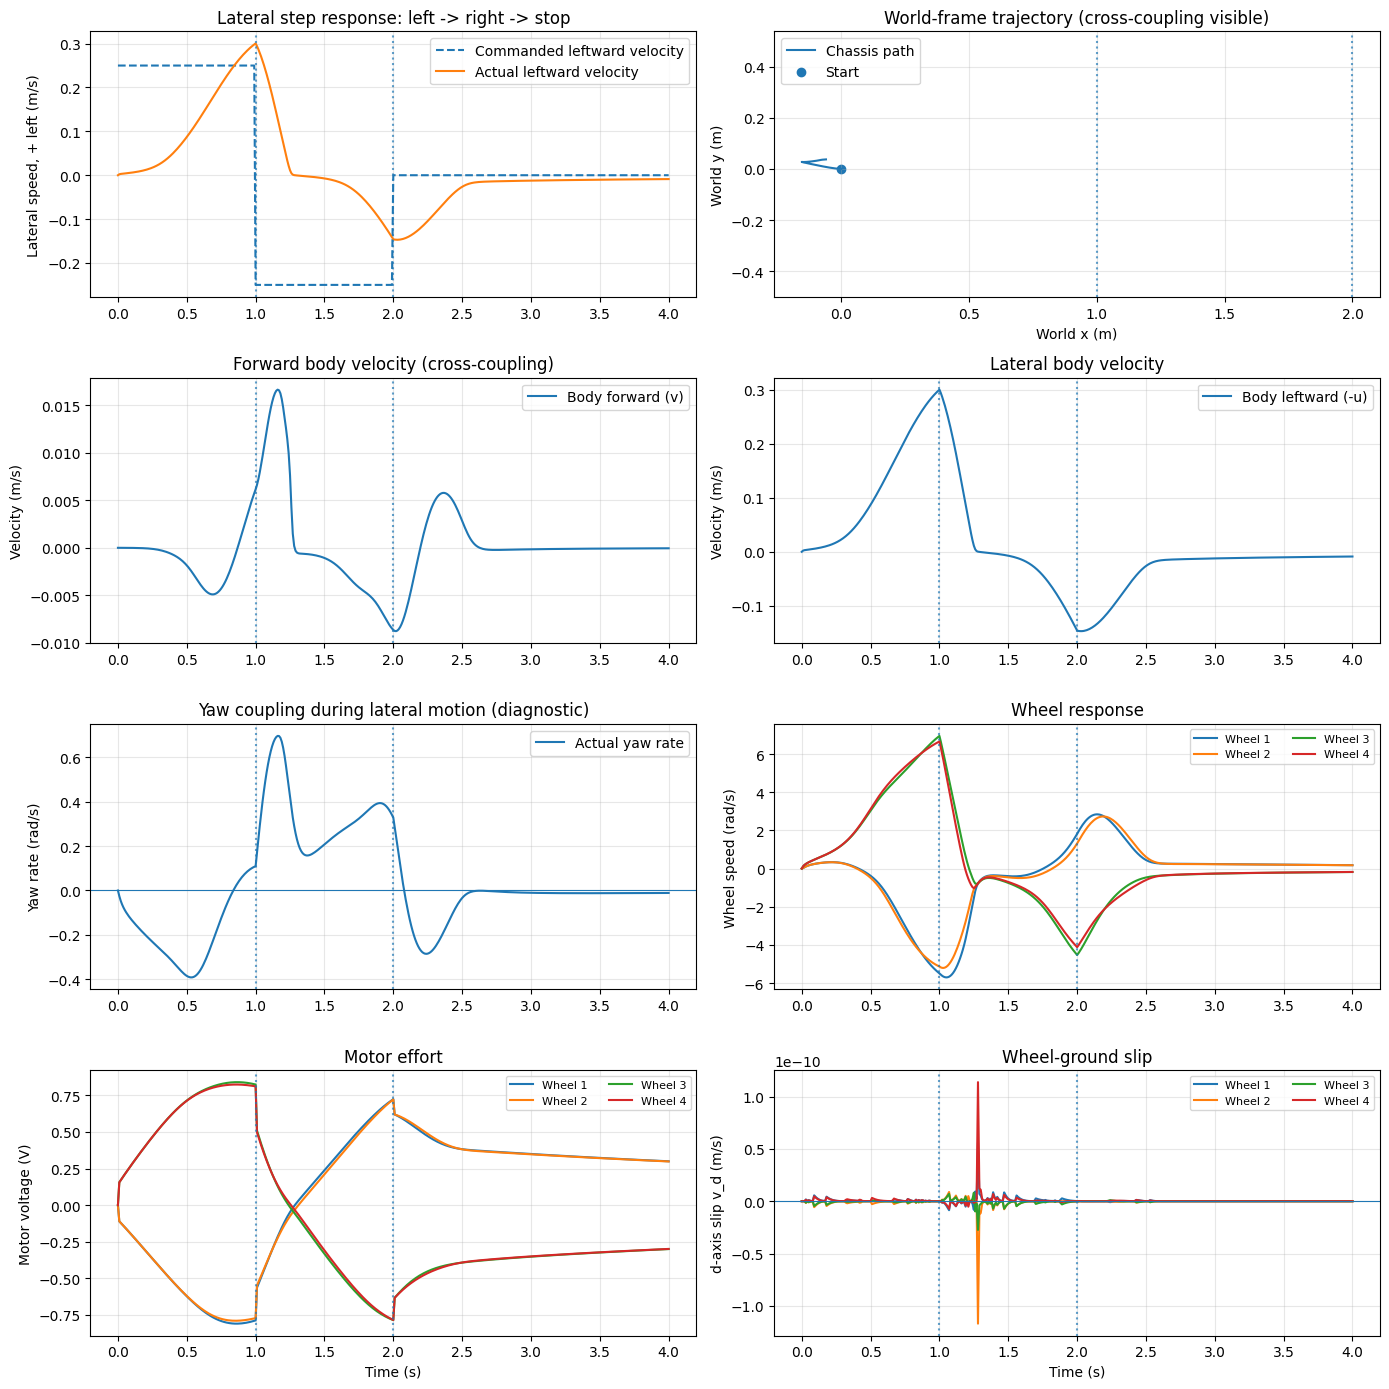

In [13]:
# Controller-independent lateral step response: left -> right -> stop (Dana section 7.1).
def run_lateral_left_right_stop_test(dt=SIM_DT_S, lateral_speed=0.25,
                                    left_duration_s=1.0, right_duration_s=1.0,
                                    stop_duration_s=2.0):
    """Command left body velocity, then right, then stop. Left is body -x in this notebook."""
    if dt <= 0 or lateral_speed <= 0 or min(left_duration_s, right_duration_s, stop_duration_s) <= 0:
        raise ValueError("dt, lateral_speed, and all phase durations must be positive.")
    total_duration_s = left_duration_s + right_duration_s + stop_duration_s

    def command(t):
        if t < left_duration_s:
            return body_command(left=lateral_speed)        # left
        if t < left_duration_s + right_duration_s:
            return body_command(left=-lateral_speed)       # right
        return body_command()                              # stop

    result = run_open_loop_schedule(command, total_duration_s, dt=dt)
    times, pose, body_velocity = result["time"], result["pose"], result["body_velocity"]
    left_velocity = -body_velocity[:, RIGHT_AXIS]

    left_mask = times < left_duration_s
    right_mask = (times >= left_duration_s) & (times < left_duration_s + right_duration_s)
    settle_start = left_duration_s + right_duration_s + min(0.75, stop_duration_s * 0.5)
    settle_mask = times >= settle_start
    peak_left_vy = float(np.max(left_velocity[left_mask]))
    peak_right_vy = float(np.min(left_velocity[right_mask]))
    final_xy_speed_max = float(np.max(np.linalg.norm(body_velocity[settle_mask, :2], axis=1)))
    final_yaw_rate_max = float(np.max(np.abs(body_velocity[settle_mask, 2])))
    final_wheel_speed_max = float(np.max(np.abs(result["wheel_speeds"][settle_mask])))
    left_end_idx = int(np.argmin(np.abs(times - left_duration_s)))
    right_end_idx = int(np.argmin(np.abs(times - (left_duration_s + right_duration_s))))
    # World "left" at the start pose is world -x.
    left_world_change = float(-(pose[left_end_idx, 0] - pose[0, 0]))
    right_world_change = float(-(pose[right_end_idx, 0] - pose[left_end_idx, 0]))

    assert np.all(np.isfinite(pose)) and np.all(np.isfinite(body_velocity)), "Non-finite state detected."
    assert peak_left_vy > 0.08, f"Left command did not produce leftward velocity (peak {peak_left_vy:.3f} m/s)."
    assert peak_right_vy < -0.08, f"Right command did not reverse lateral velocity (peak {peak_right_vy:.3f} m/s)."
    assert left_world_change > 0.03, f"Expected leftward world movement in left phase; got {left_world_change:.3f} m."
    assert final_xy_speed_max < 0.08, f"Robot did not settle after stop: final planar speed max={final_xy_speed_max:.3f} m/s."
    assert final_yaw_rate_max < 0.50, f"Yaw cross-coupling became unexpectedly large: settle-window yaw-rate max={final_yaw_rate_max:.3f} rad/s."
    assert final_wheel_speed_max < 1.0, f"Wheels did not settle after stop: {final_wheel_speed_max:.3f} rad/s."
    assert np.all(np.abs(result["motor_voltages"]) <= rc.MAX_MOTOR_VOLTAGE + 1e-10), "Motor voltage limit violated."
    assert np.all(np.abs(result["motor_currents"]) <= rc.IQ_LIMIT + 1e-3), "Motor current limit violated."
    assert np.all(np.abs(result["ground_forces"]) <= rc.MU_D_STAT * rc.F_N + 1e-8), "Contact force cap violated."

    result.update({
        "left_velocity": left_velocity,
        "left_duration_s": left_duration_s, "right_duration_s": right_duration_s,
        "left_world_change_m": left_world_change,
        "right_world_change_m": right_world_change,
        "peak_left_vy_mps": peak_left_vy, "peak_right_vy_mps": peak_right_vy,
        "settle_planar_speed_max_mps": final_xy_speed_max,
        "settle_yaw_rate_max_rad_s": final_yaw_rate_max,
        "settle_wheel_speed_max_rad_s": final_wheel_speed_max,
    })
    return result

lateral_result = run_lateral_left_right_stop_test()
print("PASS: lateral left -> right -> stop step response")
print(f"  peak leftward velocity during left command:  {lateral_result['peak_left_vy_mps']:.3f} m/s")
print(f"  peak leftward velocity during right command: {lateral_result['peak_right_vy_mps']:.3f} m/s")
print(f"  world leftward change during left phase:  {lateral_result['left_world_change_m']:.3f} m")
print(f"  world leftward change during right phase: {lateral_result['right_world_change_m']:.3f} m")
print(f"  settle-window planar speed max:    {lateral_result['settle_planar_speed_max_mps']:.4f} m/s")
print(f"  settle-window yaw-rate max (coupling diagnostic): {lateral_result['settle_yaw_rate_max_rad_s']:.4f} rad/s")
print(f"  settle-window wheel-speed max:     {lateral_result['settle_wheel_speed_max_rad_s']:.4f} rad/s")

# Plot command tracking, world path, body-axis coupling, wheels, motor effort, and slip.
t = lateral_result["time"]
t_left = lateral_result["left_duration_s"]
t_right = t_left + lateral_result["right_duration_s"]
fig, axes = plt.subplots(4, 2, figsize=(14, 14))
axes[0,0].plot(t, -lateral_result["body_command"][:, RIGHT_AXIS], "--", label="Commanded leftward velocity")
axes[0,0].plot(t, lateral_result["left_velocity"], label="Actual leftward velocity")
axes[0,0].set_ylabel("Lateral speed, + left (m/s)")
axes[0,0].set_title("Lateral step response: left -> right -> stop")
axes[0,0].legend()
axes[0,1].plot(lateral_result["pose"][:,0], lateral_result["pose"][:,1], label="Chassis path")
axes[0,1].scatter([lateral_result["pose"][0,0]], [lateral_result["pose"][0,1]], marker="o", label="Start")
axes[0,1].set_xlabel("World x (m)"); axes[0,1].set_ylabel("World y (m)")
axes[0,1].set_title("World-frame trajectory (cross-coupling visible)"); axes[0,1].axis("equal"); axes[0,1].legend()
axes[1,0].plot(t, lateral_result["body_velocity"][:, FORWARD_AXIS], label="Body forward (v)")
axes[1,0].set_ylabel("Velocity (m/s)"); axes[1,0].set_title("Forward body velocity (cross-coupling)"); axes[1,0].legend()
axes[1,1].plot(t, lateral_result["left_velocity"], label="Body leftward (-u)")
axes[1,1].set_ylabel("Velocity (m/s)"); axes[1,1].set_title("Lateral body velocity"); axes[1,1].legend()
axes[2,0].plot(t, lateral_result["body_velocity"][:,2], label="Actual yaw rate")
axes[2,0].axhline(0, linewidth=0.8); axes[2,0].set_ylabel("Yaw rate (rad/s)"); axes[2,0].set_title("Yaw coupling during lateral motion (diagnostic)"); axes[2,0].legend()
for i in range(4):
    axes[2,1].plot(t, lateral_result["wheel_speeds"][:,i], label=f"Wheel {i+1}")
axes[2,1].set_ylabel("Wheel speed (rad/s)"); axes[2,1].set_title("Wheel response"); axes[2,1].legend(ncol=2, fontsize=8)
for i in range(4):
    axes[3,0].plot(t, lateral_result["motor_voltages"][:,i], label=f"Wheel {i+1}")
axes[3,0].set_xlabel("Time (s)"); axes[3,0].set_ylabel("Motor voltage (V)"); axes[3,0].set_title("Motor effort"); axes[3,0].legend(ncol=2, fontsize=8)
for i in range(4):
    axes[3,1].plot(t, lateral_result["slip_speeds"][:,i], label=f"Wheel {i+1}")
axes[3,1].axhline(0, linewidth=0.8); axes[3,1].set_xlabel("Time (s)"); axes[3,1].set_ylabel("d-axis slip v_d (m/s)"); axes[3,1].set_title("Wheel-ground slip"); axes[3,1].legend(ncol=2, fontsize=8)
for ax in axes.flat:
    ax.axvline(t_left, linestyle=":", alpha=0.7)
    ax.axvline(t_right, linestyle=":", alpha=0.7)
    ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

## 4.4 Additional independent plant verification checks

1. **Zero-input equilibrium:** with zero initial velocity and a zero wheel-speed command, the robot stays at rest.
2. **Lateral and yaw step responses:** each body axis separately (0.25 m/s left, 0.8 rad/s yaw), with cross-axis leakage plotted.
3. **Right → left → stop:** −0.6 rad/s for 1 s, +0.6 rad/s for 1 s, then zero. Checks yaw-rate sign reversal, heading change both ways, and residual motion after stopping.
4. **Friction ablation:** the same forward command with contact friction on and off. With friction off, the wheels spin and the chassis does not move.
5. **Timestep convergence:** the forward step/stop at `dt` = 10, 5, 2.5 and 1.25 ms. Large changes with `dt` indicate numerical error, not physics.

These are model-consistency checks, not validation against measured hardware data.

PASS: zero-input equilibrium — pose, chassis velocity, and wheel speeds remain zero.
PASS: lateral/yaw response is finite and produces the commanded-axis motion.
  lateral test peak |yaw rate| (cross-axis diagnostic): 0.408 rad/s
  yaw test final heading: 0.800 rad; final translation: 0.0000 m


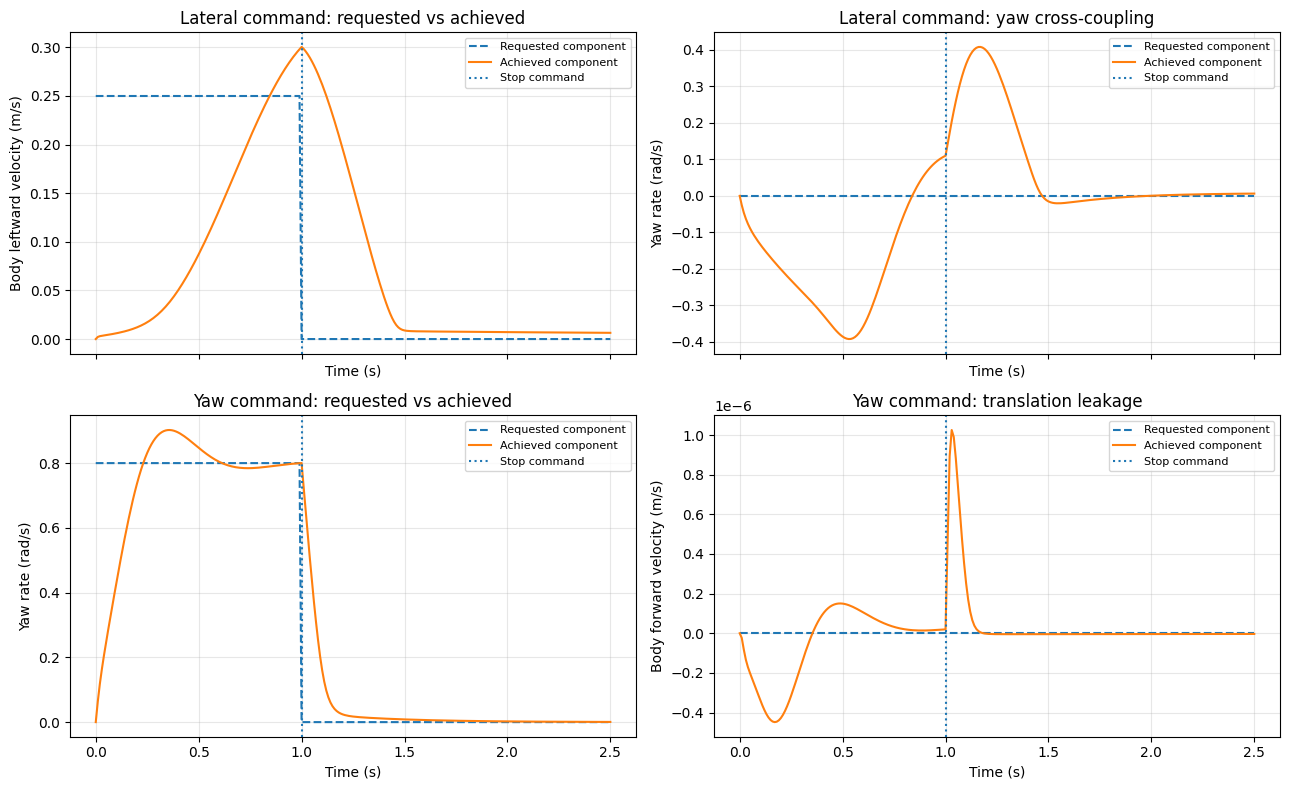

PASS: right -> left -> stop — yaw direction reverses, heading responds both ways, and motion settles.
  peak yaw rate during right command: -0.654 rad/s
  peak yaw rate during left command:  0.653 rad/s
  heading after right: -0.542 rad; after left: -0.057 rad; final: -0.000 rad
  final body-speed norm: 0.0003; max final wheel speed: 0.0009 rad/s


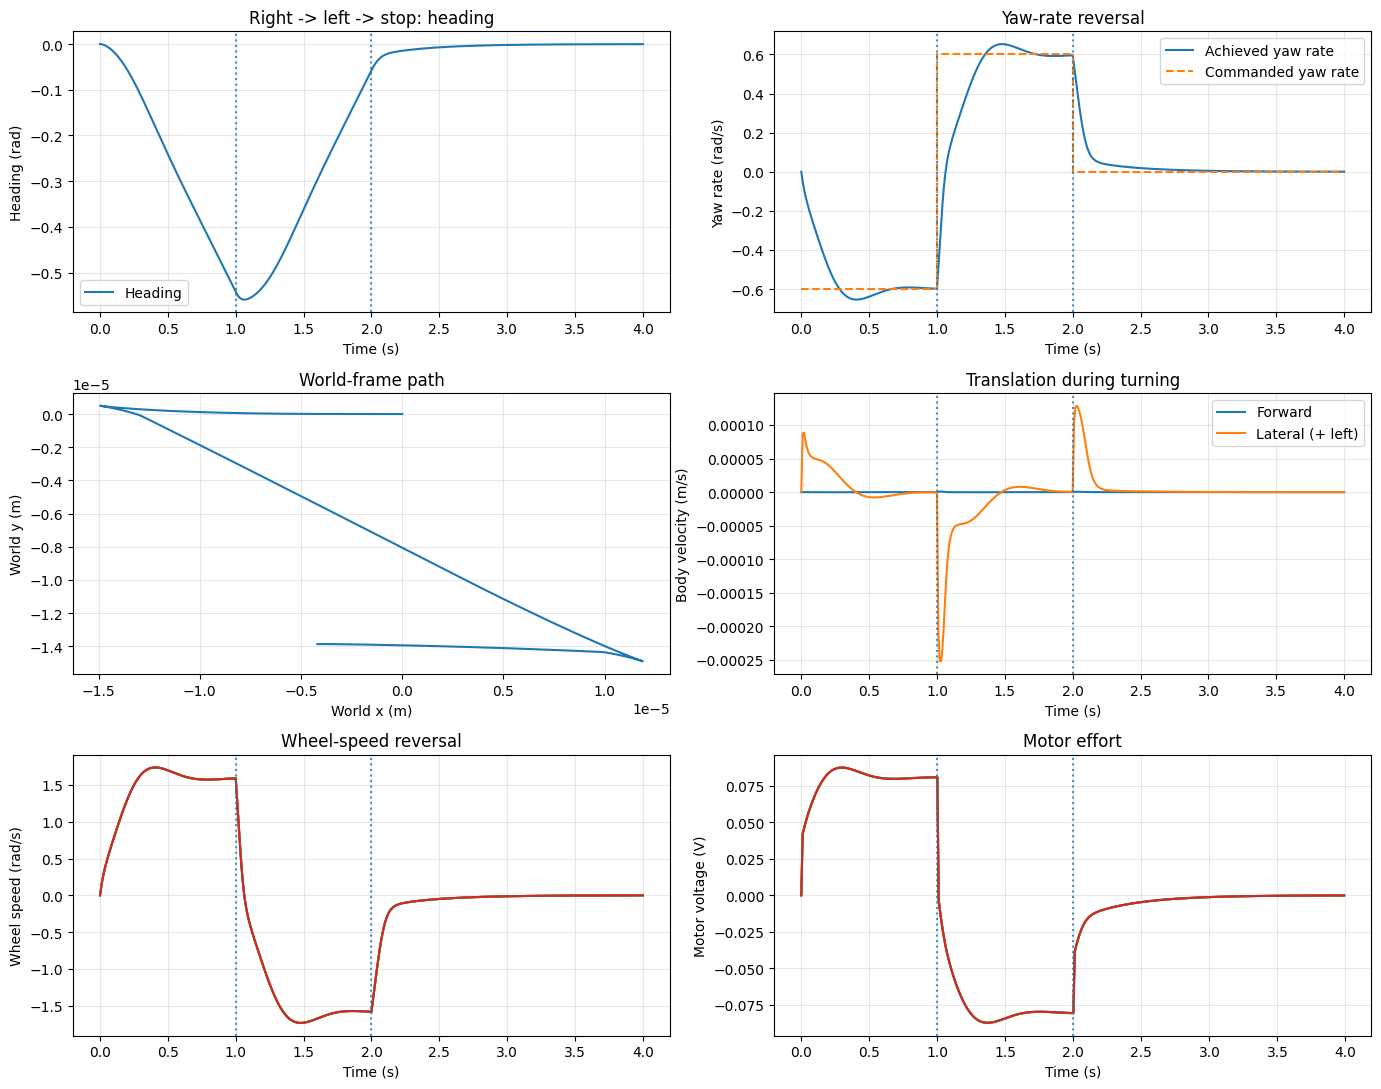

PASS: friction ablation — traction moves the chassis; friction-off wheels spin without chassis motion.


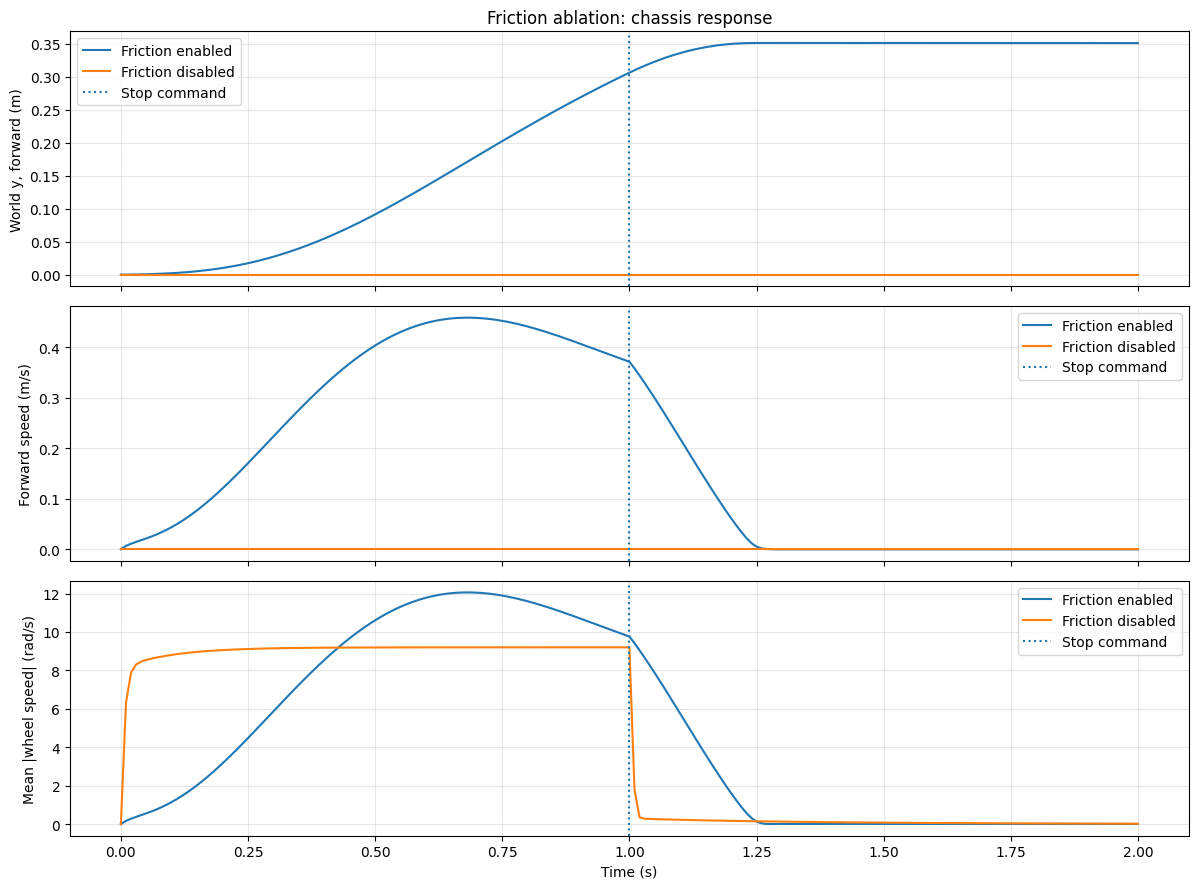

  dt=0.01000 s | forward at stop=0.46957 m | post-stop drift=0.04983 m | peak |yaw rate|=0.00000 rad/s | displacement delta vs finest=0.00144 m
  dt=0.00500 s | forward at stop=0.46875 m | post-stop drift=0.05045 m | peak |yaw rate|=0.00000 rad/s | displacement delta vs finest=0.00061 m
  dt=0.00250 s | forward at stop=0.46834 m | post-stop drift=0.05077 m | peak |yaw rate|=0.00000 rad/s | displacement delta vs finest=0.00020 m
  dt=0.00125 s | forward at stop=0.46814 m | post-stop drift=0.05092 m | peak |yaw rate|=0.00000 rad/s | displacement delta vs finest=0.00000 m
PASS: finest-step displacement converges within 2 mm; coarse-step deviation is reported above.


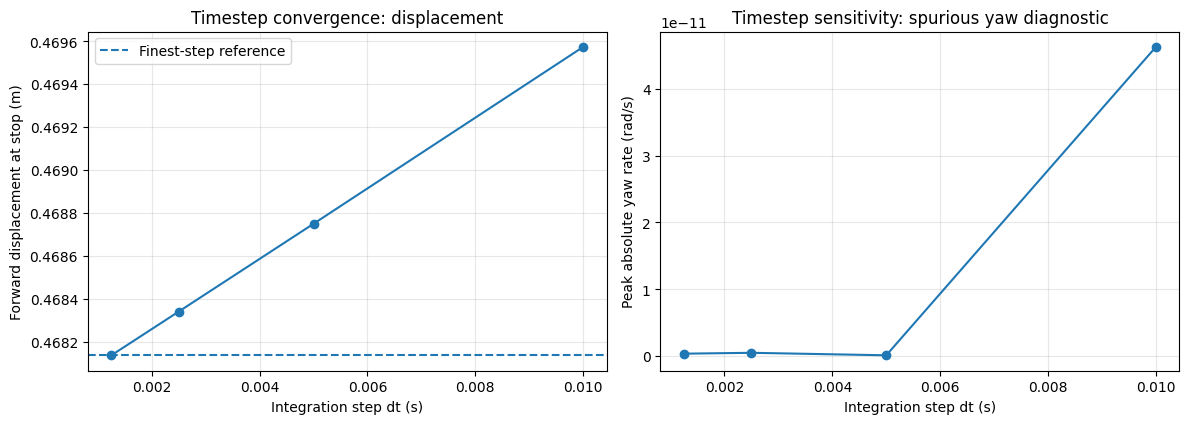

In [14]:
# Verification helpers and tests (Dana section 7.1, additional checks). Keep these separate from PID/MPC.
def run_open_loop_body_step(command, duration_s=2.5, step_duration_s=1.0,
                            dt=SIM_DT_S, enable_friction=True):
    """Apply a body-twist step through inverse kinematics and the wheel-speed servo/plant."""
    if dt <= 0 or duration_s <= step_duration_s or step_duration_s <= 0:
        raise ValueError("Require dt > 0 and duration_s > step_duration_s > 0.")
    command = np.asarray(command, dtype=float)
    result = run_open_loop_schedule(
        lambda t: command if t < step_duration_s else body_command(),
        duration_s, dt=dt, enable_friction=enable_friction)
    result["velocity"] = result["body_velocity"]
    result["step_duration_s"] = step_duration_s
    return result

# Check 1: zero-input equilibrium (no controller and no external disturbance).
zero_sim = OpenLoopPlant()
zero_pose0 = zero_sim.state[0:3].copy()
for _ in range(500):
    zero_state = zero_sim.step(np.zeros(4))
assert np.allclose(zero_state["pose"], zero_pose0, atol=1e-12)
assert np.allclose(zero_state["body_velocity"], 0.0, atol=1e-12)
assert np.allclose(zero_state["wheel_speeds"], 0.0, atol=1e-12)
print("PASS: zero-input equilibrium — pose, chassis velocity, and wheel speeds remain zero.")

# Check 2: lateral and yaw responses. Lateral cross-coupling is measured, not hidden.
LATERAL_STEP_SPEED = 0.25
YAW_STEP_RATE = 0.8
lateral_step_result = run_open_loop_body_step(body_command(left=LATERAL_STEP_SPEED))
yaw_result = run_open_loop_body_step(body_command(yaw_rate=YAW_STEP_RATE))
assert np.all(np.isfinite(lateral_step_result["pose"])) and np.all(np.isfinite(lateral_step_result["velocity"]))
assert np.all(np.isfinite(yaw_result["pose"])) and np.all(np.isfinite(yaw_result["velocity"]))
assert abs(lateral_step_result["pose"][-1, 0]) > 0.10, "Lateral command produced too little lateral displacement."
assert abs(yaw_result["pose"][-1, 2]) > 0.50, "Yaw command produced too little heading change."
yaw_translation = float(np.linalg.norm(yaw_result["pose"][-1, :2]))
assert yaw_translation < 0.05, f"Pure-yaw command caused unexpectedly large translation ({yaw_translation:.3f} m)."
lat_cross_yaw = float(np.max(np.abs(lateral_step_result["velocity"][:, 2])))
print("PASS: lateral/yaw response is finite and produces the commanded-axis motion.")
print(f"  lateral test peak |yaw rate| (cross-axis diagnostic): {lat_cross_yaw:.3f} rad/s")
print(f"  yaw test final heading: {yaw_result['pose'][-1, 2]:.3f} rad; final translation: {yaw_translation:.4f} m")

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
for ax, result, axis, sign, requested, title, ylabel in [
    (axes[0,0], lateral_step_result, RIGHT_AXIS, -1.0, LATERAL_STEP_SPEED,
     "Lateral command: requested vs achieved", "Body leftward velocity (m/s)"),
    (axes[0,1], lateral_step_result, 2, 1.0, 0.0, "Lateral command: yaw cross-coupling", "Yaw rate (rad/s)"),
    (axes[1,0], yaw_result, 2, 1.0, YAW_STEP_RATE, "Yaw command: requested vs achieved", "Yaw rate (rad/s)"),
    (axes[1,1], yaw_result, FORWARD_AXIS, 1.0, 0.0, "Yaw command: translation leakage", "Body forward velocity (m/s)")]:
    tt = result["time"]
    command_trace = np.where(tt < result["step_duration_s"], requested, 0.0)
    ax.plot(tt, command_trace, linestyle="--", label="Requested component")
    ax.plot(tt, sign * result["velocity"][:, axis], label="Achieved component")
    ax.axvline(result["step_duration_s"], linestyle=":", label="Stop command")
    ax.set_title(title); ax.set_ylabel(ylabel); ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
for ax in axes.flat: ax.set_xlabel("Time (s)")
plt.tight_layout(); plt.show()

# Check 3: right turn -> left turn -> stop. This is an open-loop body-command test,
# with the same inverse kinematics, wheel-speed PI, current limit, and plant as other checks.
right_duration_s = 1.0
left_duration_s = 1.0
turn_stop_duration_s = 2.0
turn_total_s = right_duration_s + left_duration_s + turn_stop_duration_s
turn_rate_cmd = 0.60  # rad/s; right is negative yaw, left is positive yaw by convention

def turn_command(t):
    if t < right_duration_s:
        return body_command(yaw_rate=-turn_rate_cmd)
    if t < right_duration_s + left_duration_s:
        return body_command(yaw_rate=turn_rate_cmd)
    return body_command()

turn_result = run_open_loop_schedule(turn_command, turn_total_s)
turn_time = turn_result["time"]
turn_poses = turn_result["pose"]
turn_velocities = turn_result["body_velocity"]
turn_wheels = turn_result["wheel_speeds"]
turn_voltages = turn_result["motor_voltages"]
turn_commands = turn_result["body_command"][:-1]
right_mask = turn_time[:-1] < right_duration_s
left_mask = (turn_time[:-1] >= right_duration_s) & (turn_time[:-1] < right_duration_s + left_duration_s)
right_peak_yaw = float(np.min(turn_velocities[:-1, 2][right_mask]))
left_peak_yaw = float(np.max(turn_velocities[:-1, 2][left_mask]))
heading_after_right = float(turn_poses[np.argmin(np.abs(turn_time-right_duration_s)), 2])
heading_after_left = float(turn_poses[np.argmin(np.abs(turn_time-(right_duration_s+left_duration_s))), 2])
final_speed = float(np.linalg.norm(turn_velocities[-1]))
final_wheel_speed = float(np.max(np.abs(turn_wheels[-1])))
assert np.all(np.isfinite(turn_poses)) and np.all(np.isfinite(turn_velocities))
assert right_peak_yaw < -0.10, f"Right-turn command did not produce negative yaw rate (peak {right_peak_yaw:.3f} rad/s)."
assert left_peak_yaw > 0.10, f"Left-turn command did not reverse yaw rate (peak {left_peak_yaw:.3f} rad/s)."
assert heading_after_right < -0.10, f"Heading did not change in the right-turn direction ({heading_after_right:.3f} rad)."
assert heading_after_left > heading_after_right + 0.10, "Heading did not reverse direction during the left-turn phase."
assert final_speed < 0.08, f"Robot did not settle after stop: final body-speed norm={final_speed:.3f} m/s/rad/s."
assert final_wheel_speed < 1.0, f"Wheel speeds remain high after stop: {final_wheel_speed:.3f} rad/s."
print("PASS: right -> left -> stop — yaw direction reverses, heading responds both ways, and motion settles.")
print(f"  peak yaw rate during right command: {right_peak_yaw:.3f} rad/s")
print(f"  peak yaw rate during left command:  {left_peak_yaw:.3f} rad/s")
print(f"  heading after right: {heading_after_right:.3f} rad; after left: {heading_after_left:.3f} rad; final: {turn_poses[-1,2]:.3f} rad")
print(f"  final body-speed norm: {final_speed:.4f}; max final wheel speed: {final_wheel_speed:.4f} rad/s")

fig, axes = plt.subplots(3, 2, figsize=(14, 11))
axes[0,0].plot(turn_time, turn_poses[:,2], label="Heading")
axes[0,0].set_ylabel("Heading (rad)"); axes[0,0].set_title("Right -> left -> stop: heading"); axes[0,0].legend()
axes[0,1].plot(turn_time, turn_velocities[:,2], label="Achieved yaw rate")
axes[0,1].step(turn_time[:-1], turn_commands[:,2], where="post", linestyle="--", label="Commanded yaw rate")
axes[0,1].set_ylabel("Yaw rate (rad/s)"); axes[0,1].set_title("Yaw-rate reversal"); axes[0,1].legend()
axes[1,0].plot(turn_poses[:,0], turn_poses[:,1])
axes[1,0].set_xlabel("World x (m)"); axes[1,0].set_ylabel("World y (m)"); axes[1,0].set_title("World-frame path")
axes[1,1].plot(turn_time, turn_velocities[:,FORWARD_AXIS], label="Forward")
axes[1,1].plot(turn_time, -turn_velocities[:,RIGHT_AXIS], label="Lateral (+ left)")
axes[1,1].set_ylabel("Body velocity (m/s)"); axes[1,1].set_title("Translation during turning"); axes[1,1].legend()
axes[2,0].plot(turn_time, turn_wheels)
axes[2,0].set_ylabel("Wheel speed (rad/s)"); axes[2,0].set_title("Wheel-speed reversal")
axes[2,1].plot(turn_time[:-1], turn_voltages[:-1])
axes[2,1].set_ylabel("Motor voltage (V)"); axes[2,1].set_title("Motor effort")
for ax in axes.flat:
    if ax is not axes[1,0]:
        ax.axvline(right_duration_s, linestyle=":", alpha=0.8)
        ax.axvline(right_duration_s + left_duration_s, linestyle=":", alpha=0.8)
    ax.grid(True, alpha=0.3)
for ax in (axes[0,0], axes[0,1], axes[1,1], axes[2,0], axes[2,1]): ax.set_xlabel("Time (s)")
plt.tight_layout(); plt.show()

# Check 4: friction ablation. Identical command, only contact-force transmission differs.
friction_on = run_open_loop_body_step(body_command(forward=0.35), duration_s=2.0,
                                      step_duration_s=1.0, enable_friction=True)
friction_off = run_open_loop_body_step(body_command(forward=0.35), duration_s=2.0,
                                       step_duration_s=1.0, enable_friction=False)
assert abs(friction_on["pose"][-1, FORWARD_AXIS]) > 0.10, "With friction enabled, forward traction should move the chassis."
assert np.max(np.abs(friction_off["pose"][:, :])) < 1e-12, "Friction-off ablation should transmit no chassis force."
assert np.max(np.abs(friction_off["wheel_speeds"])) > 1.0, "With friction off, wheel motors should still spin the wheels."
print("PASS: friction ablation — traction moves the chassis; friction-off wheels spin without chassis motion.")

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for result, label in [(friction_on, "Friction enabled"), (friction_off, "Friction disabled")]:
    tt = result["time"]
    axes[0].plot(tt, result["pose"][:, FORWARD_AXIS], label=label)
    axes[1].plot(tt, result["velocity"][:, FORWARD_AXIS], label=label)
    axes[2].plot(tt, np.mean(np.abs(result["wheel_speeds"]), axis=1), label=label)
for ax in axes:
    ax.axvline(1.0, linestyle=":", label="Stop command")
    ax.grid(True, alpha=0.3); ax.legend()
axes[0].set_ylabel("World y, forward (m)"); axes[0].set_title("Friction ablation: chassis response")
axes[1].set_ylabel("Forward speed (m/s)")
axes[2].set_ylabel("Mean |wheel speed| (rad/s)"); axes[2].set_xlabel("Time (s)")
plt.tight_layout(); plt.show()

# Check 5: integration-step sensitivity using the same command schedule and parameters.
# Here dt is the servo/hold interval; the plant solver inside each interval is adaptive with max_step = dt.
# Deliberately do not use run_forward_step_stop_test's pass/fail thresholds here:
# this is a numerical convergence experiment, including a coarser step that may be inaccurate.
dt_values = [0.01, 0.005, 0.0025, 0.00125]
convergence_rows = []
convergence_runs = {}
for dt_test in dt_values:
    r = run_open_loop_body_step(body_command(forward=0.35), duration_s=3.5,
                                step_duration_s=1.5, dt=dt_test, enable_friction=True)
    stop_idx = int(np.argmin(np.abs(r["time"] - 1.5)))
    displacement_at_stop = float(r["pose"][stop_idx, FORWARD_AXIS] - r["pose"][0, FORWARD_AXIS])
    post_stop_drift = float(np.linalg.norm(r["pose"][-1, :2] - r["pose"][stop_idx, :2]))
    peak_yaw_rate = float(np.max(np.abs(r["velocity"][:, 2])))
    convergence_rows.append((dt_test, displacement_at_stop, post_stop_drift, peak_yaw_rate))
    convergence_runs[dt_test] = r
reference_displacement = convergence_rows[-1][1]
for row in convergence_rows:
    print(f"  dt={row[0]:.5f} s | forward at stop={row[1]:.5f} m | post-stop drift={row[2]:.5f} m | peak |yaw rate|={row[3]:.5f} rad/s | displacement delta vs finest={abs(row[1]-reference_displacement):.5f} m")
assert abs(convergence_rows[-2][1] - convergence_rows[-1][1]) < 0.002, \
    "The two finest time steps did not converge within 2 mm; inspect integration stability/model stiffness."
print("PASS: finest-step displacement converges within 2 mm; coarse-step deviation is reported above.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot([row[0] for row in convergence_rows], [row[1] for row in convergence_rows], marker="o")
axes[0].axhline(reference_displacement, linestyle="--", label="Finest-step reference")
axes[0].set_xlabel("Integration step dt (s)"); axes[0].set_ylabel("Forward displacement at stop (m)")
axes[0].set_title("Timestep convergence: displacement"); axes[0].grid(True, alpha=0.3); axes[0].legend()
axes[1].plot([row[0] for row in convergence_rows], [row[3] for row in convergence_rows], marker="o")
axes[1].set_xlabel("Integration step dt (s)"); axes[1].set_ylabel("Peak absolute yaw rate (rad/s)")
axes[1].set_title("Timestep sensitivity: spurious yaw diagnostic"); axes[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

### Wheel directions and the equal-command check

Dana's suggested check: equal current on all four wheels should drive the robot straight, with the wheel angles cancelling in yaw. That holds for her sign convention, not for this one. Both conventions are self-consistent; they differ in what "positive" means for each motor:

- **This notebook:** every drive direction $\hat{\mathbf d}_i$ is the CCW tangent ($\hat{\mathbf a}_i$ rotated +90°), so every yaw lever is $+L$. Positive current on every wheel spins the robot. The table below shows that, plus inverse kinematics: forward motion needs the sign pattern $[-,+,+,-]$, and pure yaw needs equal speeds on all four wheels. This matches identical motors all mounted with their shafts pointing outward.
- **Dana's notebook:** the left and right drive directions are mirrored, so her yaw levers come in ± pairs (her Jacobian's third column is $[-0.52, 0.52, -2, 2]$) and equal commands cancel in yaw.

The check below therefore tests the equivalent statement in this convention, in both motor models. Equal commands must give mainly yaw, and the forward sign pattern must drive straight with zero yaw and zero lateral velocity. Which convention the firmware uses for each motor is a hardware question; switching would only flip the sign of individual wheels.

In [15]:
# Wheel directions and equal-command check, in both motor models.
drive, axle = wheel_directions_body()
radius = rc.WHEEL_ROBOT_DIST * axle
print("wheel          alpha   position r_i [m] (x right, y fwd)   drive d_i          yaw lever r_i x d_i [m]")
for i, name in enumerate(rc.WHEEL_NAMES):
    lever = radius[0, i] * drive[1, i] - radius[1, i] * drive[0, i]
    print(f"{name:12s} {rc.WHEEL_ALPHA_DEG[i]:6.0f}   [{radius[0, i]:+.4f}, {radius[1, i]:+.4f}]"
          f"                [{drive[0, i]:+.3f}, {drive[1, i]:+.3f}]   {lever:+.4f}")
for label, twist in [("forward 0.35 m/s", body_command(forward=0.35)),
                     ("left 0.25 m/s", body_command(left=0.25)),
                     ("yaw +1 rad/s (CCW)", body_command(yaw_rate=1.0))]:
    print(f"inverse kinematics, {label:18s}: wheel speeds {inverse_kinematics(twist)} rad/s")

forward_pattern = np.sign(inverse_kinematics(body_command(forward=1.0)))

def hold_command(motor_mode, pattern, duration_s=0.3):
    """Hold the same command magnitude on every wheel with a sign pattern; return the body twist."""
    if motor_mode == "current":
        plant, command = WheelSlipRobotSimulator(dt=DT, initial_state=np.zeros(14)), 2.0 * pattern       # A
    else:
        plant, command = VoltageDrivenSlipSimulator(dt=DT, initial_state=np.zeros(18)), 1.0 * pattern     # V
    state = plant.state.copy()
    for _ in range(int(round(duration_s / DT))):
        state = plant.discrete_map(state, command, np.zeros(3))
    return np.r_[world_to_body(state[3:5], state[2]), state[5]]

for motor_mode, unit in (("current", "2 A"), ("voltage", "1 V")):
    equal = hold_command(motor_mode, np.ones(N_WHEELS))
    straight = hold_command(motor_mode, forward_pattern)
    print(f"{motor_mode} mode, {unit} on every wheel for 0.3 s:          [u, v, omega] = {equal}")
    print(f"{motor_mode} mode, {unit} with forward pattern {forward_pattern}: [u, v, omega] = {straight}")
    assert abs(equal[2]) > 10 * np.max(np.abs(equal[:2])), "Equal commands should give mainly yaw in this convention"
    assert straight[FORWARD_AXIS] > 0 and abs(straight[2]) < 1e-6 and abs(straight[RIGHT_AXIS]) < 1e-6, \
        "Forward sign pattern should drive straight forward without yaw"
print("PASS: equal commands spin the robot (all d_i are CCW tangents); the forward sign pattern drives straight, no yaw.")

wheel          alpha   position r_i [m] (x right, y fwd)   drive d_i          yaw lever r_i x d_i [m]
front-right      30   [+0.0688, +0.0397]                [-0.500, +0.866]   +0.0795
front-left      150   [-0.0688, +0.0397]                [-0.500, -0.866]   +0.0795
back-left       225   [-0.0562, -0.0562]                [+0.707, -0.707]   +0.0795
back-right      315   [+0.0562, -0.0562]                [+0.707, +0.707]   +0.0795
inverse kinematics, forward 0.35 m/s  : wheel speeds [-10.13247349  10.13247349   8.27312996  -8.27312996] rad/s
inverse kinematics, left 0.25 m/s     : wheel speeds [-4.17856164 -4.17856164  5.90937854  5.90937854] rad/s
inverse kinematics, yaw +1 rad/s (CCW): wheel speeds [-2.65706377 -2.65706377 -2.65706377 -2.65706377] rad/s
current mode, 2 A on every wheel for 0.3 s:          [u, v, omega] = [-1.23345906e-03 -2.28883323e-04 -1.72656304e+01]
current mode, 2 A with forward pattern [-1.  1.  1. -1.]: [u, v, omega] = [7.04199010e-14 2.21699176e-01 1.64835775e

### Wheel-angle sweep: lateral yaw coupling

Dana's suggestion: repeat the lateral step with front/rear wheel angles 45/45, 40/45 and 30/45. Every drive force has the yaw lever $+L$, so a lateral push turns the robot in proportion to $\sum_i d_{x,i}$, which is zero when the front and rear angles match. Expected: no yaw at 45/45, and a yaw rate that grows as the front angle departs from the rear. Real robots show the same sideways-motion yaw. The sweep sets `rc.WHEEL_ALPHA_DEG` temporarily and restores it afterwards.

front 45.0 deg / rear 45.0 deg: sum_i d_x,i = -0.000; peak |yaw rate| 0.000 rad/s; final heading -0.00 deg; peak leftward speed 0.323 m/s
front 40.0 deg / rear 45.0 deg: sum_i d_x,i = +0.129; peak |yaw rate| 0.134 rad/s; final heading -0.64 deg; peak leftward speed 0.323 m/s
front 30.0 deg / rear 45.0 deg: sum_i d_x,i = +0.414; peak |yaw rate| 0.408 rad/s; final heading -3.76 deg; peak leftward speed 0.300 m/s
PASS: lateral yaw coupling is zero for 45/45 and grows as the front/rear angles differ.


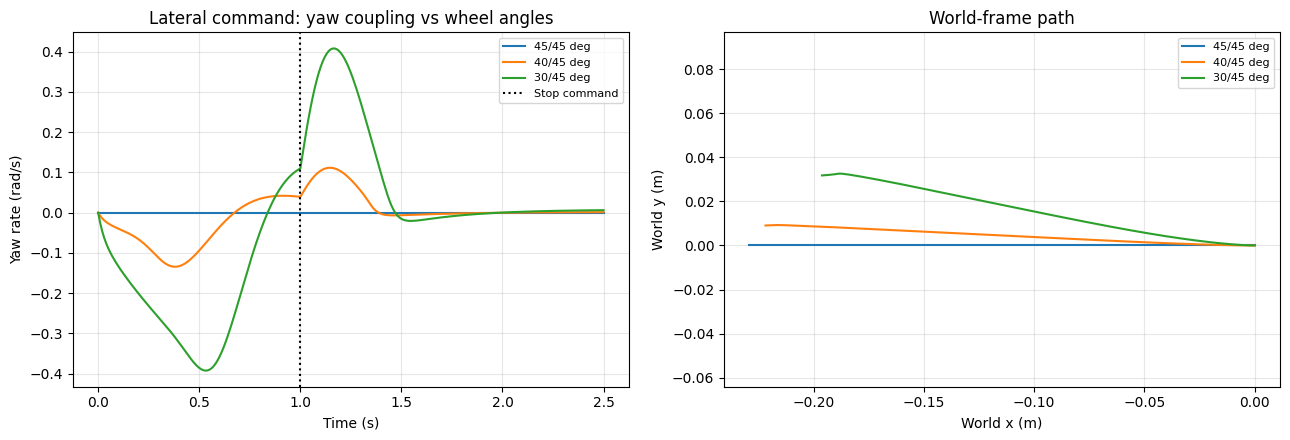

In [16]:
# Wheel-angle sweep (Dana's suggestion): the same lateral step with front/rear angles 45/45, 40/45, 30/45.
# WHEEL_ALPHA_DEG = [front, 180 - front, 180 + rear, 360 - rear]; restored afterwards.
ANGLE_SWEEP = [(45.0, 45.0), (40.0, 45.0), (30.0, 45.0)]  # (front, rear) [deg]
nominal_alpha = list(rc.WHEEL_ALPHA_DEG)
sweep_results = {}
try:
    for front, rear in ANGLE_SWEEP:
        rc.WHEEL_ALPHA_DEG = [front, 180.0 - front, 180.0 + rear, 360.0 - rear]
        drive_sweep, _ = wheel_directions_body()
        result = run_open_loop_body_step(body_command(left=LATERAL_STEP_SPEED))
        sweep_results[(front, rear)] = (result, float(drive_sweep[0].sum()))
finally:
    rc.WHEEL_ALPHA_DEG = nominal_alpha

for (front, rear), (result, sum_dx) in sweep_results.items():
    yaw = result["velocity"][:, 2]
    print(f"front {front:4.1f} deg / rear {rear:4.1f} deg: sum_i d_x,i = {sum_dx:+.3f}; "
          f"peak |yaw rate| {np.max(np.abs(yaw)):.3f} rad/s; final heading {np.degrees(result['pose'][-1, 2]):+.2f} deg; "
          f"peak leftward speed {np.max(-result['velocity'][:, RIGHT_AXIS]):.3f} m/s")
symmetric = sweep_results[(45.0, 45.0)][0]
assert np.max(np.abs(symmetric["velocity"][:, 2])) < 1e-6, "45/45 layout should give no yaw for a lateral command"
peaks = [np.max(np.abs(sweep_results[key][0]["velocity"][:, 2])) for key in ANGLE_SWEEP]
assert peaks[0] < peaks[1] < peaks[2], "Yaw coupling should grow as the front angle departs from the rear angle"
print("PASS: lateral yaw coupling is zero for 45/45 and grows as the front/rear angles differ.")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for (front, rear), (result, _) in sweep_results.items():
    axes[0].plot(result["time"], result["velocity"][:, 2], label=f"{front:.0f}/{rear:.0f} deg")
    axes[1].plot(result["pose"][:, 0], result["pose"][:, 1], label=f"{front:.0f}/{rear:.0f} deg")
axes[0].axvline(symmetric["step_duration_s"], linestyle=":", color="k", label="Stop command")
axes[0].set(xlabel="Time (s)", ylabel="Yaw rate (rad/s)", title="Lateral command: yaw coupling vs wheel angles")
axes[1].set(xlabel="World x (m)", ylabel="World y (m)", title="World-frame path")
axes[1].axis("equal")
for ax in axes:
    ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4.5 Where the yaw comes from, and why it does not stop: model diagnosis

Dana's observation was that the yaw is a problem and the robot never stops spinning after the current drops. The cell below checks the equations first, then separates *what creates* yaw from *what fails to remove* it.

### The rolling d-force equation is correct

For a gripping wheel the contact force is whatever holds $\dot v_{d,i} = -k_g v_{d,i}$:
$$
F_{d,i} = \underbrace{-\tau_i/R_w}_{\text{motor + loss}} \;\underbrace{-\,(J_w/R_w^2)\,\mathbf H_i^T\dot{\mathbf q}}_{\text{wheel inertia}} \;\underbrace{-\,k_g v_{d,i}}_{\text{grip restoring}} .
$$
The check below is independent of that derivation. With the servo running and the robot moving, it compares $dE_{kin}/dt$ with motor power plus a-axis friction power plus d-axis sliding power. They agree to about $10^{-9}$, so the force, wheel-torque, and body equations are consistent. The signs are consistent too: contact power $F_{d,i}v_{d,i}$ is zero while gripping and negative while sliding.

### What creates the yaw: unequal d-forces from the wheel-speed servo

Every drive force has the same yaw lever, $\mathbf r_i\times\hat{\mathbf d}_i = +L$. The yaw moment is therefore $M_z = L\sum_i F_{d,i}$: **any set of four d-forces that does not sum to zero turns the robot.**

For a lateral command, inverse kinematics gives unequal wheel speeds, because the front wheels project $|d_x| = 0.5$ of the lateral velocity and the rear wheels $|d_x| = 0.707$ (targets −4.18, −4.18, +5.91, +5.91 rad/s). Each servo's current is proportional to its own speed error, so the forces have the same 0.5 : 0.707 ratio and do not cancel. At the first step, $\sum_i F_{d,i} = -0.29$ N and $M_z = -0.023$ N m. A moment-free lateral push needs equal-magnitude forces (`pinv(H)` gives ±0.414 N per 1 N of push), and independent wheel-speed servos do not produce that.

The plant amplifies this. Translation must first overcome the a-axis roller friction: $\sum_i\mu_{a}N|a_{x,i}|$ = 4.2 N (static) to 6.7 N (dynamic) for lateral motion. Because `K_SMOOTH_A` = 200 reaches most of that force at about 1 cm/s, the law behaves almost like Coulomb friction. Yaw, by contrast, has **zero** resistance (below), so for the first 0.2 s the robot spins up to −0.4 rad/s while moving sideways at only about 1 cm/s. The servo then sees the yaw as a common error on all four wheels and slowly removes it. The forward direction has no such problem: $\sum_i d_{y,i} = 0$, so the forward forces cancel in yaw exactly.

A second, much smaller source acts during a current-off coast. The inertia term $-(J_w/R_w^2)\,d_{x,i}\dot u$ is again proportional to each wheel's own $d_x$. As the roller friction stops a lateral slide, those forces sum to a net yaw moment, and the yaw rate *grows* during the coast ($M_{\mathrm{eff}}[u,\omega] = (J_w/R_w^2)L\sum_i d_{x,i} = 6.1\times10^{-4}$ kg m).

### Why the yaw did not stop with the wheel losses at zero

1. **Roller (a-axis) friction never acts on yaw.** The wheel position is defined along its own axle, $\mathbf r_i = L\,\hat{\mathbf a}_i$, so every a-axis force passes through the centre ($\mathbf r_i\times\hat{\mathbf a}_i = 0$), and pure spin produces zero a-axis slip. The a-axis law is the plant's main dissipation and it is blind to yaw. Translation stops after the current goes to zero; rotation does not.
2. **The d-axis contact does no work while gripping.** The Williams law dissipates only while a wheel slides, and $K_tI_{\max}/R_w$ = 4.43 N < $\mu_{d,\mathrm{stat}}N$ = 5.96 N, so the motors cannot make a wheel slide.
3. **No wheel losses.** `WHEEL_ROLLING_RESISTANCE_COEFF` and `WHEEL_BEARING_VISCOUS_DRAG` were 0. They now have assumed values (below).
4. **No motor torque at $I_q = 0$.** In current mode there is no back-EMF braking. With a speed command (sections 4.2–4.4), the servo actively brakes the wheels, which is why yaw does stop in Dana's tests.

With current and wheel losses at zero, the yaw subsystem is exactly conservative: the kinetic energy stays constant.

### Voltage mode: back-EMF braking

With the voltage-driven motor, releasing the motors by $V_m = 0$ shorts the windings. The back-EMF then brakes every wheel with $-(K_tK_e/R)\dot\theta_i$. Through the rolling constraint, that becomes a yaw damping with time constant $I_{\mathrm{eff}} / (4K_tK_e/R\,(L/R_w)^2) \approx 0.1$ s. Releasing by holding $i = 0$ ($V_m = K_e\dot\theta$) cancels the back-EMF, so only the wheel losses act, exactly as in the current-input plant with $I_q = 0$. This is the motor term in the models of Kalmár-Nagy et al. ($f = \alpha U - \beta v$) and the SJTU four-wheel model ($k_2k_3/R_a$).

### Friction on the wheel

Three different friction effects act on a wheel:

1. **Ground contact friction in d (static, while gripping).** This *is* the load force $F_{\mathrm{required}}$. It does act while the wheel slows down. When back-EMF brakes the wheel, the ground pushes on it to keep it rolling, and that same force decelerates the chassis. It transmits the braking; it dissipates nothing, because the contact does not slip ($F_d v_d = 0$). With no torque on the wheel there is nothing to transmit, so it is zero.
2. **Rolling resistance of the X-rings** (hysteresis of the deforming contact): a real loss, $\tau = -C_{rr}N_iR_w\,\mathrm{sign}(\dot\theta_i)$.
3. **Bearing and drive friction** inside the wheel and motor: a real loss, $\tau = -b_w\dot\theta_i$ (plus any Coulomb part).

Items 2 and 3 are in `wheel_loss_torque()`, and they are separate parameters from `MU_D_*` and `MU_A_*`. Those coefficients set the force limit and the force once a contact *slides*; rolling resistance and bearing drag act while the contact *rolls*. Neither can be measured on this project, so both are **assumed**:
- $C_{rr} = 0.02$: rolling resistance on carpet is about 0.014–0.020 for wheelchair wheels (RESNA 2018), and small wheels sit at the high end.
- $b_w = 2\times10^{-4}$ N m s/rad: the same value as `WHEEL_VISCOUS_DRAG_NM_S_RAD` in Dana's `robot22102026D.ipynb`.

For scale, Conceição et al. (2008) identified rotational friction on a 2.34 kg four-wheel omni robot with a 5:1 gearbox, equivalent to $b_w \approx 4.7\times10^{-4}$ and $C_{rr} \approx 0.07$. With the assumed values, a free yaw coast decelerates at $4LC_{rr}N/I_{\mathrm{eff}} \approx 5.1$ rad/s² plus $0.69\,\omega$ per second, and stops from 3 rad/s in about 0.5 s. That holds in both motor models; shorting the windings ($V_m = 0$) roughly halves it.

**Comparison with Dana's plant.** With her motor torque forced to zero and her `WHEEL_VISCOUS_DRAG` set to 0, her robot also coasts: 3.000 → 2.999 rad/s after 2 s. The rolling slip there is about $2\times10^{-6}$ m/s, so her slip-based contact force is about zero too. Her default model brakes because of that drag term, which is the same physics as $b_w$ here. With her transverse friction switched on, her robot does stop from contact friction alone. That happens because her wheel positions are on a ±45° grid while her front rolling directions are at 30°, so her front axles do not point at the centre and pure yaw scrubs them sideways (0.058 m/s per rad/s). In this notebook each wheel sits on its own axle line (radial axles), so pure yaw has no scrub. Which layout matches the robot is a CAD question.

If hardware becomes available, a yaw coast-down at zero current would replace both assumptions: a linear decay of $\omega$ indicates $C_{rr}$, an exponential decay indicates $b_w$.

Moment arm of a-axis (roller) force, r_i x a_i [m]: [0. 0. 0. 0.]
Moment arm of d-axis (drive) force,  r_i x d_i [m]: [0.079485 0.079485 0.079485 0.079485]
a-axis slip for pure yaw at 3.0 rad/s [m/s]: [0.00000000e+00 0.00000000e+00 1.38777878e-17 0.00000000e+00]
sum of drive directions sum_i d_i: [ 4.14213562e-01 -4.44089210e-16]
wheel-inertia coupling M_eff[u, omega] = 6.098e-04 kg m (M_eff[omega, omega] = 8.194e-03 kg m^2)
motor-only drive force K_t*I_max/R_w = 4.43 N < static cap MU_D_STAT*N = 5.96 N, so no wheel slides in d
Lateral servo, first step: currents [-0.45964178 -0.45964178  0.65003164  0.65003164] A -> F_d [ 0.40819829  0.40819829 -0.56575584 -0.56575584] N; sum F_d = -0.315 N, yaw moment L*sum F_d = -0.0250 N m
PASS energy balance over 1 s of the lateral servo test: worst relative error 1.1e-09
Moment-free allocation for a 1 N left push, pinv(H): [ 0.41421356  0.41421356 -0.41421356 -0.41421356] N (sum +0.0e+00)
Wheel losses: C_rr = 0.02, b_w = 0.0002 N m s/rad -> yaw d

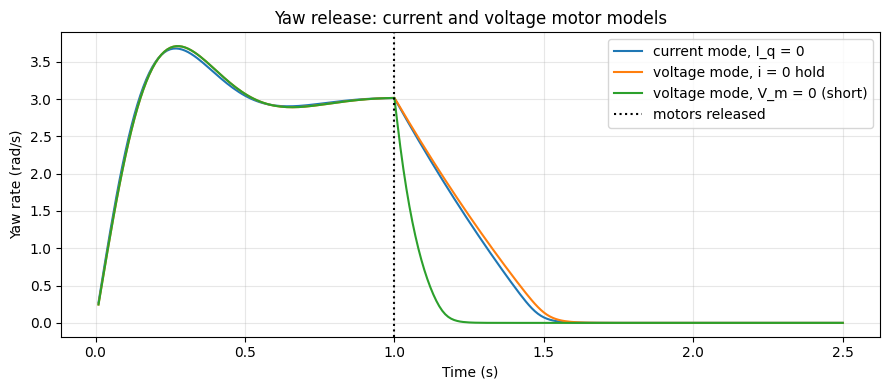

In [17]:
# Yaw diagnosis: which plant terms can create or remove a yaw moment.
drive, axle = wheel_directions_body()
radius = rc.WHEEL_ROBOT_DIST * axle
axial_moment_arm = radius[0] * axle[1] - radius[1] * axle[0]
drive_moment_arm = radius[0] * drive[1] - radius[1] * drive[0]
print("Moment arm of a-axis (roller) force, r_i x a_i [m]:", axial_moment_arm)
print("Moment arm of d-axis (drive) force,  r_i x d_i [m]:", drive_moment_arm)
pure_yaw_rate = 3.0
_, pure_yaw_slip_a = wheel_slip_velocities(
    np.zeros(2), pure_yaw_rate, inverse_kinematics(body_command(yaw_rate=pure_yaw_rate)))
print(f"a-axis slip for pure yaw at {pure_yaw_rate} rad/s [m/s]:", pure_yaw_slip_a)

probe = WheelSlipRobotSimulator(dt=DT, initial_state=np.zeros(14))
effective_mass = probe.body_mass + (rc.WHEEL_INERTIA / rc.WHEEL_RADIUS**2) * (probe.H @ probe.H.T)
print("sum of drive directions sum_i d_i:", drive.sum(axis=1))
print(f"wheel-inertia coupling M_eff[u, omega] = {effective_mass[0, 2]:.3e} kg m "
      f"(M_eff[omega, omega] = {effective_mass[2, 2]:.3e} kg m^2)")
print(f"motor-only drive force K_t*I_max/R_w = {rc.MOTOR_KT * rc.IQ_LIMIT / rc.WHEEL_RADIUS:.2f} N "
      f"< static cap MU_D_STAT*N = {rc.MU_D_STAT * rc.F_N:.2f} N, so no wheel slides in d")


# Independent check of the current-mode equations: dE_kin/dt must equal motor power + wheel-loss
# power + a-axis friction power + d-axis sliding power (F_d * v_d, zero while gripping) at every instant.
def kinetic_energy(state):
    return (0.5 * rc.ROBOT_MASS * float(state[3:5] @ state[3:5]) + 0.5 * rc.ROBOT_INERTIA * state[5] ** 2
            + 0.5 * rc.WHEEL_INERTIA * float(state[6:10] @ state[6:10]))

energy_sim = OpenLoopPlant(motor_mode="current")
lateral_targets = inverse_kinematics(body_command(left=0.25))
worst_energy_error = 0.0
for k in range(int(round(1.0 / SIM_DT_S))):
    state0 = energy_sim.state.copy()
    current = energy_sim._servo_command(lateral_targets)
    _, _, force_d, force_a, slip_d, slip_a, *_ = energy_sim.plant._contact_wrenches(state0, current, np.zeros(3))
    if k == 0:
        print(f"Lateral servo, first step: currents {current} A -> F_d {force_d} N; "
              f"sum F_d = {force_d.sum():+.3f} N, yaw moment L*sum F_d = {rc.WHEEL_ROBOT_DIST * force_d.sum():+.4f} N m")
    loss_power = wheel_loss_torque(state0[6:10]) @ state0[6:10]
    power = rc.MOTOR_KT * current @ state0[6:10] + loss_power + force_a @ slip_a + force_d @ slip_d
    derivative = energy_sim.plant.physical_dynamics(state0, current, np.zeros(3))[0]
    eps = 1e-7
    energy_rate = (kinetic_energy(state0 + eps * derivative) - kinetic_energy(state0 - eps * derivative)) / (2 * eps)
    worst_energy_error = max(worst_energy_error, abs(energy_rate - power) / max(abs(power), 1e-9))
    energy_sim.state = energy_sim.plant.discrete_map(state0, current, np.zeros(3))
assert worst_energy_error < 1e-6, f"Energy balance violated: relative error {worst_energy_error:.2e}"
print(f"PASS energy balance over 1 s of the lateral servo test: worst relative error {worst_energy_error:.1e}")
moment_free = np.linalg.pinv(probe.H) @ np.array([-1.0, 0.0, 0.0])
print(f"Moment-free allocation for a 1 N left push, pinv(H): {moment_free} N (sum {moment_free.sum():+.1e})")

# Yaw release in both motor models: spin up to 3 rad/s through the servo, then release the motors.
#   current mode, I_q = 0         : no motor torque; only the wheel losses act.
#   voltage mode, i = 0 hold      : V_m = K_e*theta_dot cancels the back-EMF; same as I_q = 0.
#   voltage mode, V_m = 0 (short) : back-EMF drives a braking current, on top of the losses.
RELEASES = [("current", "zero_current", "current mode, I_q = 0"),
            ("voltage", "zero_current", "voltage mode, i = 0 hold"),
            ("voltage", "short", "voltage mode, V_m = 0 (short)")]

def run_release(motor_mode, release, spin_rate=3.0, spin_s=1.0, coast_s=1.5):
    sim = OpenLoopPlant(motor_mode=motor_mode)
    target = inverse_kinematics(body_command(yaw_rate=spin_rate))
    times, omega = [], []
    for k in range(int(round((spin_s + coast_s) / SIM_DT_S))):
        if k * SIM_DT_S < spin_s:
            sim.step(target)
        else:
            if motor_mode == "current":
                command = np.zeros(N_WHEELS)
            elif release == "short":
                command = np.zeros(N_WHEELS)
            else:
                command = rc.MOTOR_KT * sim.state[6:10]
            sim.state = sim.plant.discrete_map(sim.state, command, np.zeros(3))
        times.append((k + 1) * SIM_DT_S); omega.append(sim.state[5])
    return np.array(times), np.array(omega), spin_s

# Prediction for a free coast with the wheel losses alone (rolling constraint, pure yaw):
#   I_eff domega/dt = -4 L C_rr N - 4 b_w (L/R_w)^2 omega
loss_coulomb_decel = 4 * rc.WHEEL_ROBOT_DIST * rc.WHEEL_ROLLING_RESISTANCE_COEFF * rc.F_N / effective_mass[2, 2]
loss_viscous_rate = 4 * rc.WHEEL_BEARING_VISCOUS_DRAG * (rc.WHEEL_ROBOT_DIST / rc.WHEEL_RADIUS) ** 2 / effective_mass[2, 2]
print(f"Wheel losses: C_rr = {rc.WHEEL_ROLLING_RESISTANCE_COEFF}, b_w = {rc.WHEEL_BEARING_VISCOUS_DRAG} N m s/rad "
      f"-> yaw deceleration {loss_coulomb_decel:.2f} rad/s^2 + {loss_viscous_rate:.2f}/s * omega "
      "(with both at 0 a free coast conserves kinetic energy exactly)")
tau_emf = effective_mass[2, 2] / (4 * rc.MOTOR_KT ** 2 / rc.MOTOR_RESISTANCE * (rc.WHEEL_ROBOT_DIST / rc.WHEEL_RADIUS) ** 2)
print(f"Back-EMF yaw time constant with V_m = 0: I_eff / (4 K_t K_e/R (L/R_w)^2) = {tau_emf * 1e3:.0f} ms")

release_runs = {}
for motor_mode, release, label in RELEASES:
    tt, omega, spin_s = run_release(motor_mode, release)
    release_runs[label] = (tt, omega)
    k_rel = int(round(spin_s / SIM_DT_S)) - 1
    stopped = np.flatnonzero(np.abs(omega[k_rel:]) < 0.01)
    stop_text = f"{(tt[k_rel + stopped[0]] - spin_s) * 1e3:.0f} ms" if stopped.size else "not within 1.5 s"
    print(f"  {label:30s}: omega {omega[k_rel]:.3f} rad/s at release, below 0.01 rad/s after {stop_text}")
if loss_coulomb_decel > 0 or loss_viscous_rate > 0:
    omega0 = release_runs[RELEASES[0][2]][1][int(round(1.0 / SIM_DT_S)) - 1]
    if loss_viscous_rate > 0:
        predicted_stop = np.log(1 + loss_viscous_rate * omega0 / loss_coulomb_decel) / loss_viscous_rate if loss_coulomb_decel > 0 else np.inf
    else:
        predicted_stop = omega0 / loss_coulomb_decel
    print(f"  predicted free-coast stop time from the loss terms alone: {predicted_stop * 1e3:.0f} ms "
          "(the tanh smoothing of C_rr lengthens the last few rad/s)")

fig, ax = plt.subplots(figsize=(9, 4))
for label, (tt, omega) in release_runs.items():
    ax.plot(tt, omega, label=label)
ax.axvline(1.0, linestyle=":", color="k", label="motors released")
ax.set_xlabel("Time (s)"); ax.set_ylabel("Yaw rate (rad/s)"); ax.set_title("Yaw release: current and voltage motor models")
ax.grid(True, alpha=0.3); ax.legend(); plt.tight_layout(); plt.show()

## 5. PID controller and inverse dynamics

The translational PID produces a desired world-frame acceleration using position error, velocity error, integral error, and trajectory feed-forward. The acceleration is rotated into body coordinates and corrected for the rotating frame to form a desired body-twist derivative. A wheel-force pseudoinverse allocates the corresponding drive wrench; motor currents then account for wheel inertia and contact torque. This is a feed-forward allocation around the current state, followed by nonlinear plant-feasibility scaling, not an exact inverse of the nonlinear slip law.

Heading control is cascaded: heading error produces a yaw-rate target, and yaw-rate error produces the requested yaw acceleration. The resulting translation/yaw request is combined before current and plant-limit checks.

On the voltage-driven plant (`PLANT_MOTOR_MODE = "voltage"`) the PID is unchanged up to the scaled current request. It then commands the motor voltage that gives that current, $V_m = R\,i + K_e\dot\theta$, and the plant integrates the winding current. The feasibility scaling also checks that voltage against `MAX_MOTOR_VOLTAGE`. The integrators freeze when the request is scaled down, and also when the driver cannot apply the commanded voltage, so a limit inside the plant cannot wind them up.

In [18]:
class PositionPIDController:
    """Position PID plus a cascaded heading-to-omega PID baseline.

    The outer heading loop turns heading error into a desired yaw rate. The
    inner omega PID uses omega_ref - omega as its error, and its output is the
    yaw acceleration request that the motor/current model must realize.
    Translation and yaw requests are converted to wheel currents, then scaled
    if current or static-traction limits would be exceeded. On the voltage-driven
    plant the scaled currents are sent as the motor voltages that produce them.
    """

    # Trial tuning for the current figure-eight: stronger position correction with damping.
    def __init__(self, kp=(12.0, 12.0), ki=(0.5, 0.5), kd=(6.0, 6.0),
                 kp_heading=5.0, ki_heading=0.2,
                 kp_omega=4.0, ki_omega=0.2, kd_omega=0.05):
        self.kp = np.asarray(kp, dtype=float)
        self.ki = np.asarray(ki, dtype=float)
        self.kd = np.asarray(kd, dtype=float)
        # Outer loop: heading error -> correction to the reference yaw rate.
        self.kp_heading = float(kp_heading)
        self.ki_heading = float(ki_heading)
        # Inner loop: explicit PID gains on yaw-rate error, omega_ref - omega.
        # These are starting values and still need tuning against robot data.
        self.kp_omega = float(kp_omega)
        self.ki_omega = float(ki_omega)
        self.kd_omega = float(kd_omega)
        self.integral = np.zeros(4)  # x, y, heading, and omega error integrals
        self.previous_omega_error = None
        # Progress is projected from the actual robot position each step. The
        # target therefore follows the plant instead of advancing on a clock.
        self.path_arc_progress = 0.0  # measured robot progress along the route
        self.reference_arc_progress = 0.0  # moving target progress, kept near the robot
        self.target_lead_time = 0.25  # seconds of dynamically reachable lookahead

    def _local_path_reference(self, plant):
        """Build a route target from measured position and dynamically limited speed."""
        state = plant.state
        position = state[:2]
        velocity_world = state[3:5]
        progress_tangent = np.array([
            np.interp(self.path_arc_progress, PATH_ARC, PATH_TANGENT[:, 0]),
            np.interp(self.path_arc_progress, PATH_ARC, PATH_TANGENT[:, 1]),
        ])
        speed_along_path = float(np.dot(velocity_world, progress_tangent))

        # Search a small arc-length window around the last projection. Keeping
        # this window local prevents the figure-eight crossing from jumping to
        # its other branch, and prevents a distant future point becoming target.
        back_window = 0.08
        forward_window = max(0.25, 0.15 + 0.15 * abs(speed_along_path))
        lower_arc = max(0.0, self.path_arc_progress - back_window)
        upper_arc = min(PATH_ARC[-1], self.path_arc_progress + forward_window)
        first = max(0, int(np.searchsorted(PATH_ARC, lower_arc, side="left")))
        last = min(len(PATH_ARC), int(np.searchsorted(PATH_ARC, upper_arc, side="right")))
        candidate_points = _route_points[first:last]
        if len(candidate_points) == 0:
            candidate_points = _route_points[-1:]
            first = len(PATH_ARC) - 1
        nearest = int(np.argmin(np.sum((candidate_points - position) ** 2, axis=1)))
        projected_index = first + nearest
        # Progress is monotone so noise near the crossing cannot send the robot
        # backward or switch it onto the other half of the figure-eight.
        self.path_arc_progress = max(self.path_arc_progress, float(PATH_ARC[projected_index]))
        actual_arc = self.path_arc_progress

        # The speed envelope respects route curvature and stopping distance. Its
        # command is rate-limited from measured speed, so it cannot jump ahead in
        # velocity. Look ahead one control step to avoid a zero-speed deadlock at
        # the start of the route.
        forward_speed = max(speed_along_path, 0.0)
        profile_step = max(
            0.01,
            forward_speed * plant.dt + 0.5 * TANGENTIAL_ACCEL_LIMIT * plant.dt**2,
        )
        speed_cap = float(np.interp(
            min(PATH_ARC[-1], actual_arc + profile_step), PATH_ARC, PATH_SPEED
        ))
        speed_step = TANGENTIAL_ACCEL_LIMIT * plant.dt
        if forward_speed <= speed_cap:
            speed_ref_scalar = min(speed_cap, forward_speed + speed_step)
        else:
            speed_ref_scalar = max(speed_cap, forward_speed - speed_step)
        tangential_acceleration = float(np.clip(
            (speed_ref_scalar - speed_along_path) / plant.dt,
            -TANGENTIAL_ACCEL_LIMIT, TANGENTIAL_ACCEL_LIMIT,
        ))

        # Advance a separate moving target with the speed command, but bound its
        # lead by distance the robot could cover in target_lead_time. If plant
        # dynamics slow the robot, this clamp pulls the target back toward it.
        reachable_lead = (
            forward_speed * self.target_lead_time
            + 0.5 * TANGENTIAL_ACCEL_LIMIT * self.target_lead_time**2
        )
        max_reference_arc = min(PATH_ARC[-1], actual_arc + reachable_lead)
        next_reference_arc = self.reference_arc_progress + speed_ref_scalar * plant.dt
        self.reference_arc_progress = float(np.clip(
            next_reference_arc, actual_arc, max_reference_arc
        ))
        arc = self.reference_arc_progress

        position_ref = np.array([
            np.interp(arc, PATH_ARC, _route_points[:, 0]),
            np.interp(arc, PATH_ARC, _route_points[:, 1]),
        ])
        tangent = np.array([
            np.interp(arc, PATH_ARC, PATH_TANGENT[:, 0]),
            np.interp(arc, PATH_ARC, PATH_TANGENT[:, 1]),
        ])
        tangent /= max(np.linalg.norm(tangent), 1e-9)
        normal = np.array([-tangent[1], tangent[0]])
        curvature = float(np.interp(arc, PATH_ARC, PATH_CURVATURE))
        velocity_ref = speed_ref_scalar * tangent
        acceleration_ref = (
            tangential_acceleration * tangent
            + speed_ref_scalar**2 * curvature * normal
        )
        heading_ref = plant.heading_ref(plant.index * plant.dt)
        yaw_rate_ref = (
            curvature * speed_ref_scalar
            if HEADING_MODE in ("front_body", "sideways_body")
            else 0.0
        )
        return position_ref, velocity_ref, acceleration_ref, heading_ref, yaw_rate_ref

    def compute(self, plant, wrench_body, model):
        time_s = plant.index * plant.dt
        (position_ref, velocity_ref, acceleration_ref,
         heading_ref, yaw_rate_ref) = self._local_path_reference(plant)
        state = plant.state
        position_error = position_ref - state[:2]
        velocity_error = velocity_ref - state[3:5]
        # P position + D velocity + I accumulated position error, plus route
        # acceleration feed-forward. Repulsion is a PID heuristic, not a guarantee.
        acceleration_world = (
            acceleration_ref + self.kp * position_error
            + self.ki * self.integral[:2] + self.kd * velocity_error
            + pid_obstacle_repulsion(state[:2], time_s)
        )
        heading_error = wrap_angle(heading_ref - state[2])
        # Outer loop: convert local path-heading error into a desired yaw rate.
        omega_ref = yaw_rate_ref + self.kp_heading * heading_error
        omega_ref += self.ki_heading * self.integral[2]
        omega_ref = float(np.clip(omega_ref, -MAX_YAW_RATE, MAX_YAW_RATE))
        omega_error = omega_ref - state[5]

        # Inner loop: PID error is omega_ref - omega. Its output is a yaw
        # acceleration request because wheel torque changes the body's omega
        # through the rotational dynamics. The derivative is taken on the omega
        # error itself; no wheel-angle signal is used to form this command.
        omega_error_rate = 0.0
        if self.previous_omega_error is not None:
            omega_error_rate = (omega_error - self.previous_omega_error) / plant.dt
        yaw_acceleration = (
            self.kp_omega * omega_error
            + self.ki_omega * self.integral[3]
            + self.kd_omega * omega_error_rate
        )
        velocity_body = world_to_body(state[3:5], state[2])
        acceleration_body = world_to_body(acceleration_world, state[2])
        omega = state[5]
        generalized_acceleration = np.array([
            acceleration_body[0] + omega * velocity_body[1],
            acceleration_body[1] - omega * velocity_body[0],
            yaw_acceleration,
        ])
        coriolis = plant.coriolis(np.r_[velocity_body, omega], rc.ROBOT_MASS)
        # Allocate desired chassis wrench across the actual wheel/contact model.
        # The feed-forward wheel acceleration is kinematic, but actual wheel
        # speeds remain independent states and can depart from rolling under slip.
        requested_current = plant.inverse_dynamics_current(
            generalized_acceleration, state, wrench_body
        )
        scale, feasible = plant.largest_feasible_current_scale(
            requested_current, state, wrench_body, model
        )
        current = scale * requested_current
        # Voltage-driven plant: command the voltage for this current. If the driver
        # cannot apply it (bus or current limit), freeze the integrators as well.
        voltage = None
        driver_limited = False
        if hasattr(plant, "current_to_voltage"):
            voltage = plant.current_to_voltage(state, current)
            driver_limited = bool(np.any(np.abs(plant.applied_voltage(state, voltage) - voltage) > 1e-9))
        decision = {
            "current": current,
            "requested_current": requested_current,
            "tracking_error": np.r_[position_error, heading_error, omega_error],
            "omega_ref": omega_ref,
            "omega_error": omega_error,
            # Save the actual online targets so the plots show what PID followed.
            "position_ref": position_ref.copy(),
            "velocity_ref": velocity_ref.copy(),
            "acceleration_ref": acceleration_ref.copy(),
            "heading_ref": heading_ref,
            "yaw_rate_ref": yaw_rate_ref,
            "path_arc_progress": self.path_arc_progress,
            "reference_arc_progress": self.reference_arc_progress,
            "saturation_scale": scale,
            "feasible_ray": feasible,
            "freeze_integrator": scale < 1.0 - 1e-9 or driver_limited,
            "driver_limited": driver_limited,
        }
        if voltage is not None:
            decision["voltage"] = voltage
        return decision

    def observe(self, snapshot):
        if not snapshot["decision"]["freeze_integrator"]:
            self.integral += snapshot["dt"] * snapshot["decision"]["tracking_error"]
        self.integral = np.clip(self.integral, -1.5, 1.5)
        # Save the last omega error for the inner PID's derivative term.
        self.previous_omega_error = float(snapshot["decision"]["omega_error"])

## 6. Convex MPC: prediction model, objective, and constraints

The MPC decision variables contain the active plant states at $N+1$ samples (14 for the slip plant, including four wheel angles), controller integral-error variables, and four wheel currents at each of the $N$ control intervals. At each stage, finite differences of the nonlinear RK45-integrated slip-plant map form

$$
\mathbf x_{k+1}=A_k\mathbf x_k+B_k\mathbf I_{q,k}+E_k\mathbf w_k+\mathbf c_k.
$$

The affine offset makes the local model match the nonlinear map at its nominal point. The quadratic objective penalizes tracking error, integral error, acceleration-reference error, current magnitude, current slew, and terminal error. Linear constraints enforce current, computed contact-force capacity, acceleration, speed, yaw-rate, integral, and obstacle limits. The QP is a local approximation; the first action is checked against the nonlinear plant map before application.

Only the first current vector is applied. The optimization is solved again at the next sample, which is the receding-horizon loop.


In [19]:
class ConvexMPCController:
    """Receding-horizon convex QP over wheel currents and predicted robot states.

    Position, velocity, and heading references are fixed data at each stage.
    Integral error is predicted controller memory, not an extra plant state.
    """

    def __init__(self, horizon=20, weights=None):
        self.horizon = int(horizon)
        if self.horizon < 1:
            raise ValueError("horizon must be positive")
        self.integral = np.zeros(3)
        self.planned_integrals = None
        self.weights = weights or {
            "position": 60.0, "velocity": 8.0, "heading": 8.0,
            "integral": 0.05, "integral_slack": 1000.0,
            "acceleration": 2.0, "current": 0.02, "slew": 0.15,
            "terminal_position": 120.0, "terminal_velocity": 16.0,
            "terminal_heading": 20.0,
        }

    def _continuous_heading_reference(self, plant, time_s):
        return plant.state[2] + wrap_angle(plant.heading_ref(time_s) - plant.state[2])

    def compute(self, plant, wrench_body, first_model):
        import cvxpy as cp

        requested_horizon = self.horizon
        horizon = self.horizon
        # One column per prediction sample, using the active plant's full state.
        # The slip plant includes chassis states, wheel speeds, and wheel angles.
        states = cp.Variable((plant.state.size, horizon + 1))
        integrals = cp.Variable((3, horizon + 1))
        integral_slack = cp.Variable((3, horizon), nonneg=True)
        # Obstacle clearance is softened so an already unsafe state or a changed
        # waypoint cannot make the whole QP infeasible for one short time step.
        # A large penalty makes the optimizer satisfy clearance whenever feasible.
        obstacle_slacks = []
        currents = cp.Variable((N_WHEELS, horizon))
        constraints = [states[:, 0] == plant.state, integrals[:, 0] == self.integral]
        objective = 0

        for offset in range(horizon):
            index = plant.index + offset
            next_time = (index + 1) * plant.dt
            model = first_model if offset == 0 else plant.linear_model(index, np.zeros(3))
            # These are desired targets at this future time, not variables. For a
            # receive-pass event the terminal target is the goal with zero velocity.
            position_ref, velocity_ref, acceleration_ref = trajectory_reference(next_time)
            heading_ref = self._continuous_heading_reference(plant, next_time)
            stage_wrench = wrench_body if offset == 0 else np.zeros(3)
            current = currents[:, offset]
            # The local affine maps express acceleration and required wheel
            # traction as functions of predicted state and candidate currents.
            acceleration = (
                model["acceleration_x"] @ states[:, offset]
                + model["acceleration_u"] @ current
                + model["acceleration_w"] @ stage_wrench
                + model["acceleration_c"]
            )
            traction = (
                model["traction_x"] @ states[:, offset]
                + model["traction_u"] @ current
                + model["traction_w"] @ stage_wrench
                + model["traction_c"]
            )
            # Matrix state update: x[k+1] = A*x[k] + B*Iq[k] + E*w + c.
            # The next two equalities accumulate position and heading error.
            constraints += [
                states[:, offset + 1] == model["A"] @ states[:, offset]
                    + model["B"] @ current + model["E"] @ stage_wrench + model["c"],
                integrals[:2, offset + 1] == integrals[:2, offset]
                    + plant.dt * (position_ref - states[:2, offset]),
                integrals[2, offset + 1] == integrals[2, offset]
                    + plant.dt * (heading_ref - states[2, offset]),
                integrals[:, offset + 1] <= 1.5 + integral_slack[:, offset],
                -integrals[:, offset + 1] <= 1.5 + integral_slack[:, offset],
                current <= plant.current_limit,
                -current <= plant.current_limit,
                # The bounded project contact-force law stays within this capacity.
                *([] if ALLOW_DRIVE_TRACTION_OVERLOAD else [
                    traction <= plant.wheel_traction_limits,
                    -traction <= plant.wheel_traction_limits,
                ]),
                # Facets make polygonal (therefore linear) bounds for acceleration
                # and speed instead of nonlinear Euclidean-norm constraints.
                plant.facets @ acceleration <= plant.acceleration_limit_poly,
                plant.facets @ states[3:5, offset + 1] <= plant.velocity_limit_poly,
                cp.abs(states[5, offset + 1]) <= plant.max_yaw_rate,
            ]
            # Every obstacle has one preselected safe side. Its separating line
            # is fixed data for this solve, so the added constraint is affine.
            # The obstacle side and separating hyperplane are constants for this
            # QP stage, selected from the nominal reference and predicted obstacle pose.
            for _, obstacle_vertices, obstacle_clearance in obstacle_polygons_at(next_time):
                normal, bound = obstacle_safe_halfspace(
                    position_ref, obstacle_vertices, clearance=obstacle_clearance
                )
                clearance_slack = cp.Variable(nonneg=True)
                obstacle_slacks.append(clearance_slack)
                constraints.append(
                    normal @ states[:2, offset + 1] + clearance_slack >= bound
                )
                # Squared nonnegative slack keeps this a convex QP. It allows a
                # temporary clearance shortfall only when the hard plant limits
                # prevent clearing the obstacle at this sample.
                objective += 1e4 * cp.square(clearance_slack)
            # Quadratic tracking costs target pose/velocity; current and slew
            # penalties regularize effort without changing convexity.
            objective += self.weights["position"] * cp.sum_squares(states[:2, offset + 1] - position_ref)
            objective += self.weights["velocity"] * cp.sum_squares(states[3:5, offset + 1] - velocity_ref)
            objective += self.weights["heading"] * cp.square(states[2, offset + 1] - heading_ref)
            objective += self.weights["integral"] * cp.sum_squares(integrals[:, offset + 1])
            objective += self.weights["integral_slack"] * cp.sum_squares(integral_slack[:, offset])
            objective += self.weights["acceleration"] * cp.sum_squares(acceleration - acceleration_ref)
            objective += self.weights["current"] * cp.sum_squares(current)
            previous = plant.history[-1]["current"] if offset == 0 and plant.history else np.zeros(N_WHEELS)
            if offset > 0:
                previous = currents[:, offset - 1]
            objective += self.weights["slew"] * cp.sum_squares(current - previous)

        terminal_time = (plant.index + horizon) * plant.dt
        terminal_position, terminal_velocity, _ = trajectory_reference(terminal_time)
        terminal_heading = self._continuous_heading_reference(plant, terminal_time)
        objective += self.weights["terminal_position"] * cp.sum_squares(states[:2, -1] - terminal_position)
        objective += self.weights["terminal_velocity"] * cp.sum_squares(states[3:5, -1] - terminal_velocity)
        objective += self.weights["terminal_heading"] * cp.square(states[2, -1] - terminal_heading)
        # Apply only the first current; measure the new state and solve again
        # on the next step (the receding-horizon control loop).
        # Solve the convex QP, apply only the first current vector, then replan
        # at the next sample using the latest state (receding-horizon control).
        problem = cp.Problem(cp.Minimize(objective), constraints)
        problem.solve(
            solver=cp.OSQP, warm_start=True, verbose=False,
            max_iter=50000, eps_abs=MPC_CONSTRAINT_TOL, eps_rel=MPC_CONSTRAINT_TOL,
        )
        if problem.status not in (cp.OPTIMAL, cp.OPTIMAL_INACCURATE):
            if horizon > 1:
                shorter = ConvexMPCController(horizon=horizon - 1, weights=self.weights)
                shorter.integral = self.integral.copy()
                decision = shorter.compute(plant, wrench_body, first_model)
                self.planned_integrals = shorter.planned_integrals
                decision["requested_horizon"] = requested_horizon
                return decision
            raise RuntimeError(
                f"MPC QP did not solve at t={plant.index * plant.dt:.3f}s "
                f"after reducing to horizon 1 (solver status: {problem.status}). "
                "A status of 'user_limit' means OSQP reached its iteration limit, "
                "not that the constraints were proven infeasible."
            )
        requested_current = currents.value[:, 0].copy()
        # OSQP can return a numerically inaccurate iterate. Check the first
        # action against the plant limits and scale it toward zero if needed.
        if plant.candidate_feasible(
            1.0, requested_current, plant.state, wrench_body, first_model
        ):
            applied_current = requested_current
            safety_scale = 1.0
            safety_projection_status = None
        elif plant.candidate_feasible(
            0.0, requested_current, plant.state, wrench_body, first_model
        ):
            safety_scale, _ = plant.largest_feasible_current_scale(
                requested_current, plant.state, wrench_body, first_model
            )
            applied_current = safety_scale * requested_current
            safety_projection_status = None
        else:
            # Scaling toward zero fails when the robot must apply braking current
            # to recover a saturated speed/yaw state, so solve a small projection QP.
            applied_current, safety_projection_status = plant.project_current_to_feasible(
                requested_current, plant.state, wrench_body, first_model
            )
            safety_scale = None
        # Enforce the hard actuator cap exactly despite OSQP feasibility tolerance.
        hard_current_limit = min(float(plant.current_limit), float(rc.IQ_LIMIT))
        applied_current = np.clip(applied_current, -hard_current_limit, hard_current_limit)
        self.planned_integrals = integrals.value[:, 1].copy()
        return {
            "current": applied_current,
            "requested_current": requested_current,
            "first_step_safety_scale": safety_scale,
            "first_step_safety_projection_status": safety_projection_status,
            "qp_status": problem.status,
            "qp_objective": float(problem.value),
            "planned_currents": currents.value.copy(),
            "planned_states": states.value.copy(),
            "planned_integrals": integrals.value.copy(),
            "planned_obstacle_slacks": np.asarray(
                [slack.value for slack in obstacle_slacks], dtype=float
            ),
            "effective_horizon": horizon,
            "requested_horizon": requested_horizon,
            "integral_slack": integral_slack.value.copy(),
        }

    def observe(self, snapshot):
        if self.planned_integrals is not None:
            self.integral = np.clip(self.planned_integrals, -1.5, 1.5)


In [20]:
# Focused regression checks for the active 14-state slip plant.
_test_plant = WheelSlipRobotSimulator()
assert _test_plant.state.shape == (14,), "Slip-plant state must include four wheel angles"
_test_state = _test_plant.state.copy()
_test_state[6:10] = np.array([1.0, -2.0, 3.0, -4.0])
_test_derivative = _test_plant.physical_dynamics(_test_state, np.zeros(N_WHEELS), np.zeros(3))[0]
assert _test_derivative.shape == (14,), "Plant derivative must match the 14-state vector"
assert np.allclose(_test_derivative[10:14], _test_state[6:10]), "Wheel angles must integrate wheel angular velocities"
_test_plant._contact_wrenches(_test_state, np.zeros(N_WHEELS), np.zeros(3))
_test_diagnostics = _test_plant._force_selection_diagnostics
_test_modes = _test_diagnostics["force_mode"]
assert _test_modes.shape == (N_WHEELS,), "Each wheel must have its own contact mode"
assert set(_test_modes).issubset({"rolling", "sliding"}), f"Unexpected contact modes: {_test_modes}"
assert _test_diagnostics["rolling_mask"].shape == (N_WHEELS,), "Each wheel needs an independent rolling flag"
assert np.allclose(
    _test_diagnostics["force_used"][_test_diagnostics["rolling_mask"]],
    _test_diagnostics["force_required"][_test_diagnostics["rolling_mask"]],
), "Rolling wheels must use the required static traction reaction"
print("Slip-plant state, wheel-angle integration, and per-wheel contact-mode checks passed when this cell is run.")

Slip-plant state, wheel-angle integration, and per-wheel contact-mode checks passed when this cell is run.


## 7. Run the simulation and inspect diagnostics

The next cell runs a short controller preview, executes the selected simulation, checks model/constraint outputs, and builds the animation and diagnostic plots. The animation shows the physical pose; its drawn outline is for visualization, while collision checking uses the simulator's separate clearance geometry.


PID k=0 t=0.00s p=[-0. -0.] i=[0. 0. 0. 0.] min_margin=2.9997
PID k=1 t=0.01s p=[-0.0002 -0.    ] i=[ 1.3401 -1.3406 -1.0947  1.0941] min_margin=2.9996
PID k=2 t=0.02s p=[-0.0004 -0.    ] i=[ 2.0275 -2.0279 -1.6571  1.6566] min_margin=2.9721
PID uses direct nonlinear plant dynamics; skipped MPC linearization.
Plant: VoltageDrivenSlipSimulator
PID simulation progress: 367/3674 steps (10%)
PID simulation progress: 734/3674 steps (20%)
PID simulation progress: 1101/3674 steps (30%)

PID route progress: 17.31/17.31 m; settled at endpoint: True; run time: 12.83 s
PID run: 1283 explicit plant steps
Position RMS error: 0.02413 m per axis
Maximum position error: 0.10353 m
Peak wheel current: 5.000 A / 5.000 A
Peak motor voltage: 2.730 V / 16.800 V; driver-limited samples: 0
Peak required drive traction: 4.045 N; nominal equal-load limit: 5.955 N/wheel
Wheel-load range: 6.617 to 6.617 N
Peak traction utilization: 67.9%
Peak drive-direction slip: 0.0000 m/s
Per-wheel contact-mode sample counts: 

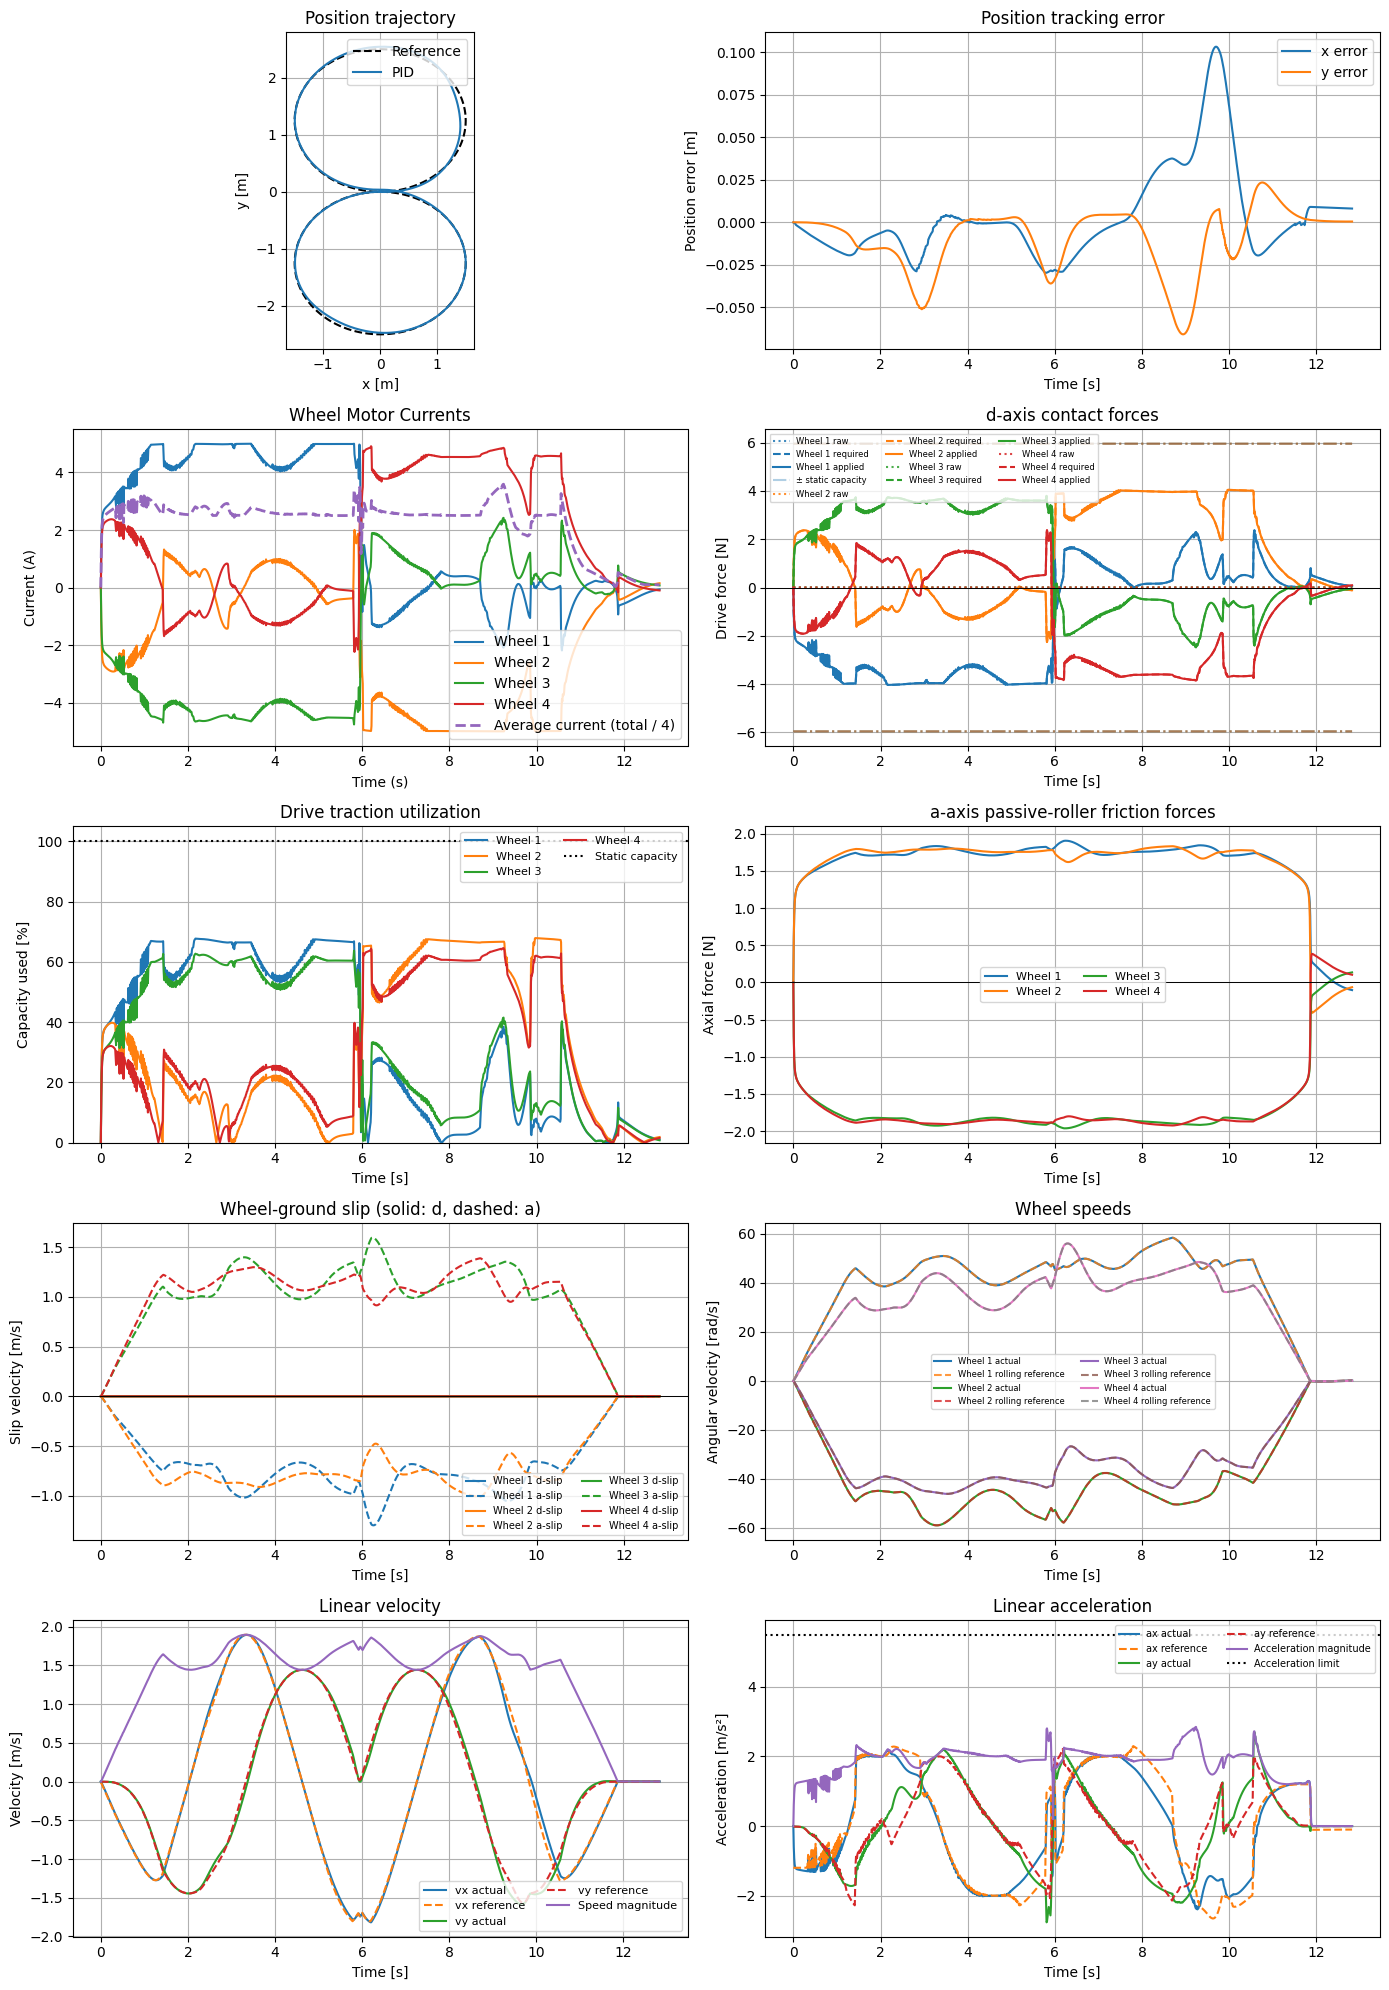

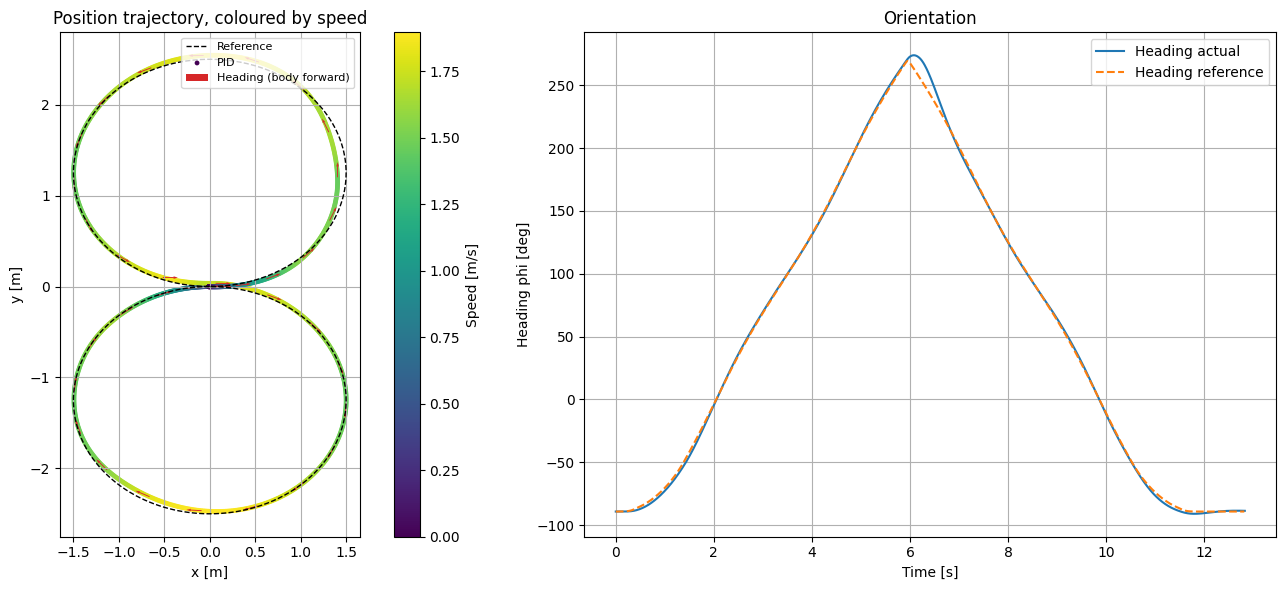

In [21]:
def make_selected_controller():
    if CONTROLLER_MODE.upper() == "PID":
        return PositionPIDController()
    if CONTROLLER_MODE.upper() == "MPC":
        return ConvexMPCController(horizon=MPC_HORIZON)
    raise ValueError("CONTROLLER_MODE must be 'PID' or 'MPC'")


preview_plant = make_plant()
preview_controller = make_selected_controller()
for _ in range(3):
    snapshot = preview_plant.step(preview_controller)
    print(
        f"{CONTROLLER_MODE.upper()} k={snapshot['step']} t={snapshot['time']:.2f}s "
        f"p={np.round(snapshot['state_after'][:2], 4)} "
        f"i={np.round(snapshot['current'], 4)} "
        f"min_margin={snapshot['minimum_constraint_margin']:.4f}"
    )
if snapshot["linear_model"] is not None:
    print("Model shapes A/B/E:", snapshot["linear_model"]["A"].shape,
          snapshot["linear_model"]["B"].shape, snapshot["linear_model"]["E"].shape)
else:
    print("PID uses direct nonlinear plant dynamics; skipped MPC linearization.")

GOAL_HOLD_TIME = 1.0  # Require a full second at rest before declaring arrival.
plant = make_plant()
print(f"Plant: {type(plant).__name__}")
run_controller = make_selected_controller()
if CONTROLLER_MODE.upper() == "PID":
    # PID follows actual route progress, so end the run when the plant reaches
    # the endpoint and settles. A generous cap protects against endless runs;
    # it does not move the target or prescribe a transit schedule.
    MAX_SIMULATION_TIME = 3.0 * PATH_END_TIME + GOAL_HOLD_TIME
    MAX_STEPS = int(np.ceil(MAX_SIMULATION_TIME / DT))
    settled_steps = 0
    required_settled_steps = int(np.ceil(GOAL_HOLD_TIME / DT))
    trace = []
    progress_interval = max(1, MAX_STEPS // 10)
    for simulation_step in range(MAX_STEPS):
        sample = plant.step(run_controller)
        trace.append(sample)
        # Stop on the first violated constraint; later steps cannot repair this trial
        # and only delay the existing diagnostic raised below.
        if not sample["feasible"]:
            break
        if (simulation_step + 1) % progress_interval == 0:
            print(f"PID simulation progress: {simulation_step + 1}/{MAX_STEPS} steps "
                  f"({100.0 * (simulation_step + 1) / MAX_STEPS:.0f}%)")
        at_route_end = run_controller.path_arc_progress >= PATH_ARC[-1] - 0.02
        at_rest = np.linalg.norm(plant.state[3:5]) < 0.05
        settled_steps = settled_steps + 1 if at_route_end and at_rest else 0
        if settled_steps >= required_settled_steps:
            break
    route_complete = settled_steps >= required_settled_steps
else:
    # MPC retains the original fixed-time demonstration while it is paused.
    SIMULATION_TIME = PATH_END_TIME + GOAL_HOLD_TIME
    trace = plant.run(run_controller, int(np.ceil(SIMULATION_TIME / DT)))
    route_complete = None
N_STEPS = len(trace)
SIMULATION_TIME = N_STEPS * DT
TIME = DT * np.arange(N_STEPS + 1)
state_history = np.vstack((plant.initial_state,
                           np.array([sample["state_after"] for sample in trace])))
if CONTROLLER_MODE.upper() == "PID":
    # Plot the online path-following targets recorded by PID at each state.
    pid_position_targets = np.array([sample["decision"]["position_ref"] for sample in trace])
    pid_velocity_targets = np.array([sample["decision"]["velocity_ref"] for sample in trace])
    pid_acceleration_targets = np.array([sample["decision"]["acceleration_ref"] for sample in trace])
    position_reference_history = np.vstack((pid_position_targets, pid_position_targets[-1]))
    velocity_reference_history = np.vstack((pid_velocity_targets, pid_velocity_targets[-1]))
    acceleration_reference_history = pid_acceleration_targets
else:
    # MPC retains its fixed, time-indexed trajectory reference.
    position_reference_history = np.array([trajectory_reference(t)[0] for t in TIME])
    velocity_reference_history = np.array([trajectory_reference(t)[1] for t in TIME])
    acceleration_reference_history = np.array([trajectory_reference(t)[2] for t in TIME[:-1]])
position_error_history = position_reference_history - state_history[:, :2]
velocity_history = state_history[:, 3:5]
speed_history = np.linalg.norm(velocity_history, axis=1)

acceleration_history = np.array([
    sample["state_derivative"][3:5] for sample in trace
])
# PID uses the locally projected, rate-limited acceleration targets above.
acceleration_magnitude_history = np.linalg.norm(acceleration_history, axis=1)
current_history = np.array([sample["current"] for sample in trace])
traction_history = np.array([sample["required_traction"] for sample in trace])
normal_load_history = np.array([sample["normal_loads_N"] for sample in trace])
traction_limit_history = np.array([sample["wheel_traction_limits_N"] for sample in trace])
#slip_onset_history = np.array([sample["slip_onset"] for sample in trace])
torque_residual_history = np.array([sample["wheel_torque_balance_residual"] for sample in trace])
traction_utilization_history = 100.0 * np.abs(traction_history) / np.maximum(traction_limit_history, 1e-12)
drive_slip_history = np.array([sample["drive_slip"] for sample in trace])
drive_force_history = np.array([sample["force_d"] for sample in trace])
axial_slip_history = np.array([sample["slip_a"] for sample in trace])
axial_force_history = np.array([sample["force_a"] for sample in trace])
wheel_speed_history = state_history[:, 6:10]
wheel_speed_rolling_history = np.array([
    -(plant.H.T @ np.r_[world_to_body(state[3:5], state[2]), state[5]]) / rc.WHEEL_RADIUS
    for state in state_history
])
wheel_speed_mismatch_history = wheel_speed_history - wheel_speed_rolling_history
wheel_angle_history = state_history[:, 10:14]
force_mode_history = np.array([sample["force_mode"] for sample in trace])
rolling_mask_history = np.array([sample["rolling_mask"] for sample in trace])
force_required_history = np.array([sample["force_required"] for sample in trace])
raw_drive_force_history = np.array([sample["force_d"] for sample in trace])
force_used_history = np.array([sample["force_used"] for sample in trace])

# Recorded issue to revisit: the earlier MPC run hit the obstacle check at k=176 (1.760 s).
# This PID run can also fail the plant safety assertion on collision; PID has no QP status.
infeasible_samples = [sample for sample in trace if not sample["feasible"]]
if infeasible_samples:
    first_bad = infeasible_samples[0]
    violated_constraints = {
        name: float(np.min(margin))
        for name, margin in first_bad["constraint_margins"].items()
        if np.min(margin) < -MPC_CONSTRAINT_TOL
    }
    print(
        f"WARNING: {len(infeasible_samples)} infeasible plant samples; first at "
        f"k={first_bad['step']} t={first_bad['time']:.3f}s, "
        f"current={np.max(np.abs(first_bad['current'])):.4f}/{rc.IQ_LIMIT:.4f} A, "
        f"margin={first_bad['minimum_constraint_margin']:.3e}, "
        f"yaw_rate={abs(first_bad['state_after'][5]):.4f}/{MAX_YAW_RATE:.4f} rad/s, "
        f"violated_constraints={violated_constraints}, "
        f"obstacle_collision={first_bad['collision']}, "
        f"obstacle_clearance_margin={first_bad['minimum_obstacle_clearance_margin']:.4f} m"
    )
    print("Displaying the recorded run up to the first infeasible sample.")
force_balance_error = max(np.max(np.abs(sample["force_balance_residual"])) for sample in trace)
wheel_torque_balance_error = max(np.max(np.abs(sample["wheel_torque_balance_residual"])) for sample in trace)
if force_balance_error >= 1e-8:
    print(f"WARNING: force-balance residual exceeds tolerance: {force_balance_error:.2e}")
if wheel_torque_balance_error >= 1e-10:
    print(f"WARNING: wheel torque-balance residual exceeds tolerance: {wheel_torque_balance_error:.2e}")
if np.max(np.abs(current_history)) > rc.IQ_LIMIT + MPC_CONSTRAINT_TOL:
    print(f"WARNING: current limit exceeded: {np.max(np.abs(current_history)):.4f}/{rc.IQ_LIMIT:.4f} A")
if not ALLOW_DRIVE_TRACTION_OVERLOAD and np.any(
    np.abs(traction_history) > traction_limit_history + MPC_CONSTRAINT_TOL
):
    print("WARNING: drive traction limit exceeded in the recorded run.")
if CONTROLLER_MODE.upper() == "PID":
    achieved_progress = run_controller.path_arc_progress
    print(f"\nPID route progress: {achieved_progress:.2f}/{PATH_ARC[-1]:.2f} m; "
          f"settled at endpoint: {route_complete}; run time: {SIMULATION_TIME:.2f} s")
else:
    print(f"\nMPC reference transit time: {PATH_END_TIME:.2f} s; "
          f"simulation including goal hold: {SIMULATION_TIME:.2f} s")
print(f"{CONTROLLER_MODE.upper()} run: {N_STEPS} explicit plant steps")
print(f"Position RMS error: {np.sqrt(np.mean(position_error_history**2)):.5f} m per axis")
print(f"Maximum position error: {np.max(np.linalg.norm(position_error_history, axis=1)):.5f} m")
print(f"Peak wheel current: {np.max(np.abs(current_history)):.3f} A / {rc.IQ_LIMIT:.3f} A")
if "motor_voltage_applied" in trace[0]:
    voltage_history = np.array([sample["motor_voltage_applied"] for sample in trace])
    print(f"Peak motor voltage: {np.max(np.abs(voltage_history)):.3f} V / {rc.MAX_MOTOR_VOLTAGE:.3f} V; "
          f"driver-limited samples: {sum(sample['decision'].get('driver_limited', False) for sample in trace)}")
print(f"Peak required drive traction: {np.max(np.abs(traction_history)):.3f} N; "
      f"nominal equal-load limit: {rc.F_ROLL_LIMIT:.3f} N/wheel")
print(f"Wheel-load range: {np.min(normal_load_history):.3f} to "
      f"{np.max(normal_load_history):.3f} N")
print(f"Peak traction utilization: {np.max(traction_utilization_history):.1f}%")
#print(f"Drive-slip onset samples (threshold { _williams_model.slip_threshold:.4f} m/s): "
#      f"{int(np.sum(np.any(slip_onset_history, axis=1)))}")
print(f"Peak drive-direction slip: {np.max(np.abs(drive_slip_history)):.4f} m/s")
print("Per-wheel contact-mode sample counts:",
      {mode: int(np.sum(force_mode_history == mode)) for mode in ("rolling", "sliding")})
print(f"Peak passive-roller axial slip: {np.max(np.abs(axial_slip_history)):.4f} m/s")
print(f"Peak passive-roller axial friction: {np.max(np.abs(axial_force_history)):.3f} N/wheel")
print(f"Peak speed: {np.max(speed_history):.3f} m/s")
print(f"Peak linear acceleration: {np.max(acceleration_magnitude_history):.3f} m/s^2")
print(f"Peak wheel torque-balance residual: {np.max(np.abs(torque_residual_history)):.2e} N m")

# Explicit IPython display keeps all plots inline in the notebook output.
from IPython.display import HTML, display

# The animated field view is the primary simulation visualization.
# Animated top-down XY view. This silhouette is for display; collision checks
# still use the separate ROBOT_CLEARANCE value in the simulator/MPC.
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Polygon as PolygonPatch
from matplotlib.transforms import Affine2D
from IPython.display import HTML, display

# Follow the COCO_T1 solution's interactive XY animation: fixed field axes,
# an animated robot trace, a visible reference path, and play/scrub controls.
# Keep this plot inline in the notebook, as in the COCO example.
import plotly.graph_objects as go

# The robot uses the project wheel/contact radius and the SSL-style clipped front.
ROBOT_BODY_RADIUS = rc.WHEEL_ROBOT_DIST
SSL_FRONT_CUT_FRACTION = 0.055 / 0.085
ROBOT_FRONT_CUT_X = SSL_FRONT_CUT_FRACTION * ROBOT_BODY_RADIUS
cut_angle = np.arccos(ROBOT_FRONT_CUT_X / ROBOT_BODY_RADIUS)
arc_angles = np.linspace(cut_angle, 2.0 * np.pi - cut_angle, 100)
robot_outline_local = np.vstack((
    np.column_stack((ROBOT_BODY_RADIUS * np.cos(arc_angles),
                     ROBOT_BODY_RADIUS * np.sin(arc_angles))),
    [ROBOT_FRONT_CUT_X, ROBOT_BODY_RADIUS * np.sin(cut_angle)],
))
front_edge_local = np.array([
    [ROBOT_FRONT_CUT_X, -ROBOT_BODY_RADIUS * np.sin(cut_angle)],
    [ROBOT_FRONT_CUT_X,  ROBOT_BODY_RADIUS * np.sin(cut_angle)],
])

# Downsample long runs for a responsive animation while retaining both endpoints.
frame_indices = np.unique(np.linspace(
    0, len(TIME) - 1, min(240, len(TIME)), dtype=int
))

def robot_world_geometry(sample_index):
    """Rotate and translate the robot outline using the simulated pose."""
    x, y, phi = state_history[sample_index, :3]
    rotation = np.array([[np.cos(phi), -np.sin(phi)],
                         [np.sin(phi),  np.cos(phi)]])
    outline = robot_outline_local @ rotation.T + np.array([x, y])
    front = front_edge_local @ rotation.T + np.array([x, y])
    nose = np.array([x, y]) + ROBOT_BODY_RADIUS * np.array([np.cos(phi), np.sin(phi)])
    return x, y, phi, outline, front, nose

first_index = int(frame_indices[0])
x0, y0, phi0, outline0, front0, nose0 = robot_world_geometry(first_index)
static_traces = []
for obstacle_index, obstacle_vertices in enumerate(STATIC_OBSTACLES):
    vertices = np.asarray(obstacle_vertices, dtype=float)
    closed = np.vstack((vertices, vertices[0]))
    static_traces.append(go.Scatter(
        x=closed[:, 0], y=closed[:, 1], mode="lines", fill="toself",
        fillcolor="rgba(120,120,120,0.48)",
        line=dict(color="#444444", width=1.5),
        name="static obstacle" if obstacle_index == 0 else None,
        showlegend=(obstacle_index == 0), hoverinfo="skip",
    ))

obstacle_trace_count = len(static_traces)
path_trace = go.Scatter(
    x=_route_points[:, 0], y=_route_points[:, 1],
    mode="lines", line=dict(color="gray", width=1.5, dash="dot"),
    name="route centerline",
)
trail_trace = go.Scatter(
    x=state_history[:first_index + 1, 0], y=state_history[:first_index + 1, 1],
    mode="lines", line=dict(color="#0072B2", width=2.5), name="robot path",
)
target_trace = go.Scatter(
    x=[position_reference_history[first_index, 0]],
    y=[position_reference_history[first_index, 1]],
    mode="markers", marker=dict(symbol="x", size=10, color="#D55E00"),
    name="current target",
)
robot_trace = go.Scatter(
    x=np.r_[outline0[:, 0], outline0[0, 0]],
    y=np.r_[outline0[:, 1], outline0[0, 1]],
    mode="lines", fill="toself", fillcolor="rgba(0,114,178,0.82)",
    line=dict(color="black", width=2), name="robot (to scale)",
)
front_trace = go.Scatter(
    x=front0[:, 0], y=front0[:, 1], mode="lines",
    line=dict(color="crimson", width=4), name="robot front / heading",
)
heading_trace = go.Scatter(
    x=[x0, nose0[0]], y=[y0, nose0[1]], mode="lines",
    line=dict(color="crimson", width=2), showlegend=False, hoverinfo="skip",
)
start_trace = go.Scatter(
    x=[ROUTE_WAYPOINTS[0, 0]], y=[ROUTE_WAYPOINTS[0, 1]],
    mode="markers", marker=dict(symbol="x", size=10, color="green"),
    name="start / stop",
)
traces = static_traces + [path_trace, trail_trace, target_trace,
                          robot_trace, front_trace, heading_trace, start_trace]
path_i = obstacle_trace_count
trail_i, target_i = path_i + 1, path_i + 2
robot_i, front_i, heading_i, start_i = path_i + 3, path_i + 4, path_i + 5, path_i + 6

frames = []
slider_steps = []
for frame_number, sample_index in enumerate(frame_indices):
    sample_index = int(sample_index)
    x, y, phi, outline, front, nose = robot_world_geometry(sample_index)
    frame_name = str(frame_number)
    speed = np.linalg.norm(state_history[sample_index, 3:5])
    frame_data = [
        go.Scatter(x=state_history[:sample_index + 1, 0],
                   y=state_history[:sample_index + 1, 1]),
        go.Scatter(x=[position_reference_history[sample_index, 0]],
                   y=[position_reference_history[sample_index, 1]]),
        go.Scatter(x=np.r_[outline[:, 0], outline[0, 0]],
                   y=np.r_[outline[:, 1], outline[0, 1]]),
        go.Scatter(x=front[:, 0], y=front[:, 1]),
        go.Scatter(x=[x, nose[0]], y=[y, nose[1]]),
    ]
    frame_layout = go.Layout(title=(
        f"4.5 m x 6 m field | t={TIME[sample_index]:.2f} s | "
        f"heading={np.degrees(phi):.1f} deg | speed={speed:.2f} m/s"
    ))
    frames.append(go.Frame(data=frame_data,
                           traces=[trail_i, target_i, robot_i, front_i, heading_i],
                           layout=frame_layout, name=frame_name))
    slider_steps.append(dict(
        label=f"{TIME[sample_index]:.2f}", method="animate",
        args=[[frame_name], dict(mode="immediate",
                                 frame=dict(duration=0, redraw=True),
                                 transition=dict(duration=0))],
    ))

anim_fig = go.Figure(data=traces, frames=frames)
anim_fig.update_layout(
    title=(f"4.5 m x 6 m field | t={TIME[first_index]:.2f} s | "
           f"heading={np.degrees(phi0):.1f} deg | "
           f"speed={np.linalg.norm(state_history[first_index, 3:5]):.2f} m/s"),
    width=900, height=760, template="plotly_white",
    xaxis=dict(title="x [m]", range=[-FIELD_LENGTH / 2, FIELD_LENGTH / 2],
               showgrid=True, gridcolor="#d8e0dd", zeroline=False),
    yaxis=dict(title="y [m]", range=[-FIELD_WIDTH / 2, FIELD_WIDTH / 2],
               scaleanchor="x", scaleratio=1, showgrid=True,
               gridcolor="#d8e0dd", zeroline=False),
    plot_bgcolor="#f1f5f3", hovermode="closest",
    legend=dict(x=1.02, y=1.0),
    updatemenus=[dict(type="buttons", x=0.0, y=1.12, xanchor="left",
                      direction="right", buttons=[
        dict(label="▶ Play", method="animate",
             args=[None, dict(frame=dict(duration=max(20, int(1000 * SIMULATION_TIME / max(1, len(frame_indices)))), redraw=True),
                              fromcurrent=True, transition=dict(duration=0))]),
        dict(label="⏸ Pause", method="animate",
             args=[[None], dict(frame=dict(duration=0, redraw=False), mode="immediate")]),
    ])],
    sliders=[dict(active=0, currentvalue=dict(prefix="time [s] = "),
                  steps=slider_steps)],
    margin=dict(l=70, r=190, t=105, b=80),
)
# COCO's XY view uses equal x/y scale. The field outline confirms the exact board size.
anim_fig.add_shape(type="rect", x0=-FIELD_LENGTH / 2, y0=-FIELD_WIDTH / 2,
                   x1=FIELD_LENGTH / 2, y1=FIELD_WIDTH / 2,
                   line=dict(color="#333333", width=2), fillcolor="rgba(0,0,0,0)")
anim_fig.add_shape(type="line", x0=0.0, y0=-FIELD_WIDTH / 2,
                   x1=0.0, y1=FIELD_WIDTH / 2,
                   line=dict(color="white", width=2))
display(anim_fig)  # Notebook display keeps the interactive plot inline.

# Keep exactly 10 scalar plots in the original 5 x 2 layout.
figure, axes = plt.subplots(5, 2, figsize=(14, 20))

# 1. Position trajectory
axes[0, 0].plot(position_reference_history[:, 0], position_reference_history[:, 1],
                "k--", label="Reference")
axes[0, 0].plot(state_history[:, 0], state_history[:, 1],
                label=CONTROLLER_MODE.upper())
axes[0, 0].set(xlabel="x [m]", ylabel="y [m]",
               title="Position trajectory")
axes[0, 0].set_aspect("equal", adjustable="box")
axes[0, 0].legend()
axes[0, 0].grid(True)

# 2. Position tracking error
axes[0, 1].plot(TIME, position_error_history[:, 0], label="x error")
axes[0, 1].plot(TIME, position_error_history[:, 1], label="y error")
axes[0, 1].set(xlabel="Time [s]", ylabel="Position error [m]",
               title="Position tracking error")
axes[0, 1].legend()
axes[0, 1].grid(True)

# 3. Wheel current
average_current_history = np.mean(np.abs(current_history), axis=1)

for wheel in range(N_WHEELS):
    axes[1, 0].plot(TIME[:-1], current_history[:, wheel],
                    label=f"Wheel {wheel + 1}")

axes[1, 0].plot(TIME[:-1], average_current_history,
                "--", linewidth=2, label="Average current (total / 4)")

axes[1, 0].set_title("Wheel Motor Currents")
axes[1, 0].set_xlabel("Time (s)")
axes[1, 0].set_ylabel("Current (A)")
axes[1, 0].legend()
axes[1, 0].grid(True)

# 4. d-axis forces: all force types on the same axes.
# Color identifies the wheel; line style identifies the force type.
required_for_plot = np.where(
    force_mode_history == "rolling", force_required_history, 0.0
)

for wheel in range(N_WHEELS):
    color = f"C{wheel}"
    axes[1, 1].plot(TIME[:-1], raw_drive_force_history[:, wheel],
                    color=color, linestyle=":", alpha=0.85,
                    label=f"Wheel {wheel + 1} raw")
    axes[1, 1].plot(TIME[:-1], required_for_plot[:, wheel],
                    color=color, linestyle="--",
                    label=f"Wheel {wheel + 1} required")
    axes[1, 1].plot(TIME[:-1], force_used_history[:, wheel],
                    color=color, linestyle="-", linewidth=1.5,
                    label=f"Wheel {wheel + 1} applied")

    # Static traction capacity, shown without adding eight legend entries.
    axes[1, 1].plot(TIME[:-1], traction_limit_history[:, wheel],
                    color=color, linestyle="-.", alpha=0.35,
                    label="± static capacity" if wheel == 0 else "_nolegend_")
    axes[1, 1].plot(TIME[:-1], -traction_limit_history[:, wheel],
                    color=color, linestyle="-.", alpha=0.35,
                    label="_nolegend_")

axes[1, 1].axhline(0.0, color="black", linewidth=0.7)
axes[1, 1].set(xlabel="Time [s]", ylabel="Drive force [N]",
               title="d-axis contact forces")
axes[1, 1].legend(ncol=3, fontsize=6)
axes[1, 1].grid(True)

# 5. Drive traction utilization
for wheel in range(N_WHEELS):
    axes[2, 0].plot(TIME[:-1], traction_utilization_history[:, wheel],
                    label=f"Wheel {wheel + 1}")
axes[2, 0].axhline(100.0, color="black", linestyle=":", label="Static capacity")
axes[2, 0].set(xlabel="Time [s]", ylabel="Capacity used [%]",
               title="Drive traction utilization")
axes[2, 0].set_ylim(bottom=0)
axes[2, 0].legend(ncol=2, fontsize=8)
axes[2, 0].grid(True)

# 6. a-axis forces: force only, no slip on this plot.
for wheel in range(N_WHEELS):
    axes[2, 1].plot(TIME[:-1], axial_force_history[:, wheel],
                    label=f"Wheel {wheel + 1}")
axes[2, 1].axhline(0.0, color="black", linewidth=0.7)
axes[2, 1].set(xlabel="Time [s]", ylabel="Axial force [N]",
               title="a-axis passive-roller friction forces")
axes[2, 1].legend(ncol=2, fontsize=8)
axes[2, 1].grid(True)

# 7. Slip only: solid = d-axis, dashed = a-axis.
for wheel in range(N_WHEELS):
    color = f"C{wheel}"
    axes[3, 0].plot(TIME[:-1], drive_slip_history[:, wheel],
                    color=color, linestyle="-",
                    label=f"Wheel {wheel + 1} d-slip")
    axes[3, 0].plot(TIME[:-1], axial_slip_history[:, wheel],
                    color=color, linestyle="--",
                    label=f"Wheel {wheel + 1} a-slip")

axes[3, 0].axhline(0.0, color="black", linewidth=0.7)
axes[3, 0].set(xlabel="Time [s]", ylabel="Slip velocity [m/s]",
               title="Wheel-ground slip (solid: d, dashed: a)")
axes[3, 0].legend(ncol=2, fontsize=7)
axes[3, 0].grid(True)

# 8. Actual wheel speeds versus rolling-reference speeds
for wheel in range(N_WHEELS):
    axes[3, 1].plot(TIME, wheel_speed_history[:, wheel],
                    label=f"Wheel {wheel + 1} actual")
    axes[3, 1].plot(TIME, wheel_speed_rolling_history[:, wheel],
                    linestyle="--", alpha=0.8,
                    label=f"Wheel {wheel + 1} rolling reference")
axes[3, 1].set(xlabel="Time [s]", ylabel="Angular velocity [rad/s]",
               title="Wheel speeds")
axes[3, 1].legend(ncol=2, fontsize=6)
axes[3, 1].grid(True)

# 9. Linear velocity
axes[4, 0].plot(TIME, velocity_history[:, 0], label="vx actual")
axes[4, 0].plot(TIME, velocity_reference_history[:, 0], "--", label="vx reference")
axes[4, 0].plot(TIME, velocity_history[:, 1], label="vy actual")
axes[4, 0].plot(TIME, velocity_reference_history[:, 1], "--", label="vy reference")
axes[4, 0].plot(TIME, speed_history, label="Speed magnitude")
axes[4, 0].set(xlabel="Time [s]", ylabel="Velocity [m/s]",
               title="Linear velocity")
axes[4, 0].legend(ncol=2, fontsize=8)
axes[4, 0].grid(True)

# 10. Linear acceleration
axes[4, 1].plot(TIME[:-1], acceleration_history[:, 0], label="ax actual")
axes[4, 1].plot(TIME[:-1], acceleration_reference_history[:, 0],
                "--", label="ax reference")
axes[4, 1].plot(TIME[:-1], acceleration_history[:, 1], label="ay actual")
axes[4, 1].plot(TIME[:-1], acceleration_reference_history[:, 1],
                "--", label="ay reference")
axes[4, 1].plot(TIME[:-1], acceleration_magnitude_history, label="Acceleration magnitude")
axes[4, 1].axhline(MAX_ACCELERATION, color="black", linestyle=":",
                  label="Acceleration limit")
axes[4, 1].set(xlabel="Time [s]", ylabel="Acceleration [m/s²]",
               title="Linear acceleration")
axes[4, 1].legend(ncol=2, fontsize=7)
axes[4, 1].grid(True)

figure.tight_layout()
display(figure)
plt.close(figure)

# Trajectory coloured by speed, with heading arrows, and orientation versus time.
heading_history = state_history[:, 2]
heading_reference_history = np.array([sample["reference"]["heading"] for sample in trace])
trajectory_figure, (path_ax, heading_ax) = plt.subplots(1, 2, figsize=(15, 6))
path_ax.plot(position_reference_history[:, 0], position_reference_history[:, 1],
             "k--", linewidth=1, label="Reference")
speed_points = path_ax.scatter(state_history[:, 0], state_history[:, 1], c=speed_history,
                               cmap="viridis", s=6, label=CONTROLLER_MODE.upper())
trajectory_figure.colorbar(speed_points, ax=path_ax, label="Speed [m/s]")
# Arrows show the robot's body +y (forward) direction at evenly spaced samples.
arrow_indices = np.linspace(0, len(state_history) - 1, 40, dtype=int)
path_ax.quiver(state_history[arrow_indices, 0], state_history[arrow_indices, 1],
               -np.sin(heading_history[arrow_indices]), np.cos(heading_history[arrow_indices]),
               angles="xy", scale_units="xy", scale=6.0, width=0.003, color="tab:red",
               label="Heading (body forward)")
path_ax.set(xlabel="x [m]", ylabel="y [m]", title="Position trajectory, coloured by speed")
path_ax.set_aspect("equal", adjustable="box")
path_ax.legend(loc="upper right", fontsize=8)
path_ax.grid(True)
heading_ax.plot(TIME, np.degrees(np.unwrap(heading_history)), label="Heading actual")
heading_ax.plot(TIME[:-1], np.degrees(np.unwrap(heading_reference_history)), "--", label="Heading reference")
heading_ax.set(xlabel="Time [s]", ylabel="Heading phi [deg]", title="Orientation")
heading_ax.legend()
heading_ax.grid(True)
trajectory_figure.tight_layout()
display(trajectory_figure)
plt.close(trajectory_figure)

In [22]:
# Run a short MPC check against the same slip-capable plant when MPC is selected.
if CONTROLLER_MODE.upper() == "MPC":
    mpc_plant = WheelSlipRobotSimulator()
    mpc_controller = ConvexMPCController(horizon=2)
    mpc_snapshot = mpc_plant.step(mpc_controller)

    assert mpc_snapshot["decision"]["qp_status"] in ("optimal", "optimal_inaccurate")
    assert mpc_snapshot["decision"]["planned_states"].shape == (mpc_plant.state.size, 3)
    assert mpc_snapshot["decision"]["planned_currents"].shape == (N_WHEELS, 2)
    assert mpc_snapshot["feasible"]

    print("QP status:", mpc_snapshot["decision"]["qp_status"])
    print("Objective:", round(mpc_snapshot["decision"]["qp_objective"], 6))
    print("First current decision [A]:", np.round(mpc_snapshot["current"], 5))
    print("Predicted state/current shapes:",
          mpc_snapshot["decision"]["planned_states"].shape,
          mpc_snapshot["decision"]["planned_currents"].shape)
    print("Minimum plant constraint margin:", round(mpc_snapshot["minimum_constraint_margin"], 6))
else:
    print("Standalone MPC demo skipped because CONTROLLER_MODE is PID.")

Standalone MPC demo skipped because CONTROLLER_MODE is PID.


## 8. MPC objective and cost function

The tracking MPC uses a quadratic stage cost and a terminal cost. A suitable general form is

\[
J = \sum_{k=0}^{N-1}\left[
(\mathbf{x}_k-\mathbf{x}^{\mathrm{ref}}_k)^T Q
(\mathbf{x}_k-\mathbf{x}^{\mathrm{ref}}_k)
+ (\mathbf{u}_k-\mathbf{u}^{\mathrm{ref}}_k)^T R
(\mathbf{u}_k-\mathbf{u}^{\mathrm{ref}}_k)
+ \Delta\mathbf{u}_k^T S\Delta\mathbf{u}_k
\right]
+ (\mathbf{x}_N-\mathbf{x}^{\mathrm{ref}}_N)^T P
(\mathbf{x}_N-\mathbf{x}^{\mathrm{ref}}_N).
\]

Here, \(Q\) weights tracking error, \(R\) penalizes current/effort, \(S\) penalizes changes in input, and \(P\) weights terminal error. The exact implemented terms and weights are those in the MPC code cell above; do not assume every term in this general expression is currently enabled. Since the controller solves a convex QP around a local linearization, the objective is quadratic in the decision variables. The nonlinear slip-capable plant remains responsible for the actual simulated motion.

## 9. Minimum-time optimal-control problem

Minimum-time trajectory generation is a separate optimal-control problem from the notebook's current fixed-sample-time tracking MPC. A continuous-time formulation is

\[
\min_{T,\mathbf{x}(\cdot),\mathbf{u}(\cdot)} T
\]

subject to

\[
\dot{\mathbf{x}}(t)=f(\mathbf{x}(t),\mathbf{u}(t)),\quad
\mathbf{x}(0)=\mathbf{x}_0,\quad
\mathbf{x}(T)\in\mathcal{X}_{\mathrm{goal}},
\]

plus actuator/current limits, wheel-speed limits, collision-clearance constraints, and any chosen traction or safety constraints. The terminal set should specify the required final position and, where needed, zero translational velocity and a target heading.

A direct transcription would optimize the time horizon (or time-step durations) along with the state and input sequence. This is a proposed future formulation, not a claim that the present notebook solves minimum time. The current reference is time-indexed and the existing MPC tracks that reference at a fixed DT; minimizing tracking error does not itself minimize arrival time.

## 10. MPC formulation, constraints, and trajectory planning

At each control update, the MPC uses a local affine approximation of the plant to predict the state over a finite horizon. In compact form,

\[
\mathbf{x}_{k+1}=A_k\mathbf{x}_k+B_k\mathbf{u}_k+\mathbf{e}_k,
\]

with a quadratic tracking/effort objective and constraints expressed as linear inequalities where possible. The nonlinear simulator still evaluates the configured wheel-slip contact law when the selected control is applied.

The reference path is currently selected outside the QP. The notebook's obstacle-side logic selects a local safe half-space from the nominal route, then holds that choice fixed within the convex subproblem. This is a local corridor constraint: it does not let one QP freely choose either side of an obstacle. Route generation and discrete obstacle-side selection remain outer planning decisions.

The relevant constraint categories are current/actuator bounds, chassis velocity and acceleration limits, yaw-rate limits, and obstacle-clearance half-spaces. Friction/traction feasibility is handled through the notebook's configured feasibility logic and contact model; it should not be described as an exact complementarity constraint. Verify each constraint against the actual QP code before treating it as active, since the selected controller mode and optional settings determine which paths execute.

## 11. Development roadmap

1. **Restore and lock down plant kinematics.** Keep the wheel-centre rotational-velocity regression check and add tests for slip signs, force directions, and wheel torque balance.
2. **Establish a reproducible baseline.** Run the PID controller with fixed initial conditions and settings; record solver failures, runtime per simulated second, tracking error, wheel speeds, slip, contact forces, current commands, and obstacle clearance.
3. **Diagnose numerical stability.** Repeat the same case with tighter RK45 tolerances and a smaller maximum integration step; compare state and force histories and report solver failures rather than silently bypassing contact physics.
4. **Validate the MPC separately.** Select CONTROLLER_MODE = "MPC" and test QP feasibility, constraint residuals, solver status, and closed-loop behavior against the same reference and plant.
5. **Tune from measured evidence.** Adjust objective weights and limits only after distinguishing model errors, numerical integration error, controller infeasibility, and genuine traction limits.
6. **Consider minimum-time planning only after tracking is validated.** Add a time-optimization layer as a distinct feature; retain the fixed-time tracking MPC as a baseline for comparison.

## 12. Testing and validation plan

### Focused regression tests

- **Wheel-centre velocity:** the check above verifies translation plus \(\boldsymbol{\omega}\times\mathbf r_i\), and the zero-yaw limit.
- **Slip kinematics:** for zero chassis and wheel velocity, both d- and a-axis slip should be zero. Test pure translation, pure yaw, and individual wheel rotation with hand-computed expected signs.
- **Force law:** confirm force signs oppose the defined slip, forces remain bounded by the configured normal load and friction coefficients, and the static-to-dynamic transition is continuous for the configured smooth law.
- **Wheel torque balance:** verify \(J_w\ddot{\theta}_i=K_t I_{q,i}+R_w F_{d,i}\) using the notebook's sign convention.
- **Load redistribution:** when enabled, confirm all normal loads are nonnegative and their sum equals the robot's total weight.

### Closed-loop and numerical tests

- Run identical short scenarios twice and compare outputs for reproducibility.
- Compare RK45 results using tighter tolerances and smaller maximum steps; report state, slip, and force differences.
- Exercise PID and MPC separately. For MPC, record QP status, constraint violations, solve time, and fallback behavior.
- Check tracking RMSE, final position/velocity error, maximum wheel speed/current, minimum obstacle-clearance margin, and contact-force histories.
- Preserve failures and diagnostic traces. Do not disable model terms merely to make a test pass or improve runtime; isolate the failing subsystem and report the evidence.

These are validation requirements, not results: the checks and simulation runs must be executed in the target environment before the model can be called validated.